# Multi-Region REE Prospectivity — Semi-Supervised DevNet, Combined+Deduped Positives

**Why this version exists**

Every prior version (v2-v4) trained DevNet the same way RF is trained: a
small, hand-picked set of "certain" negatives (label=0) plus the positives,
i.e. a plain discriminative classification task. That is a misuse of DevNet
— discriminating a curated positive set from a curated negative set is
exactly what RF is built for, and a small MLP has no structural advantage
there. It will tend to lose to RF on that task, and that comparison doesn't
tell you anything about what DevNet is actually good at.

DevNet's real design point is **semi-supervised deviation detection**: a
handful of confirmed positives, and a **large pool of unlabeled points**
that are simply "not yet confirmed as anything" — not asserted to be
negative. The model learns what the *unlabeled background* typically looks
like and scores how much a point deviates from that background. This is a
capability RF does not have (RF requires two curated classes).

This notebook keeps the **data pipeline** (`make_points`'s grid + buffer
logic, raster/GLCM/worm/terrane sampling, `select_negatives_cosine` /
`select_negatives_mixed` / `select_negatives_random` — reused, not
rewritten) and the **evaluation-protocol core algorithms**
(`pooled_oof_eval` / `repeated_pooled_auc`'s internals) exactly as in
`multiregion_rf_devnet_v4.ipynb`. What changes is what each model is trained
and evaluated *on*:

1. **Three pools per region instead of one negative set:**
   `positive` (unchanged), `eval_neg` (a few hundred points, drawn **uniformly
   at random** from the candidates — "random background," used **only** to
   score AUC/AP), and `train_unlabeled` (thousands more uniformly random
   candidate points, disjoint from `eval_neg` — "unlabeled," used **only** to
   train DevNet). Both pools are random draws from the same candidate
   population -- the same kind of sample RF and DevNet are each scored
   against, which is what makes their comparison meaningful. (An earlier
   version of this notebook picked `eval_neg` by cosine-dissimilarity from
   the positive centroid; that handed RF a "positive vs. the most different
   points available" task that is artificially easy and saturates AUC near
   1.0, so it was replaced with a random draw.) A random background sample
   can still contain a few undiscovered deposits, so AUC/AP against it are a
   conservative estimate -- see the caveat printed with the comparison
   table.
2. **Decoupled train/eval for DevNet:** within each CV fold, DevNet trains
   on that fold's positives plus the *entire* unlabeled pool (never on
   `eval_neg`), and is scored against that fold's held-out positives plus
   `eval_neg` — so the numbers reported are never computed by asking the
   model to reclassify the very data it assumed was background, and never
   by treating a large unlabeled pool as if it were confirmed-negative
   ground truth.
3. **Ranking loss is dropped.** `RUN_LOSSES` is locked to `['deviation']` —
   deviation loss's semantics ("unlabeled points should look like background
   noise") are exactly right for an unlabeled pool; the pairwise ranking
   loss asserts every unlabeled point ranks below every positive, which
   contradicts "unlabeled" and would also be prohibitively expensive at
   `N_UNLABELED` scale.
4. **RF is unchanged in kind** — it still can't consume an unlabeled pool,
   so it keeps training/evaluating on `positive + eval_neg` as a normal
   discriminative classifier. The comparison table tags each model with its
   **data paradigm** so the two are never mistaken for having seen the same
   labels.
5. **New output:** DevNet's score on every `train_unlabeled` point is a
   genuine research product — the highest-scoring unlabeled points are
   exactly "looks like background you fed the model, but the model still
   flags it as anomalous," i.e. candidate new targets. Top-N per region are
   saved to CSV and marked on the prediction map.

`prune_collinear` / `REGION_FEATS` / `COLLINEARITY_THRESH` (from v4) are
kept as-is and applied uniformly to all three pools so RF and DevNet still
see identical feature columns for a given region.


---

## What's different from `multiregion_rf_devnet_semisup.ipynb`

Everything -- the three-pool semi-supervised setup, the corrected deviation
loss, per-region model capacity, collinearity pruning, the full-vs-pruned
ablation, the top-N unlabeled candidate-target output -- is unchanged. The
**only** change is the positive-sample source: `REGIONS[<name>]['dep']` now
points at the combined-and-deduplicated CSVs produced by
`cordilleran_positive_dedup.ipynb` (`{name}_REE_deposits_deduped_2.0km.csv`)
instead of the raw `REE_Canada_Carbonatite.csv`. Those files already merge
`REE_Canada_Carbonatite.csv` with the second `Parsa_2024_REE_occurrences_fixed.csv`
compilation and collapse anything within 2 km of another point (including
cross-dataset duplicates like `Aley` / `Aley Carbonatite`) to one
representative -- see that notebook for the merge details.

Positive counts going in are therefore different from the original
semi-supervised notebook: **Cordilleran 29, Superior 15, Grenville 12**
(vs. the single-source, in-pipeline-deduped counts used before). The
in-pipeline `dedup_close_positives` step is a no-op here either way, since
`POSITIVE_DEDUP_RADIUS_KM = 0` in the source notebook this was copied from
-- these CSVs are already fully deduplicated externally.

**Not re-tuned:** `REGION_MODEL_CFG` still uses the capacities calibrated
for the *old* positive counts (Cordilleran was set up assuming ~44
positives, and now has 29). This notebook is a first look at swapping the
positive source in as-is; if the results look promising, `REGION_MODEL_CFG`
would be a natural next thing to revisit.

All output filenames get a `_combined_dedup` suffix so running this
notebook never overwrites `multiregion_rf_devnet_semisup.ipynb`'s own
results.


## 1. Configuration

In [1]:
import os, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from scipy.spatial import cKDTree
from scipy.interpolate import griddata
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.metrics import roc_auc_score, classification_report
from skimage.feature import graycomatrix, graycoprops
import torch
import torch.nn as nn
import torch.optim as optim
import rasterio
from rasterio.mask import mask as rio_mask
import pyproj

BASE = '../dataset'

_RASTERS = {
    'gravity_ba':          f'{BASE}/converted getech data/Gravity_converted/Canada_BA.flt',
    'gravity_ba_1vd':      f'{BASE}/converted getech data/Gravity_converted/Canada_BA_1VD.flt',
    'gravity_ba_hp100km':  f'{BASE}/converted getech data/Gravity_converted/Canada_BA_HP100km.flt',
    'gravity_ba_hp40km':   f'{BASE}/converted getech data/Gravity_converted/Canada_BA_HP40km.flt',
    'gravity_ba_thd':      f'{BASE}/converted getech data/Gravity_converted/Canada_BA_THD.flt',
    'gravity_ba_thd_tilt': f'{BASE}/converted getech data/Gravity_converted/Canada_BA_THD_Tilt.flt',
    'mag_drtp':            f'{BASE}/converted getech data/Magnetic_converted/DRTP.flt',
    'mag_drtp_1vd':        f'{BASE}/converted getech data/Magnetic_converted/DRTP_1VD.flt',
    'mag_drtp_thd':        f'{BASE}/converted getech data/Magnetic_converted/DRTP_THD.flt',
    'mag_drtp_thd_tilt':   f'{BASE}/converted getech data/Magnetic_converted/DRTP_THD_Tilt.flt',
    'mag_tmi':             f'{BASE}/converted getech data/Magnetic_converted/TMI.flt',
    'gravity_up30km':      f'{BASE}/new USGS data/GeophysicsGravity_Up30km_USCanada.tif',
    'gravity_up30km_hgm':  f'{BASE}/new USGS data/GeophysicsGravity_Up30km_HGM_USCanada.tif',
    'lab_depth':           f'{BASE}/new USGS data/GeophysicsLAB_USCanada.tif',
    'mag_rtp_deep':        f'{BASE}/new USGS data/USCanadaMagRTP_DeepSources.tif',
    'mag_rtp_hgm_deep':    f'{BASE}/new USGS data/USCanadaMagRTP_HGMDeepSources.tif',
    'moho_depth':          f'{BASE}/new USGS data/USCanada_Moho.tif',
}

REGIONS = {
    'Cordilleran': {
        'geo':     '../geochem/Geochemistry_Cordilleran_Clip.csv',
        'h3_grid': f'{BASE}/new USGS data/Geology_H3Grid_Canada.shp',
        'dep':     'Cordilleran_REE_deposits_deduped_2.0km.csv',  # combined REE_Canada+Parsa_2024, deduped
        'outline': f'{BASE}/3_areas/Cordilleran.geojson',
        'faults':  f'{BASE}/Faults_Canada/Faults_Canada.geojson',
        'margins': f'{BASE}/Passive Margins/AncientPassiveMargins.geojson',
        'worms':   {
            'shallow_grav': f'{BASE}/new USGS data/ShallowGravitySources_Worms_USCanada.shp',
            'deep_grav':    f'{BASE}/new USGS data/DeepGravitySources_Worms_USCanada.shp',
            'shallow_mag':  f'{BASE}/new USGS data/ShallowMagSources_Worms_USCanada.shp',
            'deep_mag':     f'{BASE}/new USGS data/DeepMagSources_Worms_USCanada.shp',
        },
        'raster': _RASTERS,
    },
    'Superior': {
        'geo':     '../geochem/Geochemistry_Superior_Clip.csv',
        'h3_grid': f'{BASE}/new USGS data/Geology_H3Grid_Canada.shp',
        'dep':     'Superior_REE_deposits_deduped_2.0km.csv',   # combined REE_Canada+Parsa_2024, deduped
        'outline': f'{BASE}/3_areas/Superior.geojson',
        'faults':  f'{BASE}/Faults_Canada/Faults_Canada.geojson',
        'margins': f'{BASE}/Passive Margins/AncientPassiveMargins.geojson',
        'worms':   {
            'shallow_grav': f'{BASE}/new USGS data/ShallowGravitySources_Worms_USCanada.shp',
            'deep_grav':    f'{BASE}/new USGS data/DeepGravitySources_Worms_USCanada.shp',
            'shallow_mag':  f'{BASE}/new USGS data/ShallowMagSources_Worms_USCanada.shp',
            'deep_mag':     f'{BASE}/new USGS data/DeepMagSources_Worms_USCanada.shp',
        },
        'raster': _RASTERS,
    },
    'Grenville': {
        'geo':     '../geochem/Geochemistry_Grenville_Clip.csv',
        'h3_grid': f'{BASE}/new USGS data/Geology_H3Grid_Canada.shp',
        'dep':     'Grenville_REE_deposits_deduped_2.0km.csv',  # combined REE_Canada+Parsa_2024, deduped
        'outline': f'{BASE}/3_areas/Grenville.geojson',
        'faults':  f'{BASE}/Faults_Canada/Faults_Canada.geojson',
        'margins': f'{BASE}/Passive Margins/AncientPassiveMargins.geojson',
        'worms':   {
            'shallow_grav': f'{BASE}/new USGS data/ShallowGravitySources_Worms_USCanada.shp',
            'deep_grav':    f'{BASE}/new USGS data/DeepGravitySources_Worms_USCanada.shp',
            'shallow_mag':  f'{BASE}/new USGS data/ShallowMagSources_Worms_USCanada.shp',
            'deep_mag':     f'{BASE}/new USGS data/DeepMagSources_Worms_USCanada.shp',
        },
        'raster': _RASTERS,
    },
}

PROJECTED_CRS  = 'EPSG:3978'  # Canada Atlas Lambert (metres)
BUFFER_KM      = 10.0         # min distance from any REE deposit → negative sample
N_BACKGROUND   = 4000          # max negative samples per region
GRID_DEG       = 0.1          # ~10 km grid spacing for negative sampling & prediction
RANDOM_SEED    = 42
DN_SEED        = 42
DN_EPOCHS      = 300
DN_BATCH       = 32
DN_RESTARTS    = 5      # per-fold restarts averaged to reduce init variance
DN_MARGIN      = 5.0   # deviation margin; 8.0 is too demanding for few positives


## 1a. Extended Modeling & Evaluation Configuration

New imports and hyperparameters needed for the corrected DevNet loss, the
per-region network capacity, and the fold-safe evaluation protocol. Nothing
in the cell above is modified — this only *adds* to it. All randomness
(numpy, python `random`, torch, and every CV splitter) is seeded explicitly
so the whole notebook is reproducible end-to-end.

`FAST_MODE` (default `True`) trims `CV_N_REPEATS`, `DN_RESTARTS`,
`RUN_LOSSES`, and `RUN_REGIONS` down to a single fast pass for iterating on
the notebook itself. Set it to `False` before generating final numbers.
`FORCE_CPU` lets you compare CPU vs. GPU wall-clock for these small models.
`REGION_MODEL_CFG` gives each region its own DevNet capacity/regularization
instead of one fixed architecture for all three.


In [2]:
import random
from scipy.stats import rankdata
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import average_precision_score
from sklearn.pipeline import Pipeline

# ── Global reproducibility ─────────────────────────────────────────────────
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

# ── Fast-iteration switch ───────────────────────────────────────────────────
# FAST_MODE=True: quick debugging pass (one region, one loss, few repeats).
# FAST_MODE=False: full run used to produce final numbers.
FAST_MODE = False
if FAST_MODE:
    CV_N_REPEATS = 6        # full run: 6
    DN_RESTARTS  = 5        # full run: 5
    RUN_LOSSES   = ['deviation']                        # only loss supported here (see intro)
    RUN_REGIONS  = ['Cordilleran']                       # full run: all 3 regions
else:
    CV_N_REPEATS = 6
    DN_RESTARTS  = 5
    RUN_LOSSES   = ['deviation']                        # only loss supported here (see intro)
    RUN_REGIONS  = ['Cordilleran', 'Superior', 'Grenville']

CV_N_SPLITS = 5

# Semi-supervised deviation detection only has a coherent meaning for the
# deviation loss (an unlabeled pool is not "confirmed negative," so the
# ranking loss's pairwise assertion that every unlabeled point ranks below
# every positive would be both wrong and, at N_UNLABELED scale, expensive).
assert RUN_LOSSES == ['deviation'], (
    "this notebook only supports RUN_LOSSES == ['deviation'] -- see the intro markdown")

FORCE_CPU = False   # these nets are tiny (<=64 hidden units) and datasets are
                     # a few hundred rows -- GPU transfer overhead can dominate
                     # actual compute. Set True to force CPU and compare speed.

# ── Loss selection ──────────────────────────────────────────────────────────
LOSS_TYPES  = ['deviation', 'ranking']
LOSS_TYPE   = 'deviation'  # loss used for the production ensemble / prediction map
RANK_MARGIN    = 1.0       # margin for the pairwise ranking loss
RANK_NEG_RATIO = 4         # ranking-loss batches: this many negatives per positive

DN_LR = 2e-3

# ── Per-region DevNet capacity / regularization ─────────────────────────────
# Cordilleran: 44 positives -> can afford more capacity, weaker regularization.
# Superior (8) / Grenville (6): single-digit positives -> must stay small and
# heavily regularized or the network memorizes the few positive examples.
REGION_MODEL_CFG = {
    'Cordilleran': dict(hidden=64, dropout=0.3, weight_decay=1e-4),
    'Superior':    dict(hidden=32, dropout=0.4, weight_decay=1e-3),
    'Grenville':   dict(hidden=32, dropout=0.4, weight_decay=1e-3),
}
DEFAULT_MODEL_CFG = dict(hidden=32, dropout=0.4, weight_decay=1e-3)

# ── Positive-sample deduplication ───────────────────────────────────────────
# REE deposit records that fall within this radius of each other (chained,
# single-linkage -- see cordilleran_positive_dedup.ipynb) are treated as the
# same underlying occurrence and collapsed to one representative point before
# any feature extraction or negative sampling happens. Set to 0 (or None) to
# disable.
POSITIVE_DEDUP_RADIUS_KM = 0

# ── Unsupervised collinearity pruning ───────────────────────────────────────
# Features whose |Spearman correlation| exceeds this, within a region, are
# clustered together and reduced to one representative (see prune_collinear
# in Section 5a). Purely a feature-to-feature statistic -- never looks at the
# label. Each region can end up with a different pruned feature set.
COLLINEARITY_THRESH = 0.7

# ── Semi-supervised pools ───────────────────────────────────────────────────
# N_BACKGROUND (defined in the base config cell, default 400) is repurposed
# here as the size of the EVALUATION near-negative pool (`eval_neg`), a
# RANDOM background draw (not cosine-selected) -- the
# small, high-confidence "probably background" set used only to score
# AUC/AP. It is no longer DevNet's training negative set.
N_UNLABELED    = 4000   # size of the large TRAINING unlabeled background pool
TOP_N_TARGETS  = 5    # how many top-scoring unlabeled points to report as candidate targets

print('Config OK.  FAST_MODE=%s  FORCE_CPU=%s' % (FAST_MODE, FORCE_CPU))
print('RUN_REGIONS=%s  RUN_LOSSES=%s' % (RUN_REGIONS, RUN_LOSSES))
print('CV: %d-fold, %d repeats  |  DN_RESTARTS=%d  |  LOSS_TYPE (production) = %r'
      % (CV_N_SPLITS, CV_N_REPEATS, DN_RESTARTS, LOSS_TYPE))
for _name, _cfg in REGION_MODEL_CFG.items():
    print('  REGION_MODEL_CFG[%s] = %s' % (_name, _cfg))
print('POSITIVE_DEDUP_RADIUS_KM = %s' % POSITIVE_DEDUP_RADIUS_KM)
print('COLLINEARITY_THRESH = %s' % COLLINEARITY_THRESH)
print('N_UNLABELED = %s (training background pool)  |  N_BACKGROUND = %s (evaluation near-negatives)'
      % (N_UNLABELED, N_BACKGROUND))
print('TOP_N_TARGETS = %s' % TOP_N_TARGETS)


Config OK.  FAST_MODE=False  FORCE_CPU=False
RUN_REGIONS=['Cordilleran', 'Superior', 'Grenville']  RUN_LOSSES=['deviation']
CV: 5-fold, 6 repeats  |  DN_RESTARTS=5  |  LOSS_TYPE (production) = 'deviation'
  REGION_MODEL_CFG[Cordilleran] = {'hidden': 64, 'dropout': 0.3, 'weight_decay': 0.0001}
  REGION_MODEL_CFG[Superior] = {'hidden': 32, 'dropout': 0.4, 'weight_decay': 0.001}
  REGION_MODEL_CFG[Grenville] = {'hidden': 32, 'dropout': 0.4, 'weight_decay': 0.001}
POSITIVE_DEDUP_RADIUS_KM = 0
COLLINEARITY_THRESH = 0.7
N_UNLABELED = 4000 (training background pool)  |  N_BACKGROUND = 4000 (evaluation near-negatives)
TOP_N_TARGETS = 5


## 1.5. Preprocess — Clip National Rasters to Study Areas

In [3]:
CLIP_DIR = 'clipped'

def clip_raster(src_path, boundary_gdf, out_path):
    with rasterio.open(src_path) as src:
        bnd = boundary_gdf.to_crs(src.crs) if src.crs else boundary_gdf
        shapes = [g.__geo_interface__ for g in bnd.geometry]
        out_img, out_tf = rio_mask(src, shapes, crop=True)
        meta = src.meta.copy()
        meta.update(driver='GTiff', height=out_img.shape[1],
                    width=out_img.shape[2], transform=out_tf)
    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    with rasterio.open(out_path, 'w', **meta) as dst:
        dst.write(out_img)

def preprocess_rasters(name, cfg):
    boundary = gpd.read_file(cfg['outline']).to_crs('EPSG:4326')
    out_dir   = os.path.join(CLIP_DIR, name)
    os.makedirs(out_dir, exist_ok=True)
    clipped = {}
    for feat, path in cfg.get('raster', {}).items():
        out_path = os.path.join(out_dir, f'{feat}.tif')
        if not os.path.exists(out_path):
            print(f'  clipping {feat} ...')
            clip_raster(path, boundary, out_path)
        clipped[feat] = out_path
    return clipped



def preprocess_vectors(name, cfg):
    """Clip H3 Grid polygon layer to study area and cache as GeoPackage."""
    boundary = gpd.read_file(cfg['outline']).to_crs('EPSG:4326')
    out_dir  = os.path.join(CLIP_DIR, name)
    os.makedirs(out_dir, exist_ok=True)
    h3_path = cfg.get('h3_grid')
    if not h3_path:
        return {}
    out_path = os.path.join(out_dir, 'h3_grid.gpkg')
    if not os.path.exists(out_path):
        print(f'  clipping H3 Grid ({name}) ...')
        h3 = gpd.read_file(h3_path)
        gpd.clip(h3.to_crs('EPSG:4326'), boundary).to_file(out_path, driver='GPKG')
    else:
        print(f'  cached  H3 Grid ({name})')
    return {'h3_grid': out_path}
print('Clipping rasters and H3 Grid to study area boundaries ...')
CLIPPED_RASTERS = {}
CLIPPED_VECTORS = {}
for name, cfg in REGIONS.items():
    print(f'\n[{name}]')
    CLIPPED_RASTERS[name] = preprocess_rasters(name, cfg)
    CLIPPED_VECTORS[name] = preprocess_vectors(name, cfg)
print('\nDone.')


Clipping rasters and H3 Grid to study area boundaries ...

[Cordilleran]
  cached  H3 Grid (Cordilleran)

[Superior]
  cached  H3 Grid (Superior)

[Grenville]
  cached  H3 Grid (Grenville)

Done.


## 2. Helper Functions

In [4]:
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1,lon1,lat2,lon2 = map(np.radians,[lat1,lon1,lat2,lon2])
    dlat,dlon = lat2-lat1, lon2-lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    return 2*R*np.arcsin(np.sqrt(a))

def normalize_proximity(dist_arr):
    """Return 1 - (d-dmin)/(dmax-dmin); closer = higher value."""
    dmin, dmax = dist_arr.min(), dist_arr.max()
    return 1.0 - (dist_arr - dmin)/(dmax - dmin) if dmax > dmin else np.zeros_like(dist_arr)


## 3. Feature-Extraction Functions

In [5]:
# ── 3a. Positive / negative sample points ─────────────────────────────────
def dedup_close_positives(dep_in, radius_km):
    """Collapse REE deposit points within radius_km of each other (chained,
    single-linkage) down to one representative per cluster -- the point
    closest to the cluster centroid. Same method as the standalone analysis
    in cordilleran_positive_dedup.ipynb. radius_km<=0/None disables this."""
    if not radius_km or radius_km <= 0 or len(dep_in) < 2:
        return dep_in

    proj = dep_in.to_crs(PROJECTED_CRS)
    coords = np.column_stack([proj.geometry.x.values, proj.geometry.y.values])
    cluster_ids = fcluster(linkage(coords, method='single', metric='euclidean'),
                           t=radius_km * 1000.0, criterion='distance')

    keep_idx = []
    for cid in np.unique(cluster_ids):
        idx = np.where(cluster_ids == cid)[0]
        if len(idx) == 1:
            keep_idx.append(idx[0])
            continue
        centroid = coords[idx].mean(axis=0)
        rep = idx[np.argmin(np.linalg.norm(coords[idx] - centroid, axis=1))]
        keep_idx.append(rep)
        dropped = [dep_in.iloc[i].get('Name', i) for i in idx if i != rep]
        print(f'    dedup @ {radius_km}km: kept {dep_in.iloc[rep].get("Name", rep)!r} '
              f'<- dropped {dropped}')

    keep_idx = sorted(keep_idx)
    print(f'  positive dedup @ {radius_km}km: {len(dep_in)} -> {len(keep_idx)} '
          f'(removed {len(dep_in) - len(keep_idx)})')
    return dep_in.iloc[keep_idx].reset_index(drop=True)


def make_points(cfg, rng):
    """Positive = REE deposits within outline, deduplicated within
    POSITIVE_DEDUP_RADIUS_KM (see dedup_close_positives).
    Negative = grid points within outline that are >BUFFER_KM from any deposit."""
    boundary = gpd.read_file(cfg['outline']).to_crs('EPSG:4326')
    study_area = boundary.unary_union

    dep = pd.read_csv(cfg['dep']).dropna(subset=['Latitude','Longitude'])
    dep_gdf = gpd.GeoDataFrame(dep,
        geometry=gpd.points_from_xy(dep['Longitude'], dep['Latitude']),
        crs='EPSG:4326')
    dep_in = dep_gdf[dep_gdf.within(study_area)].reset_index(drop=True)
    if len(dep_in) == 0:
        raise ValueError('No REE deposits found within the study area outline.')
    dep_in = dedup_close_positives(dep_in, POSITIVE_DEDUP_RADIUS_KM)

    pos = pd.DataFrame({'lat': dep_in.geometry.y, 'lon': dep_in.geometry.x, 'label': 1})
    dlat = dep_in.geometry.y.values
    dlon = dep_in.geometry.x.values

    # Generate regular grid inside boundary
    xmin, ymin, xmax, ymax = boundary.total_bounds
    xs = np.arange(xmin, xmax, GRID_DEG)
    ys = np.arange(ymin, ymax, GRID_DEG)
    xx, yy = np.meshgrid(xs, ys)
    grid_gdf = gpd.GeoDataFrame(
        geometry=gpd.points_from_xy(xx.ravel(), yy.ravel()), crs='EPSG:4326')
    grid_in = grid_gdf[grid_gdf.within(study_area)].copy()
    grid_in['lat'] = grid_in.geometry.y
    grid_in['lon'] = grid_in.geometry.x

    # Filter: must be > BUFFER_KM from any deposit
    glat = grid_in['lat'].values
    glon = grid_in['lon'].values
    min_dep_dist = np.array([
        haversine_km(glat[i], glon[i], dlat, dlon).min()
        for i in range(len(glat))
    ])
    # Keep ALL candidates; cosine selection happens after feature extraction
    candidates = grid_in[min_dep_dist > BUFFER_KM][['lat','lon']].copy()
    candidates['label'] = -1  # -1 = unselected candidate

    pts = pd.concat([pos[['lat','lon','label']], candidates], ignore_index=True)
    print(f'  Positive: {len(pos)}  |  Candidates: {len(candidates)}')
    return pts


# ── 3b. Proximity to line features (faults, passive margins) ──────────────
def add_proximity_lines(pts, geojson_path, col_prefix):
    gdf  = gpd.read_file(geojson_path).to_crs(PROJECTED_CRS)
    su   = gdf.geometry.union_all() if hasattr(gdf.geometry,'union_all') else gdf.geometry.unary_union
    g    = gpd.GeoDataFrame(pts.copy(),
               geometry=gpd.points_from_xy(pts['lon'], pts['lat']),
               crs='EPSG:4326').to_crs(PROJECTED_CRS)
    dist = g.geometry.apply(lambda p: p.distance(su)).values.astype(float)
    pts[f'{col_prefix}_dist_m']    = dist
    pts[f'{col_prefix}_proximity'] = normalize_proximity(dist)
    return pts


# ── 3c. Proximity to point features (worms) using KDTree ──────────────────
def build_worm_trees(worm_paths):
    """Load each worm file once, project, and build a cKDTree. Returns dict of trees."""
    trees = {}
    for name, path in worm_paths.items():
        print(f'  loading worms: {name} ...')
        w = gpd.read_file(path).to_crs(PROJECTED_CRS)
        coords = np.column_stack([w.geometry.x.values, w.geometry.y.values])
        trees[name] = cKDTree(coords)
        print(f'    {len(w):,} points  tree built')
    return trees

def add_proximity_worms(pts, worm_trees):
    g = gpd.GeoDataFrame(pts.copy(),
            geometry=gpd.points_from_xy(pts['lon'], pts['lat']),
            crs='EPSG:4326').to_crs(PROJECTED_CRS)
    qcoords = np.column_stack([g.geometry.x.values, g.geometry.y.values])
    for name, tree in worm_trees.items():
        dist, _ = tree.query(qcoords, k=1)
        dist = dist.astype(float)
        pts[f'worm_{name}_dist_m']    = dist
        pts[f'worm_{name}_proximity'] = normalize_proximity(dist)
    return pts


# ── 3d. Raster sampling ────────────────────────────────────────────────────
def add_rasters(pts, raster_layers):
    for feat, path in raster_layers.items():
        with rasterio.open(path) as src:
            if src.crs and src.crs.to_epsg() != 4326:
                tr = pyproj.Transformer.from_crs('EPSG:4326', src.crs, always_xy=True)
                xs, ys = tr.transform(pts['lon'].values, pts['lat'].values)
            else:
                xs, ys = pts['lon'].values, pts['lat'].values
            vals = np.array([v[0] for v in src.sample(zip(xs,ys))], dtype=float)
            if src.nodata is not None:
                vals[vals == src.nodata] = np.nan
        pts[feat] = vals
    return pts


# ── 3e. Terrane attributes via point-in-polygon on H3 Grid ───────────────
# Geological era → ordinal integer (older = smaller value)
_ERA_ORDER = {'Archean': 0, 'Proterozoic': 1, 'Paleozoic': 2,
              'Mesozoic': 3, 'Cenozoic': 4}

# Lithology → coarse geological group, REE-relevance-informed rather than an
# arbitrary label code. LithMajor's raw categories (28 nationally) have no
# natural order, so integer label-encoding (the previous approach) imposes a
# fake distance/ordering that both RF's threshold splits and, more acutely,
# DevNet's standardized-continuous MLP input would wrongly treat as
# meaningful. This national-scale lithology layer has no dedicated
# "Carbonatite" class, so 'alkaline_favorable' groups the best available
# proxies for carbonatite/alkaline-affinity REE hosts:
# Igneous_Intrusive_Alkalic and NYF-type Igneous_Intrusive_Felsic_Pegmatite
# directly, plus Igneous_Intrusive_Anorthosite as a proxy for Grenville-type
# AMCG alkaline igneous provinces (a spatial/petrogenetic association, not a
# claim that anorthosite itself is REE-bearing — flag this when writing it
# up). 'other_metamorphic' (gneiss/schist/quartzite/amphibolite/marble) plus
# the rare Other_* codes is the implicit REFERENCE group: it gets no dummy
# column below, so a point with a mapped-but-baseline lithology reads as
# all-zero across the four dummies, matching a standard one-hot design with
# a dropped reference level. Verified against the actual clipped H3 grids
# for all three regions: every LithMajor value that occurs maps into one of
# the five groups below (none left unmapped), and every group has a nonzero
# point count in every region's candidate-grid population.
LITH_GROUP_MAP = {
    # alkaline_favorable -- REE-favorable proxy lithologies
    'Igneous_Intrusive_Alkalic':          'alkaline_favorable',
    'Igneous_Intrusive_Felsic_Pegmatite': 'alkaline_favorable',
    'Igneous_Intrusive_Anorthosite':      'alkaline_favorable',
    # other_igneous -- non-alkaline intrusive + extrusive
    'Igneous_Intrusive_Felsic':           'other_igneous',
    'Igneous_Intrusive_Felsic_Tonalite':  'other_igneous',
    'Igneous_Intrusive_Felsic_Felsite':   'other_igneous',
    'Igneous_Intrusive_Intermediate':     'other_igneous',
    'Igneous_Intrusive_Mafic':            'other_igneous',
    'Igneous_Intrusive_Ultramafic':       'other_igneous',
    'Igneous_Intrusive':                  'other_igneous',
    'Igneous_Extrusive':                  'other_igneous',
    # highgrade_metamorphic -- high-grade/anatectic, spatially linked to AMCG
    # suites in Grenville-type terranes
    'Metamorphic_Charnockite':            'highgrade_metamorphic',
    'Metamorphic_Granulite':              'highgrade_metamorphic',
    'Metamorphic_Migmatite':              'highgrade_metamorphic',
    # sedimentary
    'Sedimentary_Siliciclastic':          'sedimentary',
    'Sedimentary_Chemical_Carbonate':     'sedimentary',
    'Sedimentary_Chemical':               'sedimentary',
    'Sedimentary_Chemical_Evaporite':     'sedimentary',
    # other_metamorphic -- REFERENCE group (no dummy column)
    'Metamorphic_Gneiss':                 'other_metamorphic',
    'Metamorphic_Gneiss_Orthogneiss':     'other_metamorphic',
    'Metamorphic_Gneiss_Paragneiss':      'other_metamorphic',
    'Metamorphic_Schist':                 'other_metamorphic',
    'Metamorphic_Quartzite':              'other_metamorphic',
    'Metamorphic_Amphibolite':            'other_metamorphic',
    'Metamorphic_Marble':                 'other_metamorphic',
    'Other_Unknown':                      'other_metamorphic',
    'Other_Melange':                      'other_metamorphic',
    'Other_Unconsolidated':               'other_metamorphic',
}
# Groups that get their own one-hot dummy column -- 'other_metamorphic' is
# the dropped reference level (see LITH_GROUP_MAP docstring above).
LITH_DUMMY_GROUPS = ['alkaline_favorable', 'other_igneous', 'highgrade_metamorphic', 'sedimentary']


def add_terrane_h3(pts, h3_path):
    """Point-in-polygon join with clipped H3 Grid. Extracts geo_era (ordinal
    age) and one-hot dummies for the coarse, REE-relevance-informed
    lithology grouping (LITH_GROUP_MAP / LITH_DUMMY_GROUPS above) in place
    of the previous arbitrary integer label code.

    Uses a FIXED mapping applied identically no matter what set of raw
    LithMajor values happens to appear in pts -- unlike
    `.astype('category').cat.codes` (the previous approach), which assigns
    codes based on whichever categories are present in that specific call.
    That meant the training/candidate build (build_region) and the
    prediction grid (predict_grid) each called add_terrane_h3 independently
    and could silently assign the *same* integer code to two *different*
    lithologies if the two calls didn't see an identical set of raw values --
    a fixed dict has no such dependency, so this also fixes that
    train/prediction inconsistency, not just the fake-ordering problem.

    A point whose lithology is genuinely unavailable (no overlapping H3
    polygon, or a raw value absent from LITH_GROUP_MAP) gets NaN on every
    dummy -- left for the existing fold-safe SimpleImputer(median) to fill,
    same as any other missing feature in this pipeline -- rather than being
    silently folded into the reference group, which would wrongly assert
    "confirmed non-alkaline/non-high-grade/..." for a point where the
    lithology is actually unknown."""
    if not h3_path or not os.path.exists(h3_path):
        print('  H3 Grid not found — skipping terrane features')
        return pts
    h3 = gpd.read_file(h3_path)[['EraMaxMjr', 'LithMajor', 'geometry']]
    g  = gpd.GeoDataFrame(pts.copy(),
             geometry=gpd.points_from_xy(pts['lon'], pts['lat']),
             crs='EPSG:4326')
    joined = gpd.sjoin(g, h3, how='left', predicate='within')
    joined = joined[~joined.index.duplicated(keep='first')]

    # Encode era as ordinal; NA / unknown → NaN
    pts['geo_era'] = joined['EraMaxMjr'].map(_ERA_ORDER).values

    # Coarse lithology group via the fixed LITH_GROUP_MAP (NaN where the H3
    # join found no polygon, or the raw value isn't in the map).
    lith_vals  = joined['LithMajor'].replace({'NA': None, '': None})
    lith_group = lith_vals.map(LITH_GROUP_MAP).values
    for grp in LITH_DUMMY_GROUPS:
        pts[f'lith_{grp}'] = np.where(
            pd.isna(lith_group), np.nan, (lith_group == grp).astype(float))
    return pts

# ── 3f. Cosine-dissimilarity negative selection ──────────────────────────
def select_negatives_cosine(pts, feat_cols, n_neg):
    """From candidates (label=-1), select the n_neg points whose feature
    vector is most cosine-dissimilar from the positive sample centroid.
    Falls back to random if too few candidates."""
    pos_mask  = (pts['label'] == 1).values
    cand_mask = (pts['label'] == -1).values

    # Impute + standardize for cosine comparison
    X_raw = pts[feat_cols].astype(float).values
    X_imp = SimpleImputer(strategy='median').fit_transform(X_raw)
    X_std = StandardScaler().fit_transform(X_imp)

    # Mean positive vector (unit-normalised)
    pos_vec  = X_std[pos_mask].mean(axis=0)
    pos_norm = pos_vec / (np.linalg.norm(pos_vec) + 1e-9)

    # Cosine similarity of each candidate with the positive centroid
    cand_X   = X_std[cand_mask]
    norms    = np.linalg.norm(cand_X, axis=1, keepdims=True) + 1e-9
    cos_sim  = (cand_X / norms) @ pos_norm   # shape (n_cands,)

    # Select the n_neg most dissimilar (lowest cosine similarity)
    cand_idx = np.where(cand_mask)[0]
    n_select = min(n_neg, len(cand_idx))
    top      = np.argsort(cos_sim)[:n_select]   # ascending → most dissimilar first
    selected = cand_idx[top]

    # Build final table: positives + selected negatives (relabelled 0)
    keep = np.concatenate([np.where(pos_mask)[0], selected])
    pts_out = pts.iloc[keep].copy().reset_index(drop=True)
    pts_out.loc[pts_out['label'] == -1, 'label'] = 0
    print(f'  cosine selection: kept {n_select} / {len(cand_idx)} candidates')
    return pts_out


# ── 3f-2. Mixed (cosine + random) negative selection ─────────────────────
def select_negatives_mixed(pts, feat_cols, n_neg, cosine_frac=0.5, seed=42):
    """cosine_frac of n_neg from most cosine-dissimilar candidates;
    remainder drawn uniformly at random."""
    pos_mask  = (pts['label'] == 1).values
    cand_mask = (pts['label'] == -1).values
    cand_idx  = np.where(cand_mask)[0]
    X_raw = pts[feat_cols].astype(float).values
    X_imp = SimpleImputer(strategy='median').fit_transform(X_raw)
    X_std = StandardScaler().fit_transform(X_imp)
    pos_vec  = X_std[pos_mask].mean(axis=0)
    pos_norm = pos_vec / (np.linalg.norm(pos_vec) + 1e-9)
    cand_X   = X_std[cand_mask]
    norms    = np.linalg.norm(cand_X, axis=1, keepdims=True) + 1e-9
    cos_sim  = (cand_X / norms) @ pos_norm
    n_cos    = int(n_neg * cosine_frac)
    n_rand   = n_neg - n_cos
    cos_sel  = cand_idx[np.argsort(cos_sim)[:n_cos]]
    remain   = np.setdiff1d(cand_idx, cos_sel)
    rand_sel = np.random.RandomState(seed).choice(
                   remain, size=min(n_rand, len(remain)), replace=False)
    keep = np.concatenate([np.where(pos_mask)[0], cos_sel, rand_sel])
    out  = pts.iloc[keep].copy().reset_index(drop=True)
    out.loc[out['label'] == -1, 'label'] = 0
    print(f'  mixed selection: {n_cos} cosine + {len(rand_sel)} random / {len(cand_idx)} candidates')
    return out


# ── 3f-3. Pure random negative selection ─────────────────────────────────
def select_negatives_random(pts, n_neg, seed=42):
    """Uniform random selection from buffer-outside candidates."""
    pos_mask  = (pts['label'] == 1).values
    cand_mask = (pts['label'] == -1).values
    cand_idx  = np.where(cand_mask)[0]
    selected  = np.random.RandomState(seed).choice(
                    cand_idx, size=min(n_neg, len(cand_idx)), replace=False)
    keep = np.concatenate([np.where(pos_mask)[0], selected])
    out  = pts.iloc[keep].copy().reset_index(drop=True)
    out.loc[out['label'] == -1, 'label'] = 0
    print(f'  random selection: kept {len(selected)} / {len(cand_idx)} candidates')
    return out


## 3g. GLCM Texture Features

In [6]:
# ── 3g. GLCM texture feature extraction ───────────────────────────────────
GLCM_RASTERS    = ['gravity_ba', 'mag_tmi', 'mag_drtp', 'gravity_ba_hp40km']
GLCM_PATCH_HALF = 4                                       # → 9×9 pixel window
GLCM_LEVELS     = 8                                       # quantisation bins
GLCM_PROPS      = ['contrast', 'homogeneity', 'energy', 'correlation']
GLCM_ANGLES     = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]


def add_glcm_features(pts, raster_layers,
                      patch_half=GLCM_PATCH_HALF, n_levels=GLCM_LEVELS):
    """Compute GLCM statistics from a neighbourhood patch around each point.

    Reads each raster once, quantises globally to n_levels using the
    2nd–98th percentile, then extracts a (2*patch_half+1)² window for every
    sample.  Points whose window contains fewer than (patch_half+1)² valid
    pixels receive NaN (imputed later by the median imputer).
    """
    rasters_to_use = [k for k in GLCM_RASTERS if k in raster_layers]

    for feat in rasters_to_use:
        path = raster_layers[feat]
        col_buffers = {f'{feat}_glcm_{p}': [] for p in GLCM_PROPS}

        with rasterio.open(path) as src:
            # Project sample coords to raster CRS
            if src.crs and src.crs.to_epsg() != 4326:
                tr = pyproj.Transformer.from_crs(
                    'EPSG:4326', src.crs, always_xy=True)
                xs, ys = tr.transform(pts['lon'].values, pts['lat'].values)
            else:
                xs, ys = pts['lon'].values, pts['lat'].values

            # Read full band into memory (clipped rasters are small)
            data = src.read(1).astype(float)
            nd   = src.nodata
            if nd is not None:
                data[data == nd] = np.nan

            # Global 2–98th-percentile quantisation to [0, n_levels-1]
            valid = np.isfinite(data)
            if valid.any():
                vmin = float(np.nanpercentile(data[valid], 2))
                vmax = float(np.nanpercentile(data[valid], 98))
                scaled = np.clip(
                    (data - vmin) / (vmax - vmin + 1e-9) * (n_levels - 1),
                    0, n_levels - 1,
                )
                data_q = np.where(valid, np.round(scaled).astype(np.uint8), 255)
            else:
                data_q = np.zeros(data.shape, dtype=np.uint8)

            H, W      = data_q.shape
            min_valid = (patch_half + 1) ** 2  # minimum usable pixels

            for xi, yi in zip(xs, ys):
                try:
                    row, col = src.index(xi, yi)
                except Exception:
                    for p in GLCM_PROPS:
                        col_buffers[f'{feat}_glcm_{p}'].append(np.nan)
                    continue

                r0 = max(row - patch_half, 0)
                r1 = min(row + patch_half + 1, H)
                c0 = max(col - patch_half, 0)
                c1 = min(col + patch_half + 1, W)
                patch = data_q[r0:r1, c0:c1].copy()

                valid_px = patch[patch != 255]
                if len(valid_px) < min_valid:
                    for p in GLCM_PROPS:
                        col_buffers[f'{feat}_glcm_{p}'].append(np.nan)
                    continue

                # Fill nodata pixels with local median before GLCM
                if np.any(patch == 255):
                    patch[patch == 255] = int(np.median(valid_px))

                glcm = graycomatrix(
                    patch, distances=[1], angles=GLCM_ANGLES,
                    levels=n_levels, symmetric=True, normed=True,
                )
                for p in GLCM_PROPS:
                    col_buffers[f'{feat}_glcm_{p}'].append(
                        float(graycoprops(glcm, p).mean()))

        for col_name, vals in col_buffers.items():
            pts[col_name] = vals

        print(f'    GLCM: {feat} → {len(GLCM_PROPS)} texture features')

    return pts


## 4. Build Region Feature Table

In [7]:
def build_region(name, cfg, worm_trees):
    print(f'\n[{name}] building features ...')
    rng = np.random.default_rng(RANDOM_SEED)

    pts = make_points(cfg, rng)

    print('  extracting terrane attributes (H3 Grid) ...')
    pts = add_terrane_h3(pts, CLIPPED_VECTORS[name].get('h3_grid'))

    print('  computing fault proximity ...')
    pts = add_proximity_lines(pts, cfg['faults'],  'fault')

    print('  computing passive margin proximity ...')
    pts = add_proximity_lines(pts, cfg['margins'], 'margin')

    print('  computing worm proximity ...')
    pts = add_proximity_worms(pts, worm_trees)

    print('  sampling rasters ...')
    pts = add_rasters(pts, CLIPPED_RASTERS[name])

    print('  extracting GLCM texture features ...')
    pts = add_glcm_features(pts, CLIPPED_RASTERS[name])

    # Drop candidates where ALL rasters are NaN (outside raster coverage)
    raster_cols = list(CLIPPED_RASTERS[name].keys())
    pts = pts[pts[raster_cols].notna().any(axis=1)].reset_index(drop=True)

    # ── Evaluation near-negatives: RANDOM background sample ─────────────────
    # (reuses select_negatives_random unchanged). Deliberately NOT the
    # cosine-dissimilarity mechanism: picking points that are maximally
    # *unlike* the positive centroid hands RF a "positive vs. the most
    # different points available" task, which is artificially easy (RF's AUC
    # saturates near 1.0 on it) and not comparable to DevNet's semi-supervised
    # score. A uniformly random background sample can still contain a few
    # undiscovered deposits -- see the caveat printed with the comparison
    # table -- but it is the same kind of sample RF and DevNet are each
    # scored against, which is what makes the comparison meaningful.
    print(f'  selecting {N_BACKGROUND} evaluation near-negatives (random background) ...')
    eval_tbl = select_negatives_random(pts, N_BACKGROUND, seed=RANDOM_SEED)
    eval_neg_tbl = eval_tbl[eval_tbl['label'] == 0].reset_index(drop=True)

    # Remove the chosen evaluation negatives from the candidate pool so the
    # large training-unlabeled draw below is guaranteed disjoint from them.
    cand_key    = pd.MultiIndex.from_arrays([pts['lat'].values, pts['lon'].values])
    eval_key    = pd.MultiIndex.from_arrays([eval_neg_tbl['lat'].values, eval_neg_tbl['lon'].values])
    is_eval_neg = pd.Series(cand_key.isin(eval_key), index=pts.index) & (pts['label'] == -1)
    pts_remaining = pts[(pts['label'] == 1) | ((pts['label'] == -1) & ~is_eval_neg)].reset_index(drop=True)

    # ── Training unlabeled pool: large, pure-random draw from the REMAINING
    # candidates (disjoint from eval_neg by construction above) -- reuses
    # select_negatives_random unchanged -- "unlabeled/assumed background,"
    # not "confirmed negative." This is what DevNet actually trains on.
    print(f'  selecting up to {N_UNLABELED} unlabeled background points (random) ...')
    unlabeled_tbl = select_negatives_random(pts_remaining, N_UNLABELED, seed=RANDOM_SEED)
    unlabeled_neg_tbl = unlabeled_tbl[unlabeled_tbl['label'] == 0].reset_index(drop=True)

    pos_tbl = pts[pts['label'] == 1].reset_index(drop=True)

    pos_tbl           = pos_tbl.copy();           pos_tbl['pool']           = 'positive'
    eval_neg_tbl      = eval_neg_tbl.copy();      eval_neg_tbl['pool']      = 'eval_neg'
    unlabeled_neg_tbl = unlabeled_neg_tbl.copy();  unlabeled_neg_tbl['pool'] = 'train_unlabeled'

    pts_out = pd.concat([pos_tbl, eval_neg_tbl, unlabeled_neg_tbl], ignore_index=True)

    npos, n_eval, n_unlab = len(pos_tbl), len(eval_neg_tbl), len(unlabeled_neg_tbl)
    print(f'  final: {npos} positive | {n_eval} evaluation near-negatives | '
          f'{n_unlab} unlabeled background points | {pts_out.shape[1]} columns')

    pts_out.to_csv(f'{name}_features_semisup_combined_dedup.csv', index=False)
    return pts_out

## 5. Feature Matrix

In [8]:
PROXIMITY_COLS = [
    'fault_proximity', 'margin_proximity',
    'worm_shallow_grav_proximity', 'worm_deep_grav_proximity',
    'worm_shallow_mag_proximity',  'worm_deep_mag_proximity',
]
TERRANE_COLS = ['geo_era'] + [f'lith_{g}' for g in LITH_DUMMY_GROUPS]  # 1 ordinal + 4 one-hot dummies (LITH_GROUP_MAP, Section 3e)

# GLCM columns derived from the constant definitions in cell 3g
GLCM_COLS = [
    f'{r}_glcm_{p}'
    for r in GLCM_RASTERS
    for p in GLCM_PROPS
]


def feature_matrix(pts, raster_cols, scaler=None, imputer=None, fit=True, feat_subset=None):
    feat_cols = PROXIMITY_COLS + TERRANE_COLS + raster_cols + GLCM_COLS
    feat_cols = [c for c in feat_cols if c in pts.columns]
    if feat_subset is not None:
        feat_cols = [c for c in feat_cols if c in feat_subset]
    X = pts[feat_cols].astype(float).values
    y = pts['label'].values

    if imputer is None:
        imputer = SimpleImputer(strategy='median')
    if scaler is None:
        scaler = StandardScaler()

    if fit:
        X = imputer.fit_transform(X)
        X = scaler.fit_transform(X)
    else:
        X = imputer.transform(X)
        X = scaler.transform(X)

    return X, y, feat_cols, scaler, imputer


## 5a. Unsupervised Collinearity Pruning (per region)

Each region has its own correlation structure among the ~50 candidate
features, so pruning is done **independently per region** and can keep a
different number/set of features in each — that's allowed, since the
research design is "same method, independently modeled per region," not "same
feature set across regions." What must stay identical *within* a region is
that RF and DevNet see the same pruned set, and that the pruned set used for
evaluation is the same one used for the production model and the prediction
map.

`prune_collinear(pts, feat_cols, thresh)`:

1. Computes a **Spearman** correlation matrix over the feature columns only
   — the label is never included, so this is purely unsupervised and cannot
   leak CV information.
2. Median-imputes the features **only for this correlation calculation** (it
   does not alter `pts` or anything downstream) so `NaN`s don't break the
   correlation matrix.
3. Clusters features with hierarchical clustering (`scipy.linkage`,
   `method='average'`, distance `1 - |corr|`, cut at `t = 1 - thresh`) — any
   two features correlated above `thresh` (in absolute value) end up in the
   same cluster.
4. Keeps **one representative per cluster**, chosen by a fixed, objective
   rule: lowest missing-value rate first, ties broken by highest variance.
   Never by which one gives a better AUC — no supervised signal enters this
   choice at all.

`plot_collinearity_heatmap` draws the full Spearman correlation matrix for a
region with the kept features bold-labeled, so pruning can be sanity-checked
visually.


In [9]:
def prune_collinear(pts, feat_cols, thresh=COLLINEARITY_THRESH):
    """Unsupervised collinearity pruning. Clusters feat_cols by
    1 - |Spearman correlation| (average-linkage hierarchical clustering, cut
    at 1 - thresh) and keeps one representative per cluster: lowest
    missing-rate first, ties broken by highest variance. Never looks at the
    label column or any model metric -- purely a feature-to-feature
    statistic, so there is no CV leakage and no supervised feature selection.
    Returns the kept feature names, in their original relative order."""
    X = pts[feat_cols].astype(float).values
    X_imp = SimpleImputer(strategy='median').fit_transform(X)  # for the correlation calc only

    corr = pd.DataFrame(X_imp, columns=feat_cols).corr(method='spearman').values
    dist = 1.0 - np.abs(corr)
    np.fill_diagonal(dist, 0.0)
    dist = (dist + dist.T) / 2.0  # guard against float asymmetry
    condensed = squareform(dist, checks=False)

    Z = linkage(condensed, method='average')
    cluster_ids = fcluster(Z, t=1.0 - thresh, criterion='distance')

    missing_rate = np.isnan(X).mean(axis=0)
    variance     = np.nanvar(X, axis=0)

    kept = []
    print(f'  prune_collinear(thresh={thresh}): {len(feat_cols)} features -> '
          f'{len(np.unique(cluster_ids))} groups')
    for cid in np.unique(cluster_ids):
        idx = np.where(cluster_ids == cid)[0]
        if len(idx) == 1:
            kept.append(feat_cols[idx[0]])
            continue
        # objective, fixed rule: lowest missingness wins; ties -> highest variance
        rep = sorted(idx, key=lambda i: (missing_rate[i], -variance[i]))[0]
        kept.append(feat_cols[rep])
        members = [feat_cols[i] for i in idx]
        print(f'    group {members} -> kept {feat_cols[rep]!r} '
              f'(missing={missing_rate[rep]:.2f}, var={variance[rep]:.3g})')
    # preserve the original master-list order rather than cluster-id order
    kept_set = set(kept)
    return [c for c in feat_cols if c in kept_set]


def plot_collinearity_heatmap(pts, feat_cols, kept_cols, name, thresh=COLLINEARITY_THRESH):
    """Full Spearman correlation heatmap for a region's candidate features,
    with the features prune_collinear kept bold-labeled -- a visual check
    that the unsupervised pruning is behaving sensibly."""
    X = pts[feat_cols].astype(float).values
    X_imp = SimpleImputer(strategy='median').fit_transform(X)
    corr = pd.DataFrame(X_imp, columns=feat_cols).corr(method='spearman').values

    div_cmap = mcolors.LinearSegmentedColormap.from_list(
        'blue_red_div', ['#2a78d6', '#f0efec', '#d03b3b'])

    fig, ax = plt.subplots(figsize=(max(8, len(feat_cols) * 0.22), max(7, len(feat_cols) * 0.22)))
    im = ax.imshow(corr, cmap=div_cmap, vmin=-1, vmax=1)
    ax.set_xticks(range(len(feat_cols))); ax.set_xticklabels(feat_cols, rotation=90, fontsize=6)
    ax.set_yticks(range(len(feat_cols))); ax.set_yticklabels(feat_cols, fontsize=6)
    kept_set = set(kept_cols)
    for tick, col in zip(ax.get_xticklabels(), feat_cols):
        tick.set_fontweight('bold' if col in kept_set else 'normal')
        tick.set_color('#0b0b0b' if col in kept_set else '#898781')
    for tick, col in zip(ax.get_yticklabels(), feat_cols):
        tick.set_fontweight('bold' if col in kept_set else 'normal')
        tick.set_color('#0b0b0b' if col in kept_set else '#898781')
    fig.colorbar(im, ax=ax, label='Spearman correlation', shrink=0.8)
    ax.set_title(f'{name}: feature correlation — bold = kept after '
                f'|corr|>{thresh} pruning ({len(kept_cols)}/{len(feat_cols)})',
                fontsize=10)
    plt.tight_layout()
    plt.show()


## 6. Evaluation Protocol — Fold-Safe Pooled OOF, Repeated CV

The rest of the notebook shares **one** evaluation engine between Random
Forest and DevNet so the two are judged under an identical protocol:

- `get_raw_features` pulls the *unimputed, unscaled* feature matrix — the
  same column set as `feature_matrix` above (`PROXIMITY_COLS + TERRANE_COLS +
  raster_cols + GLCM_COLS`) — so that imputation/scaling can be fit inside
  each fold instead of on the whole dataset.
- `pooled_oof_eval` runs one `StratifiedKFold`, converts each fold's
  validation scores to **within-fold percentile ranks** (`rankdata / n`),
  and pools all folds' ranks + labels into a **single** AUC/AP — never an
  average of per-fold AUCs.
- `repeated_pooled_auc` repeats that whole pooled-OOF procedure
  `CV_N_REPEATS` times (`RepeatedStratifiedKFold`) and returns the array of
  per-repeat pooled AUCs, from which we report the median and a
  [2.5, 97.5] percentile interval.

A `fold_scorer(X_tr_raw, y_tr, X_va_raw, seed_counter)` callable is the only
thing that differs between models — Random Forest and DevNet each provide
one in the sections that follow.


In [10]:
def get_raw_features(pts, raster_cols, feat_subset=None):
    """Raw (unimputed, unscaled) feature matrix — same column selection as
    feature_matrix(), so RF/DevNet fold-safe scorers can fit their own
    imputer/scaler per fold instead of on the whole dataset. Pass feat_subset
    (e.g. REGION_FEATS[name]) to restrict to a pruned feature list; the
    master column order is preserved either way."""
    feat_cols = [c for c in PROXIMITY_COLS + TERRANE_COLS + raster_cols + GLCM_COLS
                 if c in pts.columns]
    if feat_subset is not None:
        feat_cols = [c for c in feat_cols if c in feat_subset]
    X = pts[feat_cols].astype(float).values
    y = pts['label'].values
    return X, y, feat_cols


def pooled_oof_eval(X_raw, y, fold_scorer, n_splits=CV_N_SPLITS, seed=RANDOM_SEED):
    """One stratified CV pass. Returns (auc, ap, oof_rank) where oof_rank is
    the per-fold percentile rank of every sample's out-of-fold score, pooled
    across folds before computing a single AUC/AP."""
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    n = len(y)
    oof_rank = np.full(n, np.nan)
    for k, (tr_idx, va_idx) in enumerate(cv.split(X_raw, y)):
        va_scores = fold_scorer(X_raw[tr_idx], y[tr_idx], X_raw[va_idx], seed_counter=k)
        oof_rank[va_idx] = rankdata(va_scores) / len(va_scores)
    auc = roc_auc_score(y, oof_rank)
    ap  = average_precision_score(y, oof_rank)
    return auc, ap, oof_rank


def repeated_pooled_auc(X_raw, y, fold_scorer, n_splits=CV_N_SPLITS,
                        n_repeats=CV_N_REPEATS, seed=RANDOM_SEED):
    """Distribution of the pooled-OOF AUC across independent 5-fold splits.
    Returns an array of length n_repeats (one pooled AUC per repeat) —
    report median + [2.5, 97.5] percentile, not a single mean."""
    rskf = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=seed)
    n = len(y)
    repeat_aucs = []
    oof_rank = np.full(n, np.nan)
    counter = 0
    for k, (tr_idx, va_idx) in enumerate(rskf.split(X_raw, y)):
        if k > 0 and k % n_splits == 0:
            repeat_aucs.append(roc_auc_score(y, oof_rank))
            oof_rank = np.full(n, np.nan)
        va_scores = fold_scorer(X_raw[tr_idx], y[tr_idx], X_raw[va_idx], seed_counter=counter)
        oof_rank[va_idx] = rankdata(va_scores) / len(va_scores)
        counter += 1
    repeat_aucs.append(roc_auc_score(y, oof_rank))
    return np.array(repeat_aucs)



## 7. Random Forest — Fold-Safe Pipeline

`rf_fold_scorer` builds a fresh `Pipeline(SimpleImputer(median) →
StandardScaler → RandomForestClassifier)` and fits it **only on the training
fold**, then predicts probabilities on the validation fold. This replaces the
original notebook's `run_rf`, which fit the imputer/scaler once on the full
dataset before doing CV — a leak that made the reported AUC optimistic.


In [11]:
RF_PARAMS = dict(n_estimators=300, max_features='sqrt',
                 class_weight='balanced', random_state=RANDOM_SEED)

def make_rf_pipeline():
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler',  StandardScaler()),
        ('rf',      RandomForestClassifier(**RF_PARAMS)),
    ])

def rf_fold_scorer(X_tr_raw, y_tr, X_va_raw, seed_counter=0):
    pipe = make_rf_pipeline()
    pipe.fit(X_tr_raw, y_tr)
    return pipe.predict_proba(X_va_raw)[:, 1]


## 8. DevNet — Corrected Deviation Loss + Ranking-Loss Alternative + Per-Region Capacity

**Bug fix:** the original `deviation_loss` sampled `ref = torch.randn_like(scores)`
independently every batch, injecting a fresh source of gradient noise on top
of the actual training signal. Here `_REF` is a single 50,000-sample
reference pool built once; every batch computes a stable z-score against its
fixed mean/std.

Two interchangeable losses (`LOSS_TYPE` selects the production default; both
run for the comparison table via `RUN_LOSSES`):

- **`deviation_loss`** — standard DevNet: negatives pulled to `z≈0`,
  positives pushed past `z>margin`. Batches are label-balanced 50/50, with
  positives oversampled with replacement up to the negative count.
- **`ranking_loss`** — pairwise hinge over *every* positive/negative pair in
  the batch. Batches use **all** true positives (no replacement-oversampling)
  plus negatives sampled ~4:1 without replacement.

**Per-region capacity:** `DevNet`, `train_devnet`, and
`devnet_fold_scorer_factory` now take an explicit `model_cfg`
(`hidden`/`dropout`/`weight_decay`) instead of hard-coded globals, so
Cordilleran (44 positives) can use a larger, weaker-regularized net while
Superior/Grenville (single-digit positives) stay small and heavily
regularized — see `REGION_MODEL_CFG` above. The same `model_cfg` is used for
both evaluation and the production model trained on all of a region's data,
so the two are directly comparable.

`ensemble_score` rank-averages a list of trained DevNets — the same
combination rule `devnet_fold_scorer_factory` uses internally — so the
production model (Section 9) can be shipped as the same kind of
`DN_RESTARTS`-model ensemble that was actually evaluated, rather than a
single model.


**Semi-supervised fold scorer (`devnet_semisup_fold_scorer_factory`):** within
a CV fold, DevNet is trained on that fold's positives plus the region's
*entire* unlabeled pool (`train_unlabeled`), and is scored on that fold's
held-out rows from the labeled set (positives + `eval_neg`) -- exactly the
`fold_scorer(X_tr_raw, y_tr, X_va_raw, seed_counter) -> va_scores` interface
`pooled_oof_eval` / `repeated_pooled_auc` already expect, so their internals
need no changes. The fold's own `eval_neg` rows in `X_tr_raw` are
deliberately **not** used for training -- only the fold's positives are
extracted from `X_tr_raw`/`y_tr`; the unlabeled pool supplies every
"background" example instead. The original discriminative
`devnet_fold_scorer_factory` is left in place for reference but is not used
below.


In [12]:
torch.manual_seed(RANDOM_SEED)
DEVICE = torch.device('cpu') if FORCE_CPU else torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE, ' (FORCE_CPU=%s)' % FORCE_CPU)

# ── Fixed reference pool (built once, reused by every batch/fold/restart) ──
_REF = torch.randn(50000)

def deviation_loss(scores, labels, margin=DN_MARGIN, ref=_REF):
    ref = ref.to(scores.device)
    dev = (scores - ref.mean()) / ref.std()          # stable z-score
    inlier  = dev[labels == 0].abs().mean()          # negatives -> dev ~ 0
    outlier = torch.clamp(margin - dev[labels == 1], min=0).mean()  # positives -> dev > margin
    return inlier + outlier


def ranking_loss(scores, labels, margin=RANK_MARGIN):
    pos, neg = scores[labels == 1], scores[labels == 0]
    if pos.numel() == 0 or neg.numel() == 0:
        return scores.sum() * 0.0
    diff = margin - (pos.unsqueeze(1) - neg.unsqueeze(0))  # (P, N) all pairs
    return torch.clamp(diff, min=0).mean()


_LOSS_FNS    = {'deviation': deviation_loss, 'ranking': ranking_loss}
_LOSS_MARGIN = {'deviation': DN_MARGIN,      'ranking': RANK_MARGIN}


class DevNet(nn.Module):
    def __init__(self, input_dim, hidden, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)


def _make_batch(X_t, y_t, pos_idx, neg_idx, rng, loss_type):
    if loss_type == 'deviation':
        n_half = DN_BATCH // 2
        pi = rng.choice(pos_idx, n_half, replace=True)                       # oversample positives
        ni = rng.choice(neg_idx, n_half, replace=len(neg_idx) < n_half)
        idx = np.concatenate([pi, ni])
    else:  # ranking: all true positives, negatives ~RANK_NEG_RATIO:1, no oversampling
        n_neg_b = min(len(neg_idx), len(pos_idx) * RANK_NEG_RATIO)
        ni = rng.choice(neg_idx, n_neg_b, replace=False)
        idx = np.concatenate([pos_idx, ni])
    rng.shuffle(idx)
    return X_t[idx], y_t[idx]


def train_devnet(X_tr, y_tr, loss_type, seed, model_cfg=DEFAULT_MODEL_CFG,
                 epochs=DN_EPOCHS, record_losses=False):
    """Train one DevNet instance on already-imputed/scaled data, sized and
    regularized according to model_cfg (hidden/dropout/weight_decay) so each
    region can use its own capacity."""
    torch.manual_seed(seed)
    X_t = torch.tensor(X_tr, dtype=torch.float32, device=DEVICE)
    y_t = torch.tensor(y_tr, dtype=torch.float32, device=DEVICE)
    model = DevNet(X_t.shape[1], hidden=model_cfg['hidden'],
                   dropout=model_cfg['dropout']).to(DEVICE)
    opt   = optim.Adam(model.parameters(), lr=DN_LR,
                       weight_decay=model_cfg['weight_decay'])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=1e-5)

    pos_idx = np.where(y_tr == 1)[0]
    neg_idx = np.where(y_tr == 0)[0]
    rng     = np.random.default_rng(seed)
    loss_fn = _LOSS_FNS[loss_type]
    margin  = _LOSS_MARGIN[loss_type]

    losses = []
    model.train()
    for _ in range(epochs):
        xb, yb = _make_batch(X_t, y_t, pos_idx, neg_idx, rng, loss_type)
        opt.zero_grad()
        loss = loss_fn(model(xb), yb, margin)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        opt.step()
        sched.step()
        if record_losses:
            losses.append(loss.item())
    return model, losses


def devnet_fold_scorer_factory(loss_type, model_cfg=DEFAULT_MODEL_CFG,
                               restarts=None, base_seed=DN_SEED):
    """Returns a fold_scorer(X_tr_raw, y_tr, X_va_raw, seed_counter) that:
    1. fits imputer+scaler on the training fold only,
    2. trains `restarts` (defaults to the current global DN_RESTARTS,
       re-read at call time so FAST_MODE takes effect) independent DevNets
       sized per model_cfg,
    3. combines them by RANK-averaging the validation predictions, since raw
       DevNet score scale can differ between restarts/initializations."""
    def scorer(X_tr_raw, y_tr, X_va_raw, seed_counter=0):
        n_restarts = DN_RESTARTS if restarts is None else restarts
        imp = SimpleImputer(strategy='median').fit(X_tr_raw)
        sc  = StandardScaler().fit(imp.transform(X_tr_raw))
        X_tr = sc.transform(imp.transform(X_tr_raw))
        X_va = sc.transform(imp.transform(X_va_raw))

        rank_accum = np.zeros(len(X_va))
        for k in range(n_restarts):
            seed = base_seed + seed_counter * 1000 + k
            model, _ = train_devnet(X_tr, y_tr, loss_type, seed=seed, model_cfg=model_cfg)
            model.eval()
            with torch.no_grad():
                va_scores = model(
                    torch.tensor(X_va, dtype=torch.float32, device=DEVICE)
                ).cpu().numpy()
            rank_accum += rankdata(va_scores) / len(va_scores)
        return rank_accum / n_restarts
    return scorer


def ensemble_score(models, X):
    """Rank-average scores from a list of trained DevNets -- the same
    combination rule devnet_fold_scorer_factory uses -- so a production
    ensemble can be scored identically to how it was evaluated."""
    acc = np.zeros(len(X))
    for m in models:
        m.eval()
        with torch.no_grad():
            s = m(torch.tensor(X, dtype=torch.float32, device=DEVICE)).cpu().numpy()
        acc += rankdata(s) / len(s)
    return acc / len(models)



def devnet_semisup_fold_scorer_factory(X_unlabeled_raw, model_cfg=DEFAULT_MODEL_CFG,
                                       restarts=None, base_seed=DN_SEED):
    """Semi-supervised DevNet fold scorer. TRAINS on (this fold's positives +
    the region's full unlabeled background pool) with the deviation loss, but
    is SCORED on X_va_raw as passed in by pooled_oof_eval/repeated_pooled_auc
    (that fold's held-out positives + eval_neg). The fold's own eval_neg rows
    in X_tr_raw are intentionally ignored for training -- eval_neg exists
    only to be scored against, never to teach the model what "negative"
    looks like, so it stays a fair, never-trained-on evaluation set.
    """
    def scorer(X_tr_raw, y_tr, X_va_raw, seed_counter=0):
        n_restarts = DN_RESTARTS if restarts is None else restarts

        X_pos_tr = X_tr_raw[y_tr == 1]
        X_train_raw = np.vstack([X_pos_tr, X_unlabeled_raw])
        y_train     = np.concatenate([np.ones(len(X_pos_tr)), np.zeros(len(X_unlabeled_raw))])

        imp = SimpleImputer(strategy='median').fit(X_train_raw)
        sc  = StandardScaler().fit(imp.transform(X_train_raw))
        X_tr = sc.transform(imp.transform(X_train_raw))
        X_va = sc.transform(imp.transform(X_va_raw))

        rank_accum = np.zeros(len(X_va))
        for k in range(n_restarts):
            seed = base_seed + seed_counter * 1000 + k
            model, _ = train_devnet(X_tr, y_train, 'deviation', seed=seed, model_cfg=model_cfg)
            model.eval()
            with torch.no_grad():
                va_scores = model(
                    torch.tensor(X_va, dtype=torch.float32, device=DEVICE)
                ).cpu().numpy()
            rank_accum += rankdata(va_scores) / len(va_scores)
        return rank_accum / n_restarts
    return scorer

Device: cpu  (FORCE_CPU=False)


## 9. Run Evaluation — All Regions × All Models

For each region: build the three pools (`positive` / `eval_neg` /
`train_unlabeled`), prune collinear features (Section 5a, unsupervised,
applied identically to all three pools), then run the full-vs-pruned
ablation (Section 5a's feature set, same as v4) for `RF` and
`DevNet(deviation)`:

- `RF` uses `rf_fold_scorer` unchanged, on `positive + eval_neg` -- a normal
  discriminative classifier.
- `DevNet(deviation)` uses `devnet_semisup_fold_scorer_factory`, trained on
  `positive + train_unlabeled`, scored on `positive + eval_neg`.

Both go through the same unmodified `pooled_oof_eval` / `repeated_pooled_auc`
protocol from Section 6.

Production models are then fit on **all** of a region's data, each in its
own paradigm: RF on `positive + eval_neg`; DevNet as a `DN_RESTARTS`-model
ensemble on `positive + train_unlabeled` (matching how it was evaluated).
Finally, the production DevNet ensemble scores every point in
`train_unlabeled` and the top `TOP_N_TARGETS` are saved as candidate new
targets -- the actual point of training on an unlabeled background pool
instead of a curated negative set.


Building worm KDTrees ...
  loading worms: shallow_grav ...
    946,704 points  tree built
  loading worms: deep_grav ...
    128,013 points  tree built
  loading worms: shallow_mag ...
    1,664,475 points  tree built
  loading worms: deep_mag ...
    62,151 points  tree built

[Cordilleran]

[Cordilleran] building features ...
  Positive: 29  |  Candidates: 23315
  extracting terrane attributes (H3 Grid) ...
  computing fault proximity ...
  computing passive margin proximity ...
  computing worm proximity ...
  sampling rasters ...
  extracting GLCM texture features ...
    GLCM: gravity_ba → 4 texture features
    GLCM: mag_tmi → 4 texture features
    GLCM: mag_drtp → 4 texture features
    GLCM: gravity_ba_hp40km → 4 texture features
  selecting 4000 evaluation near-negatives (random background) ...
  random selection: kept 4000 / 23315 candidates
  selecting up to 4000 unlabeled background points (random) ...
  random selection: kept 4000 / 19315 candidates
  final: 29 positive 

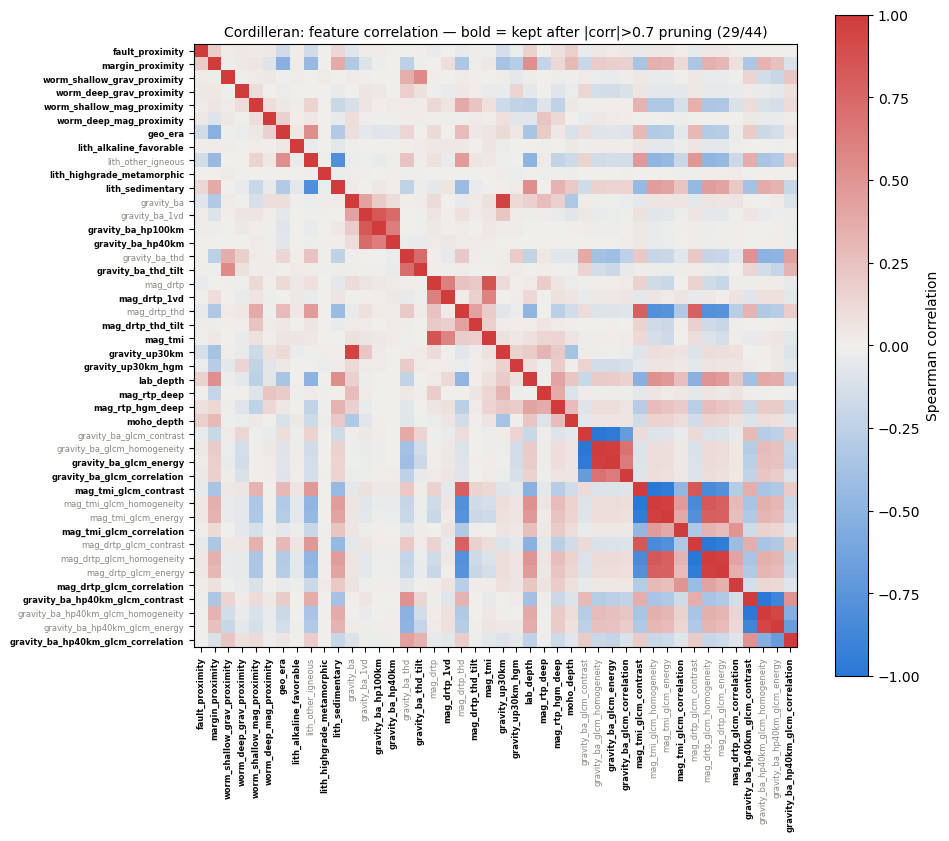

  [Cordilleran] collinearity pruning: 44 -> 29 features
  positives=29  eval_near_negatives=4000  unlabeled_pool=4000  full_features=44
  model_cfg = {'hidden': 64, 'dropout': 0.3, 'weight_decay': 0.0001}
  [Cordilleran] DevNet eval (full+pruned ablation) ≈ (n_repeats*5 + 5) * restarts * n_losses * 2 feature sets = 350 次训练
  -- RF [full, 44 feats, discriminative (positive vs. random background)] --
    pooled OOF (5-fold):        AUC=0.917  AP=0.396
    repeated pooled OOF (5x6): median AUC=0.937  95% CI=[0.919, 0.957]
  -- RF [pruned, 29 feats, discriminative (positive vs. random background)] --
    pooled OOF (5-fold):        AUC=0.904  AP=0.401
    repeated pooled OOF (5x6): median AUC=0.929  95% CI=[0.906, 0.951]
  -- DevNet(deviation) [full, 44 feats, semi-supervised (positive vs. unlabeled background)] --
    pooled OOF (5-fold):        AUC=0.895  AP=0.105
    repeated pooled OOF (5x6): median AUC=0.899  95% CI=[0.879, 0.907]
  -- DevNet(deviation) [pruned, 29 feats, semi-supervi

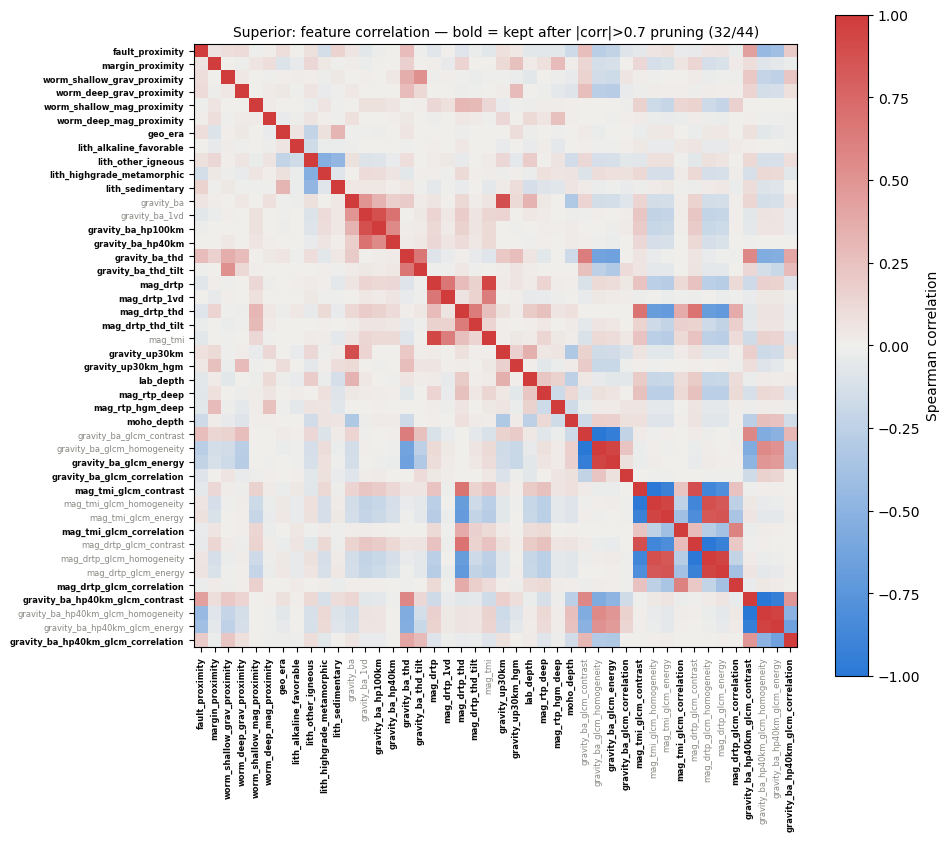

  [Superior] collinearity pruning: 44 -> 32 features
  positives=15  eval_near_negatives=4000  unlabeled_pool=4000  full_features=44
  model_cfg = {'hidden': 32, 'dropout': 0.4, 'weight_decay': 0.001}
  [Superior] DevNet eval (full+pruned ablation) ≈ (n_repeats*5 + 5) * restarts * n_losses * 2 feature sets = 350 次训练
  -- RF [full, 44 feats, discriminative (positive vs. random background)] --
    pooled OOF (5-fold):        AUC=0.953  AP=0.136
    repeated pooled OOF (5x6): median AUC=0.957  95% CI=[0.906, 0.971]
  -- RF [pruned, 32 feats, discriminative (positive vs. random background)] --
    pooled OOF (5-fold):        AUC=0.975  AP=0.175
    repeated pooled OOF (5x6): median AUC=0.964  95% CI=[0.934, 0.978]
  -- DevNet(deviation) [full, 44 feats, semi-supervised (positive vs. unlabeled background)] --
    pooled OOF (5-fold):        AUC=0.945  AP=0.368
    repeated pooled OOF (5x6): median AUC=0.944  95% CI=[0.919, 0.957]
  -- DevNet(deviation) [pruned, 32 feats, semi-supervised (po

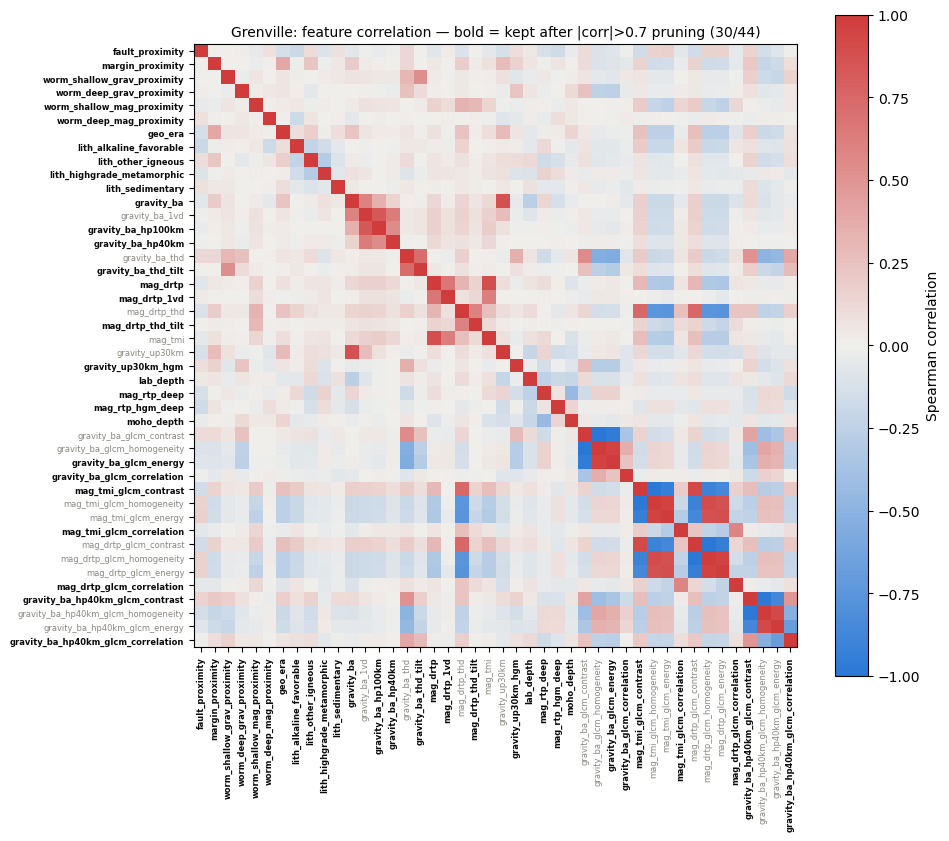

  [Grenville] collinearity pruning: 44 -> 30 features
  positives=12  eval_near_negatives=4000  unlabeled_pool=4000  full_features=44
  model_cfg = {'hidden': 32, 'dropout': 0.4, 'weight_decay': 0.001}
  [Grenville] DevNet eval (full+pruned ablation) ≈ (n_repeats*5 + 5) * restarts * n_losses * 2 feature sets = 350 次训练
  -- RF [full, 44 feats, discriminative (positive vs. random background)] --
    pooled OOF (5-fold):        AUC=0.702  AP=0.123
    repeated pooled OOF (5x6): median AUC=0.859  95% CI=[0.648, 0.903]
  -- RF [pruned, 30 feats, discriminative (positive vs. random background)] --
    pooled OOF (5-fold):        AUC=0.795  AP=0.120
    repeated pooled OOF (5x6): median AUC=0.852  95% CI=[0.740, 0.904]
  -- DevNet(deviation) [full, 44 feats, semi-supervised (positive vs. unlabeled background)] --
    pooled OOF (5-fold):        AUC=0.698  AP=0.033
    repeated pooled OOF (5x6): median AUC=0.767  95% CI=[0.698, 0.825]
  -- DevNet(deviation) [pruned, 30 feats, semi-supervised (

In [13]:
# Build worm trees once (shared across all regions)
print('Building worm KDTrees ...')
_worm_cfg  = list(REGIONS.values())[0]['worms']
WORM_TREES = build_worm_trees(_worm_cfg)

REGION_PTS   = {}
REGION_FEATS = {}   # name -> pruned (collinearity-reduced) feature list
RESULTS      = {}   # name -> model -> feature_set('full'/'pruned') -> metrics
TRAINED      = {}   # name -> production models + top candidate targets

for name in RUN_REGIONS:
    cfg = REGIONS[name]
    print(f'\n{"="*70}\n[{name}]\n{"="*70}')
    raster_cols = list(CLIPPED_RASTERS[name].keys())
    pts = build_region(name, cfg, WORM_TREES)
    REGION_PTS[name] = pts

    pts_labeled   = pts[pts['pool'].isin(['positive', 'eval_neg'])].reset_index(drop=True)
    pts_unlabeled = pts[pts['pool'] == 'train_unlabeled'].reset_index(drop=True)

    feat_cols_full = [c for c in PROXIMITY_COLS + TERRANE_COLS + raster_cols + GLCM_COLS
                      if c in pts.columns]
    pruned_cols = prune_collinear(pts, feat_cols_full, thresh=COLLINEARITY_THRESH)
    REGION_FEATS[name] = pruned_cols
    plot_collinearity_heatmap(pts, feat_cols_full, pruned_cols, name, thresh=COLLINEARITY_THRESH)
    print(f'  [{name}] collinearity pruning: {len(feat_cols_full)} -> {len(pruned_cols)} features')

    X_full_labeled,   y, feat_cols_full_out = get_raw_features(pts_labeled, raster_cols)
    X_pruned_labeled, _, feat_cols_pruned   = get_raw_features(pts_labeled, raster_cols, feat_subset=pruned_cols)
    X_full_unlabeled,   _, _ = get_raw_features(pts_unlabeled, raster_cols)
    X_pruned_unlabeled, _, _ = get_raw_features(pts_unlabeled, raster_cols, feat_subset=pruned_cols)

    n_pos, n_eval_neg = int((y == 1).sum()), int((y == 0).sum())
    print(f'  positives={n_pos}  eval_near_negatives={n_eval_neg}  '
          f'unlabeled_pool={len(pts_unlabeled)}  full_features={len(feat_cols_full_out)}')

    model_cfg = REGION_MODEL_CFG.get(name, DEFAULT_MODEL_CFG)
    n_train_est = (CV_N_REPEATS * CV_N_SPLITS + CV_N_SPLITS) * DN_RESTARTS * len(RUN_LOSSES) * 2
    print(f'  model_cfg = {model_cfg}')
    print(f'  [{name}] DevNet eval (full+pruned ablation) ≈ (n_repeats*5 + 5) * restarts'
          f' * n_losses * 2 feature sets = {n_train_est} 次训练')

    RESULTS[name] = {}
    feature_sets = {
        'full':   (X_full_labeled,   feat_cols_full_out, X_full_unlabeled),
        'pruned': (X_pruned_labeled, feat_cols_pruned,   X_pruned_unlabeled),
    }
    for model_name in ['RF'] + [f'DevNet({lt})' for lt in RUN_LOSSES]:
        RESULTS[name][model_name] = {}
        for fs_name, (X_lab, cols_fs, X_unlab) in feature_sets.items():
            if model_name == 'RF':
                scorer = rf_fold_scorer
                paradigm = 'discriminative (positive vs. random background)'
            else:
                scorer = devnet_semisup_fold_scorer_factory(X_unlab, model_cfg=model_cfg)
                paradigm = 'semi-supervised (positive vs. unlabeled background)'

            print(f'  -- {model_name} [{fs_name}, {len(cols_fs)} feats, {paradigm}] --')
            auc_oof, ap_oof, _ = pooled_oof_eval(X_lab, y, scorer)
            print(f'    pooled OOF (5-fold):        AUC={auc_oof:.3f}  AP={ap_oof:.3f}')
            rep_aucs = repeated_pooled_auc(X_lab, y, scorer)
            med, lo, hi = np.median(rep_aucs), *np.percentile(rep_aucs, [2.5, 97.5])
            print(f'    repeated pooled OOF (5x{CV_N_REPEATS}): median AUC={med:.3f}  95% CI=[{lo:.3f}, {hi:.3f}]')
            RESULTS[name][model_name][fs_name] = {
                'n_features': len(cols_fs),
                'data_paradigm': paradigm,
                'oof_auc': auc_oof, 'oof_ap': ap_oof,
                'rep_aucs': rep_aucs, 'rep_median': med, 'rep_ci': (lo, hi),
            }

    # ── Production models: PRUNED feature set only, each in its own paradigm ──
    # RF: positive + eval_neg (discriminative, same as its evaluation above).
    rf_pipeline = make_rf_pipeline()
    rf_pipeline.fit(X_pruned_labeled, y)

    # DevNet: ALL positives + the FULL unlabeled pool (semi-supervised, same
    # as its evaluation above) -- a DN_RESTARTS-model rank-averaged ensemble,
    # matching the protocol used to evaluate it.
    X_pos_pruned   = X_pruned_labeled[y == 1]
    X_dn_train_raw = np.vstack([X_pos_pruned, X_pruned_unlabeled])
    y_dn_train     = np.concatenate([np.ones(len(X_pos_pruned)), np.zeros(len(X_pruned_unlabeled))])
    dn_imputer = SimpleImputer(strategy='median').fit(X_dn_train_raw)
    dn_scaler  = StandardScaler().fit(dn_imputer.transform(X_dn_train_raw))
    X_dn_train = dn_scaler.transform(dn_imputer.transform(X_dn_train_raw))

    dn_ensemble, dn_losses = [], []
    for k in range(DN_RESTARTS):
        record = (k == 0)
        m, losses = train_devnet(X_dn_train, y_dn_train, 'deviation', seed=DN_SEED + k,
                                 model_cfg=model_cfg, record_losses=record)
        dn_ensemble.append(m)
        if record:
            dn_losses = losses

    # ── Score the unlabeled pool: DevNet's highest scorers among points it
    #    was told to treat as background are exactly the candidate new
    #    targets a semi-supervised setup is meant to surface. ────────────────
    X_unlab_scaled = dn_scaler.transform(dn_imputer.transform(X_pruned_unlabeled))
    unlab_scores = ensemble_score(dn_ensemble, X_unlab_scaled)
    top_idx = np.argsort(unlab_scores)[::-1][:TOP_N_TARGETS]
    top_targets = pts_unlabeled.iloc[top_idx][['lat', 'lon']].copy().reset_index(drop=True)
    top_targets['dn_score'] = unlab_scores[top_idx]
    top_targets.to_csv(f'{name}_top{TOP_N_TARGETS}_potential_targets_combined_dedup.csv', index=False)
    print(f'  [{name}] top {TOP_N_TARGETS} potential targets (highest DevNet score on the '
          f'unlabeled pool) -> {name}_top{TOP_N_TARGETS}_potential_targets_combined_dedup.csv')

    TRAINED[name] = {
        'pts': pts, 'feat_cols': pruned_cols, 'raster_cols': raster_cols,
        'rf_model':  rf_pipeline.named_steps['rf'],
        'rf_scaler': rf_pipeline.named_steps['scaler'],
        'rf_imp':    rf_pipeline.named_steps['imputer'],
        'dn_ensemble': dn_ensemble, 'dn_scaler': dn_scaler, 'dn_imp': dn_imputer,
        'dn_losses': dn_losses, 'model_cfg': model_cfg, 'top_targets': top_targets,
    }
    print(f'[{name}] evaluation + production fit complete '
          f'(RF: positive+near-negative | DevNet: positive+unlabeled; both use pruned features).')

print(f'\nRegions evaluated: {RUN_REGIONS}  |  Losses: {RUN_LOSSES}')
print('Pruned feature sets in REGION_FEATS, results in RESULTS, production models in TRAINED.')

## 10. DevNet Training Loss Curve (production model)

Loss curve for the first member of the final full-data DevNet ensemble
(`LOSS_TYPE`, seed=`DN_SEED`) trained per region in Section 9 — the
corrected deviation loss (or ranking loss) should show smooth, monotonic-ish
convergence rather than the noisy trace produced by resampling the reference
distribution every batch. The other `DN_RESTARTS - 1` ensemble members are
trained identically (different seeds) but without recording their loss
history.


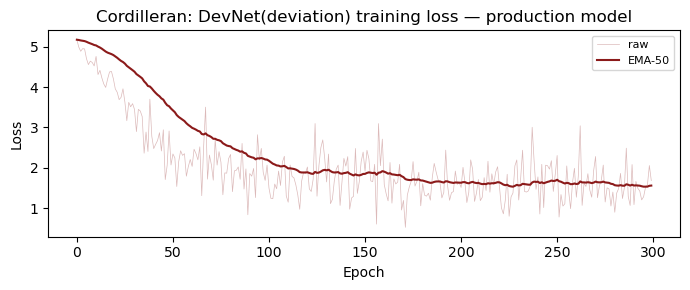

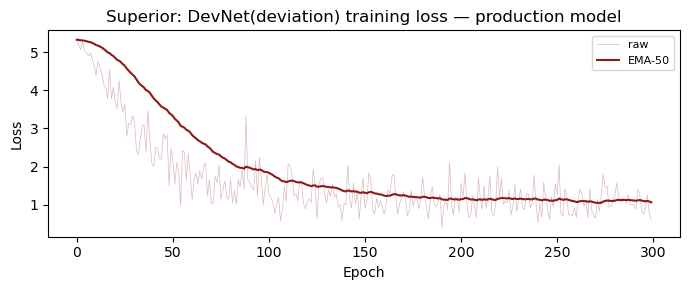

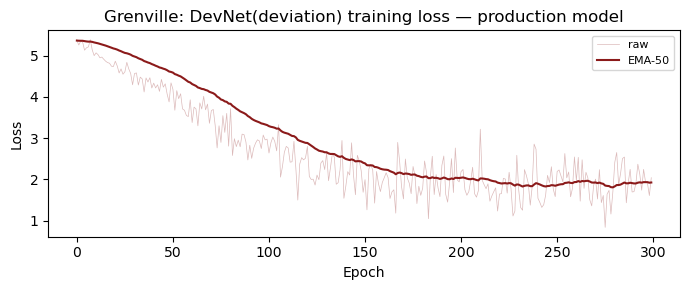

In [14]:
for name, t in TRAINED.items():
    losses = t['dn_losses']
    alpha = 2 / (50 + 1)
    ema = [losses[0]]
    for l in losses[1:]:
        ema.append(alpha * l + (1 - alpha) * ema[-1])
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.plot(losses, lw=0.5, alpha=0.3, color='#8b1a1a', label='raw')
    ax.plot(ema,    lw=1.5, color='#8b1a1a', label='EMA-50')
    ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
    ax.set_title(f'{name}: DevNet({LOSS_TYPE}) training loss — production model')
    ax.legend(fontsize=8); plt.tight_layout(); plt.show()


## 11. Comparison Table

Full-feature vs. pruned-feature ablation, exactly as in v4, plus a
**`data_paradigm`** column so RF and DevNet are never mistaken for having
been trained/evaluated on the same labels: RF is *discriminative*
(`positive` vs. `eval_neg`); DevNet is *semi-supervised*
(`positive` vs. `train_unlabeled` for training, scored against `eval_neg`).
With `FAST_MODE=True` the table only ever has the region(s) that were
actually evaluated, so it never indexes a combination that was never
computed.

**Caveat:** `eval_neg` is a random background subset of the candidate grid,
not confirmed barren ground -- it may contain a small number of undiscovered
deposits. Every AUC/AP below is therefore a conservative estimate (some
"false positives" scored against `eval_neg` could really be true positives
the survey hasn't found yet).


In [15]:
active_models = ['RF'] + [f'DevNet({lt})' for lt in RUN_LOSSES]
feature_set_names = ['full', 'pruned']

rows = []
for name in RUN_REGIONS:
    for model_name in active_models:
        for fs_name in feature_set_names:
            r = RESULTS[name][model_name][fs_name]
            rows.append({
                'region': name,
                'model': model_name,
                'data_paradigm': r['data_paradigm'],
                'feature_set': fs_name,
                'n_features': r['n_features'],
                'pooled_oof_auc': r['oof_auc'],
                'pooled_oof_ap':  r['oof_ap'],
                'repeatedCV_median_auc': r['rep_median'],
                'repeatedCV_ci_lo': r['rep_ci'][0],
                'repeatedCV_ci_hi': r['rep_ci'][1],
            })
comparison_df = pd.DataFrame(rows)

pd.set_option('display.width', 180)
print('Full vs. pruned feature-set ablation (pooled OOF / repeated-CV), by data paradigm:')
print(comparison_df.round(3).to_string(index=False))
print('\nCaveat: eval_neg is a random background subset, not confirmed barren ground -- '
      'it may contain a few undiscovered deposits, so the AUC/AP above are a conservative estimate.')


Full vs. pruned feature-set ablation (pooled OOF / repeated-CV), by data paradigm:
     region             model                                       data_paradigm feature_set  n_features  pooled_oof_auc  pooled_oof_ap  repeatedCV_median_auc  repeatedCV_ci_lo  repeatedCV_ci_hi
Cordilleran                RF     discriminative (positive vs. random background)        full          44           0.917          0.396                  0.937             0.919             0.957
Cordilleran                RF     discriminative (positive vs. random background)      pruned          29           0.904          0.401                  0.929             0.906             0.951
Cordilleran DevNet(deviation) semi-supervised (positive vs. unlabeled background)        full          44           0.895          0.105                  0.899             0.879             0.907
Cordilleran DevNet(deviation) semi-supervised (positive vs. unlabeled background)      pruned          29           0.896          0.

## 12. Prediction Map

Grid-building and panel-plotting are the original notebook's code, with two
additions: DevNet's panel label now says "semi-supervised" so the two
panels' data paradigms are visible at a glance, and the DevNet panel marks
each region's top `TOP_N_TARGETS` scored unlabeled points (`TRAINED[name]['top_targets']`)
as candidate new targets, distinct from the known-deposit markers both
panels already show. Both panels still score the grid using
`TRAINED[name]['feat_cols']` (the region's pruned feature set), so training
and the prediction map are never on different feature sets.


In [16]:
from scipy.interpolate import griddata as _griddata
from rasterio.transform import Affine as _Affine
from rasterio.features import geometry_mask as _geomask
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches

_PROSP_COLORS = ["#1a6faf", "#42c4e8", "#f5e21a", "#d73027"]

# Known-deposit confidence: same ordinal scale/colors as
# cordilleran_positive_dedup.ipynb's dep_type map -- dark = most confirmed.
# cfg['dep'] here is the combined+deduped CSV, which already carries a
# dep_type column (Deposit/Prospect / Showing / Occurrence); falls back to
# 'Unknown' (grey) if a dep source without that column is ever swapped in.
DEP_TYPE_ORDER = ['Deposit/Prospect', 'Showing', 'Occurrence']
COLOR_DEP_TYPE = {
    'Deposit/Prospect': "#811010",
    'Showing':          "#2ad633",
    'Occurrence':       '#86b6ef',
    'Unknown':          '#898781',
}


def _draw_bnd(ax, bnd_proj):
    """Draw boundary without triggering geopandas autoscale."""
    for geom in bnd_proj.geometry:
        polys = [geom] if geom.geom_type == 'Polygon' else list(geom.geoms)
        for poly in polys:
            xs, ys = poly.exterior.xy
            ax.plot(xs, ys, 'k-', lw=1.2)


def _prosp_panel(ax, proba, xs_p, ys_p, bnd_proj, dep_proj, model_name,
                 extra_pts_proj=None, extra_label='Potential target'):
    """P90/P95/P99 upper-tail classification panel. extra_pts_proj (optional,
    projected GeoDataFrame) marks additional points -- used for DevNet's
    top-scoring unlabeled candidate targets."""
    valid = proba[np.isfinite(proba)]

    bx0, by0, bx1, by1 = bnd_proj.total_bounds
    res = 5000

    y_range = np.arange(by1, by0, -res)
    x_range = np.arange(bx0, bx1,  res)
    Xi, Yi  = np.meshgrid(x_range, y_range)

    Z   = _griddata(np.column_stack([xs_p, ys_p]), proba, (Xi, Yi), method='linear')
    tfm = _Affine.translation(bx0, by1) * _Affine.scale(res, -res)
    msk = _geomask(bnd_proj.geometry, out_shape=Z.shape, transform=tfm, invert=True)
    Z   = np.where(msk, Z, np.nan)

    ext  = [bx0, bx1, by0, by1]
    bks  = [0.0,
            float(np.percentile(valid, 90)),
            float(np.percentile(valid, 95)),
            float(np.percentile(valid, 99)), 1.0]
    cmap = mcolors.ListedColormap(_PROSP_COLORS)
    norm = mcolors.BoundaryNorm(bks, len(_PROSP_COLORS))

    ax.imshow(np.ma.masked_invalid(Z), extent=ext, origin='upper',
              cmap=cmap, norm=norm, aspect='equal', alpha=0.92)
    ax.set_xlim(bx0, bx1); ax.set_ylim(by0, by1)
    _draw_bnd(ax, bnd_proj)
    dep_type_vals = (dep_proj['dep_type'].fillna('Unknown').values
                     if 'dep_type' in dep_proj.columns
                     else np.array(['Unknown'] * len(dep_proj)))
    dep_types_present = []
    for _t in DEP_TYPE_ORDER + ['Unknown']:
        _sub = dep_proj[dep_type_vals == _t]
        if len(_sub) == 0:
            continue
        ax.scatter(_sub.geometry.x, _sub.geometry.y,
                   c=COLOR_DEP_TYPE.get(_t, '#898781'), s=130, marker='*', alpha=0.85,
                   zorder=5, linewidths=0.5, edgecolors='black')
        dep_types_present.append((_t, len(_sub)))
    if extra_pts_proj is not None and len(extra_pts_proj) > 0:
        ax.scatter(extra_pts_proj.geometry.x, extra_pts_proj.geometry.y,
                   c='#eda100', s=140, marker='D', alpha=0.9, zorder=6,
                   linewidths=0.6, edgecolors='#7a5c00')

    pct = [0, 85, 90, 95, 100]
    patches = [mpatches.Patch(facecolor=_PROSP_COLORS[i], edgecolor='grey', lw=0.5,
               label=f'P{pct[i]}-P{pct[i+1]} ({bks[i]:.4f}-{bks[i+1]:.4f})')
               for i in range(4)]
    for _t, _n in dep_types_present:
        patches.append(plt.Line2D([0], [0], marker='*', color='w',
                                   markerfacecolor=COLOR_DEP_TYPE.get(_t, '#898781'),
                                   markeredgecolor='black', markeredgewidth=0.5,
                                   markersize=11, alpha=0.85, label=f'Known REE: {_t} (n={_n})'))
    if extra_pts_proj is not None and len(extra_pts_proj) > 0:
        patches.append(plt.Line2D([0], [0], marker='D', color='w',
                                   markerfacecolor='#eda100', markersize=10,
                                   alpha=0.9, label=extra_label))
    ax.legend(handles=patches, loc='lower right', fontsize=8,
              title=model_name, title_fontsize=8, framealpha=0.9)
    ax.set_title(model_name, fontsize=11, fontweight='bold')
    ax.set_xlabel('Easting (m)');  ax.set_ylabel('Northing (m)')
    ax.grid(True, alpha=0.25)
    ax.set_xlim(bx0, bx1);  ax.set_ylim(by0, by1)


def build_grid(cfg):
    """Regular prediction grid within the study area (EPSG:4326)."""
    boundary   = gpd.read_file(cfg['outline']).to_crs('EPSG:4326')
    study_area = boundary.unary_union
    xmin, ymin, xmax, ymax = boundary.total_bounds
    xs = np.arange(xmin, xmax, GRID_DEG)
    ys = np.arange(ymin, ymax, GRID_DEG)
    xx, yy = np.meshgrid(xs, ys)
    gdf = gpd.GeoDataFrame(
        geometry=gpd.points_from_xy(xx.ravel(), yy.ravel()), crs='EPSG:4326')
    gdf = gdf[gdf.within(study_area)].copy().reset_index(drop=True)
    gdf['lat'] = gdf.geometry.y
    gdf['lon'] = gdf.geometry.x
    return gdf, boundary


def predict_grid(cfg, name, rf_model, rf_scaler, rf_imputer, feat_cols,
                 dn_ensemble, dn_scaler, dn_imputer, worm_trees, top_targets=None):
    print(f'[{name}] building prediction grid ...')
    grid, boundary = build_grid(cfg)

    pts = pd.DataFrame({'lat': grid['lat'], 'lon': grid['lon']})
    pts = add_terrane_h3(pts, CLIPPED_VECTORS[name].get('h3_grid'))
    pts = add_proximity_lines(pts, cfg['faults'],  'fault')
    pts = add_proximity_lines(pts, cfg['margins'], 'margin')
    pts = add_proximity_worms(pts, worm_trees)
    pts = add_rasters(pts, CLIPPED_RASTERS[name])

    print(f'  extracting GLCM texture features for prediction grid ...')
    pts = add_glcm_features(pts, CLIPPED_RASTERS[name])

    X = pts.reindex(columns=feat_cols).astype(float).values

    X_rf     = rf_scaler.transform(rf_imputer.transform(X))
    rf_proba = rf_model.predict_proba(X_rf)[:, 1]

    X_dn = dn_scaler.transform(dn_imputer.transform(X))
    dn_proba = ensemble_score(dn_ensemble, X_dn)  # rank-averaged ensemble, already ~[0, 1]

    grid['rf_proba'] = rf_proba
    grid['dn_proba'] = dn_proba
    grid.to_file(f'{name}_prospectivity_combined_dedup.geojson', driver='GeoJSON')
    print(f'  saved → {name}_prospectivity_combined_dedup.geojson')

    grid_proj = gpd.GeoDataFrame(
        geometry=gpd.points_from_xy(grid['lon'], grid['lat']), crs='EPSG:4326'
    ).to_crs(PROJECTED_CRS)
    xs_p = grid_proj.geometry.x.values
    ys_p = grid_proj.geometry.y.values

    bnd_proj = boundary.to_crs(PROJECTED_CRS)
    dep      = pd.read_csv(cfg['dep']).dropna(subset=['Latitude', 'Longitude'])
    dep_gdf  = gpd.GeoDataFrame(
        dep,
        geometry=gpd.points_from_xy(dep['Longitude'], dep['Latitude']),
        crs='EPSG:4326',
    ).to_crs(PROJECTED_CRS)
    dep_in   = dep_gdf[dep_gdf.within(bnd_proj.unary_union)]

    # Adapt figure size to each region's geographic aspect ratio
    bx0, by0, bx1, by1 = bnd_proj.total_bounds
    _gw = bx1 - bx0;  _gh = by1 - by0  # metres
    _ph = 14  # panel height (inches, fixed)
    _pw = max(min(_ph * _gw / _gh, 14), 5)  # panel width, clamped 5–14""
    fig, axes = plt.subplots(1, 2, figsize=(_pw * 2 + 2, _ph + 1),
                             constrained_layout=True)
    fig.suptitle(f'{name} — REE Prospectivity (EPSG:3978)',
                 fontsize=14, fontweight='bold')
    top_targets_proj = None
    if top_targets is not None and len(top_targets) > 0:
        top_targets_proj = gpd.GeoDataFrame(
            top_targets,
            geometry=gpd.points_from_xy(top_targets['lon'], top_targets['lat']),
            crs='EPSG:4326',
        ).to_crs(PROJECTED_CRS)

    _prosp_panel(axes[0], rf_proba, xs_p, ys_p, bnd_proj, dep_in,
                'Random Forest (positive vs. random background)')
    _prosp_panel(axes[1], dn_proba, xs_p, ys_p, bnd_proj, dep_in,
                'DevNet (semi-supervised: positive vs. unlabeled)',
                extra_pts_proj=top_targets_proj,
                extra_label=f'Top-{TOP_N_TARGETS} unlabeled (potential target)')
    plt.show()
    return grid


### Generate prediction maps for regions in RUN_REGIONS


[Cordilleran] building prediction grid ...
  extracting GLCM texture features for prediction grid ...
    GLCM: gravity_ba → 4 texture features
    GLCM: mag_tmi → 4 texture features
    GLCM: mag_drtp → 4 texture features
    GLCM: gravity_ba_hp40km → 4 texture features
  saved → Cordilleran_prospectivity_combined_dedup.geojson


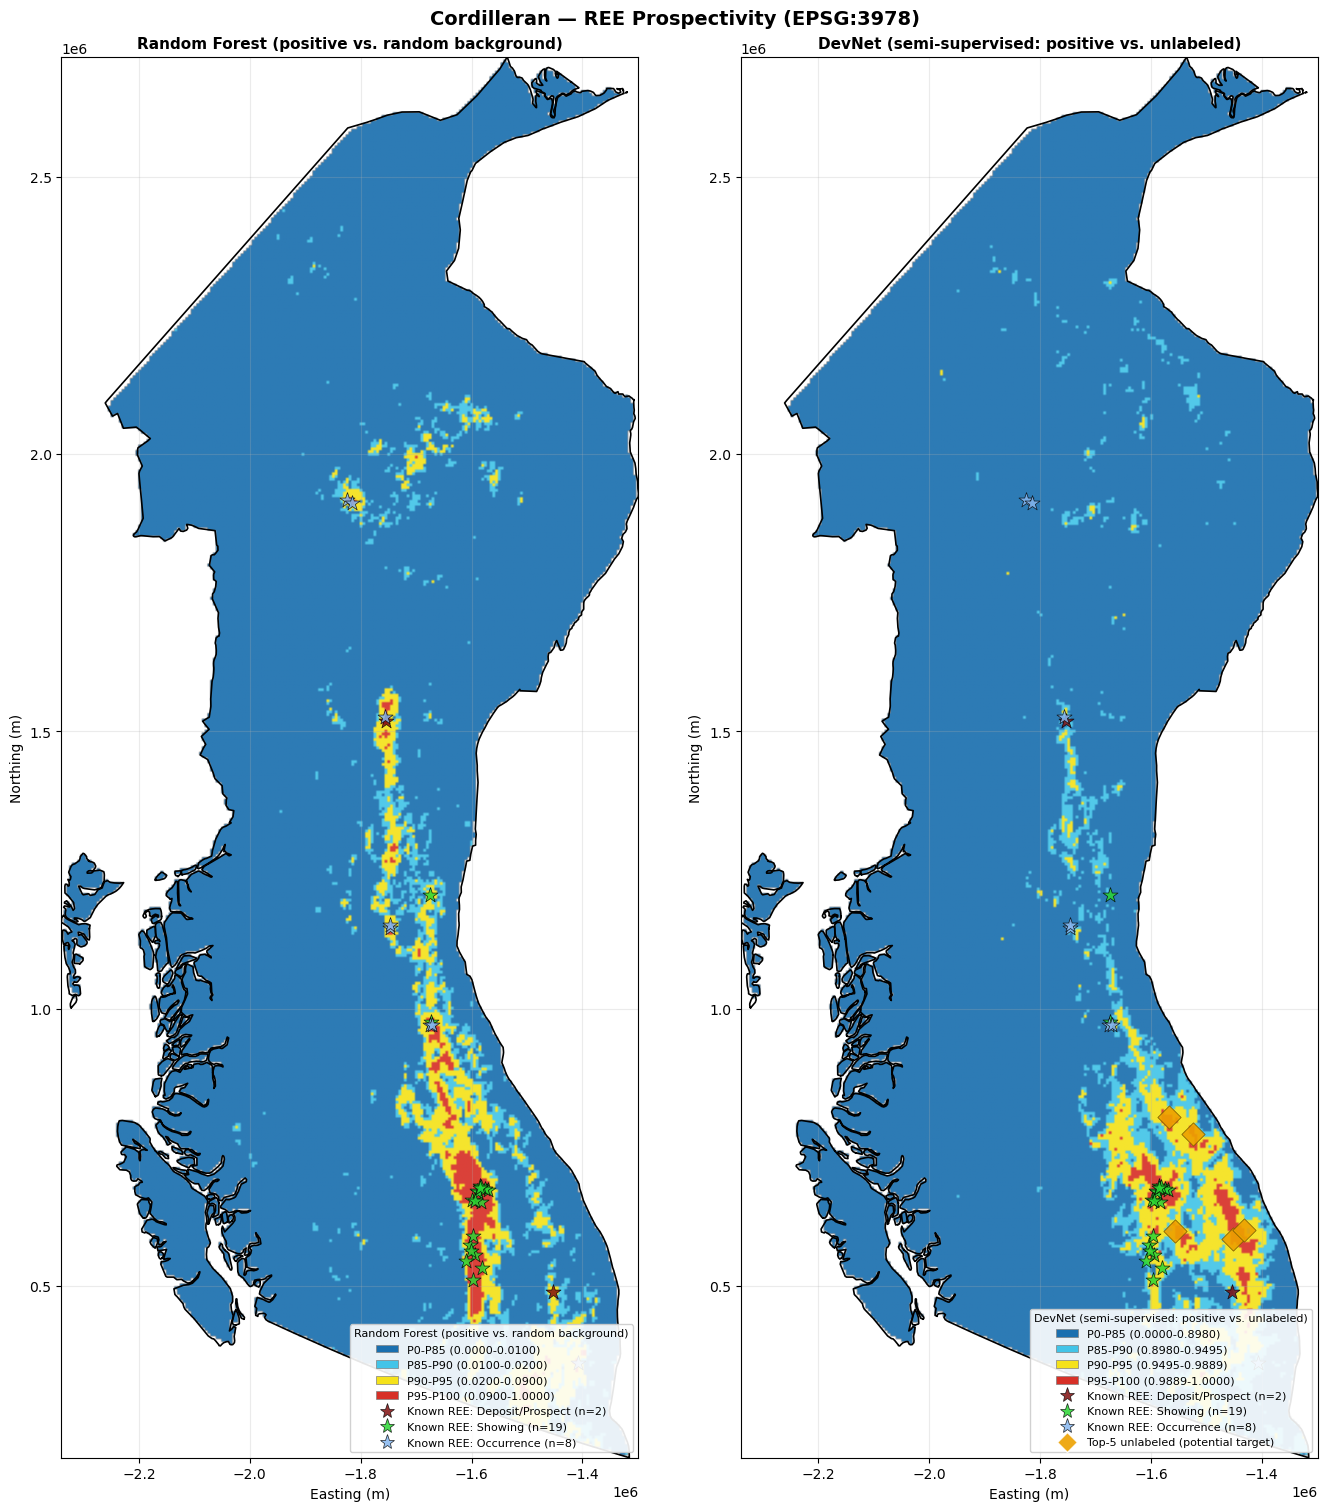

[Superior] building prediction grid ...
  extracting GLCM texture features for prediction grid ...
    GLCM: gravity_ba → 4 texture features
    GLCM: mag_tmi → 4 texture features
    GLCM: mag_drtp → 4 texture features
    GLCM: gravity_ba_hp40km → 4 texture features
  saved → Superior_prospectivity_combined_dedup.geojson


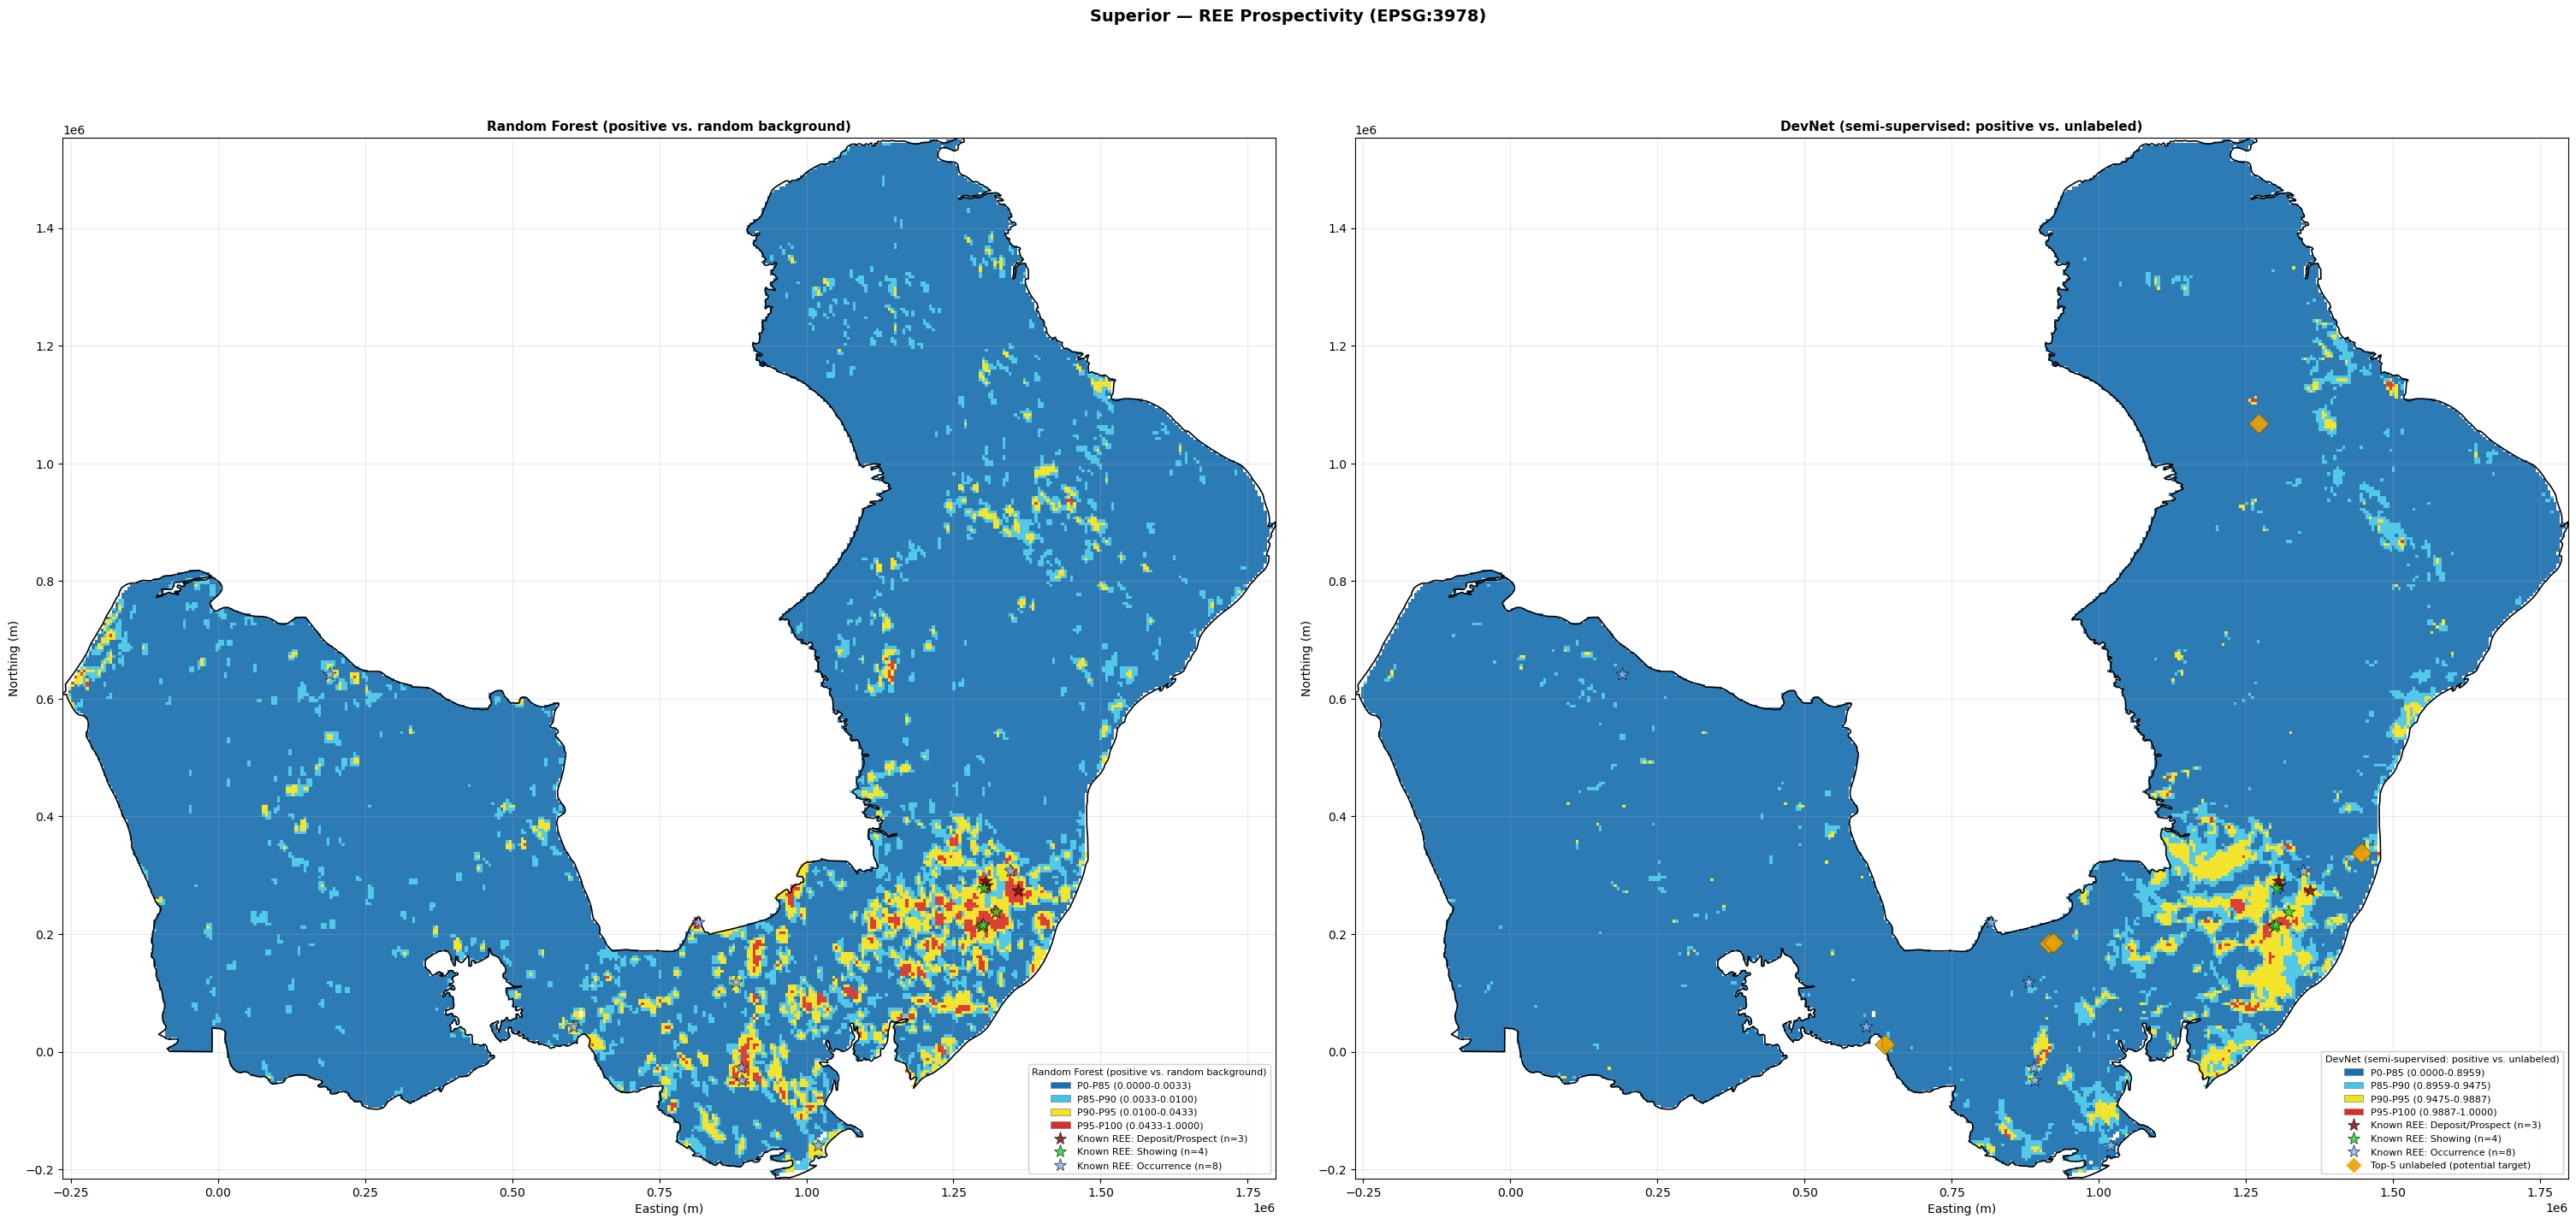

[Grenville] building prediction grid ...
  extracting GLCM texture features for prediction grid ...
    GLCM: gravity_ba → 4 texture features
    GLCM: mag_tmi → 4 texture features
    GLCM: mag_drtp → 4 texture features
    GLCM: gravity_ba_hp40km → 4 texture features
  saved → Grenville_prospectivity_combined_dedup.geojson


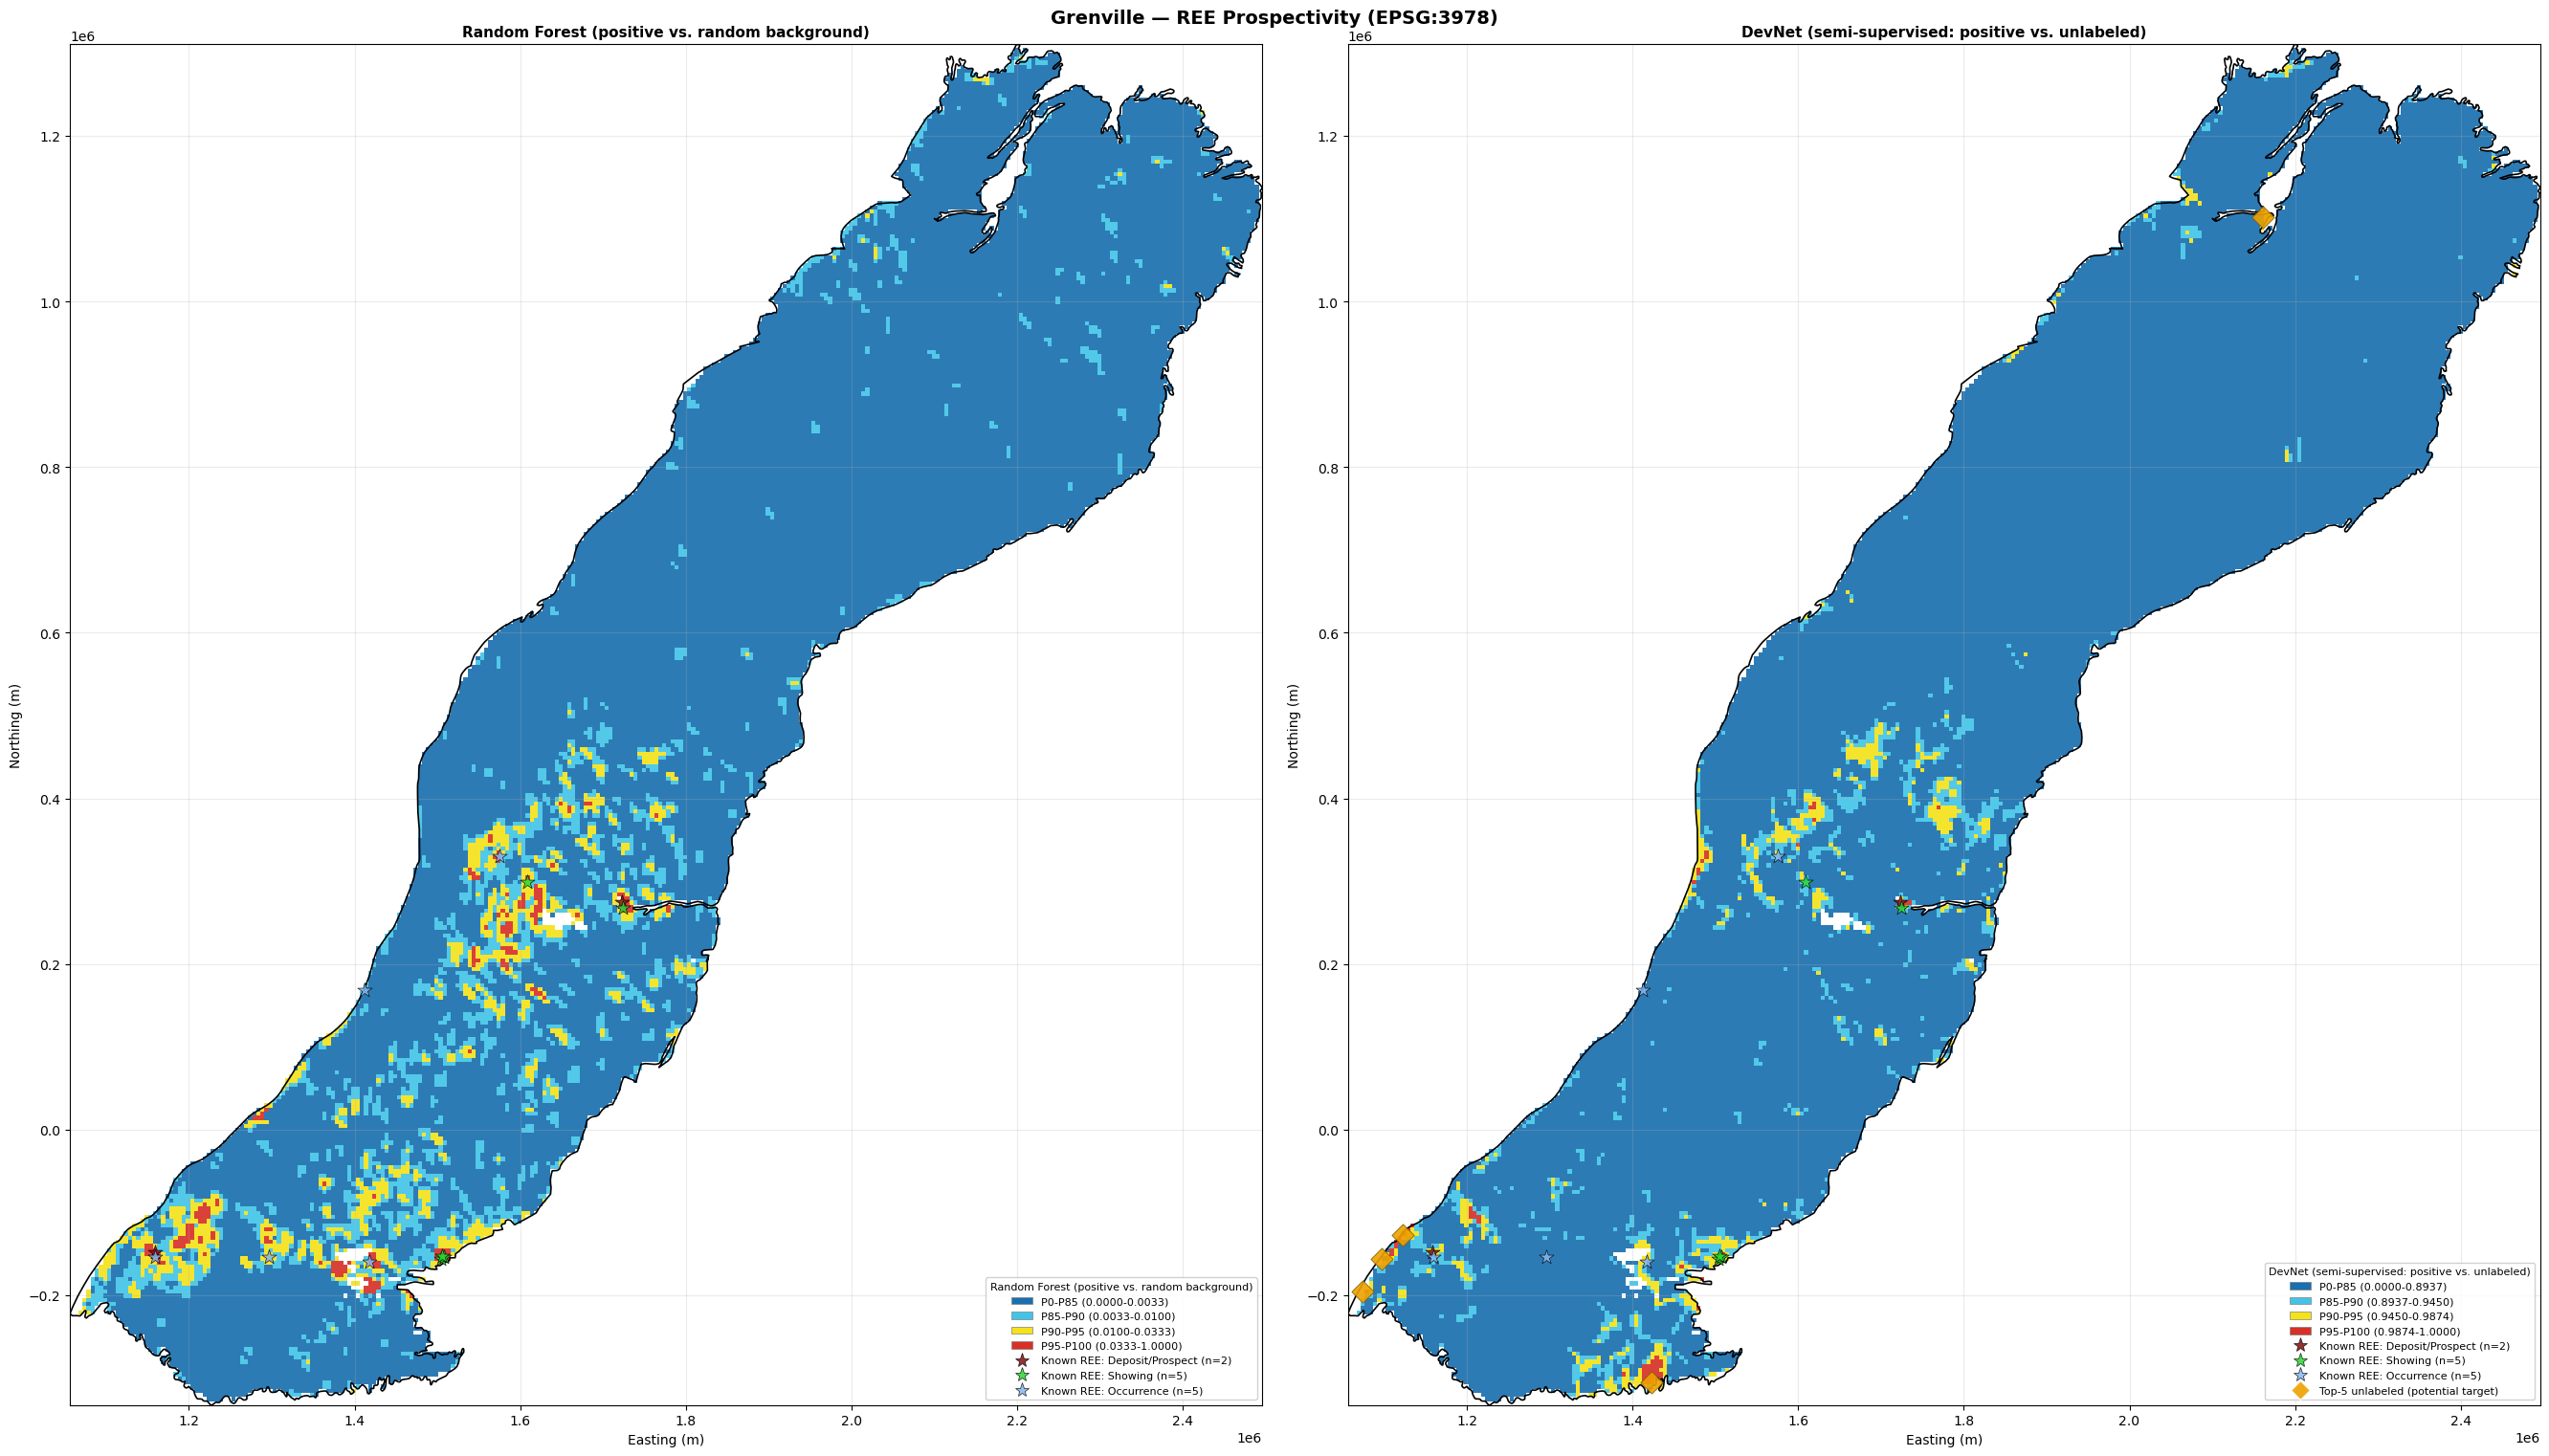

In [17]:
for name in RUN_REGIONS:
    cfg = REGIONS[name]
    t = TRAINED[name]
    grid = predict_grid(
        cfg, name,
        t['rf_model'], t['rf_scaler'], t['rf_imp'], t['feat_cols'],
        t['dn_ensemble'], t['dn_scaler'], t['dn_imp'],
        WORM_TREES, top_targets=t.get('top_targets'),
    )
    TRAINED[name]['grid'] = grid


## 13. SHAP Feature-Attribution Analysis

This section is purely **explanatory** -- it does not touch the data
pipeline, the evaluation protocol, or training logic above. It answers a
different question than Sections 9-12: not "how good is each model" but
"what did each model actually learn to pay attention to, and do RF and
DevNet agree?"

**Method:**

- **RF** -- `shap.TreeExplainer` (TreeSHAP), not impurity/Gini importance.
  Impurity importance is biased toward high-cardinality continuous features
  and isn't on a comparable scale to a neural net's attributions; TreeSHAP
  is exact for tree ensembles and produces per-sample, signed attributions
  just like DevNet's explainer does, which is what makes a fair comparison
  possible at all.
- **DevNet** -- `shap.DeepExplainer`, falling back to `GradientExplainer`
  then `KernelExplainer` if the former errors (PyTorch/SHAP version
  compatibility is fragile across releases -- see Section 13a). Only the
  **first ensemble member** (`dn_ensemble[0]`, trained with `seed=DN_SEED`)
  is explained -- it stands in for the full `DN_RESTARTS`-model ensemble
  used elsewhere in this notebook, not a separately-trained model.
- **Same features, same explain-set, model-appropriate preprocessing** --
  both models are explained on `TRAINED[name]['feat_cols']` (the region's
  pruned feature set, identical to what each model was actually trained on)
  and on the **same underlying points** (positives + a sample of `eval_neg`).
  Each model's own production `imputer`/`scaler` transforms those raw points
  before SHAP runs -- RF's `rf_imp`/`rf_scaler`, DevNet's `dn_imp`/`dn_scaler`
  -- since those were fit on different pools (RF: positive+eval_neg,
  DevNet: positive+unlabeled) and running SHAP on unprocessed raw features
  would silently mismatch what each model actually sees at inference time.

**Caveat worth keeping in mind when comparing magnitudes:** because RF's and
DevNet's scalers were fit on different underlying pools, the *numeric scale*
of "one standard deviation" differs slightly between the two models even for
the same raw feature. This does not affect within-model feature ranking or
sign/direction, which is what the comparisons below actually rely on, but it
means a strict "is RF's SHAP value 3x DevNet's" magnitude comparison isn't
perfectly apples-to-apples -- rank and direction are the meaningful part.

`FAST_MODE` controls compute here too: `True` runs SHAP on only
`RUN_REGIONS[0]` with small background/explain samples; `False` runs it for
every region in `RUN_REGIONS` with larger samples.


In [18]:
try:
    import shap
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'shap'])
    import shap

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

if FAST_MODE:
    SHAP_REGIONS   = [RUN_REGIONS[0]]
    SHAP_BG_N      = 50    # background sample size for DevNet's explainer
    SHAP_EXPLAIN_N = 60    # points (positives + eval_neg sample) SHAP is computed for
else:
    SHAP_REGIONS   = list(RUN_REGIONS)
    SHAP_BG_N      = 100
    SHAP_EXPLAIN_N = 200

print(f'shap {shap.__version__}')
print(f'SHAP_REGIONS={SHAP_REGIONS}  SHAP_BG_N={SHAP_BG_N}  SHAP_EXPLAIN_N={SHAP_EXPLAIN_N}')


shap 0.52.0
SHAP_REGIONS=['Cordilleran', 'Superior', 'Grenville']  SHAP_BG_N=100  SHAP_EXPLAIN_N=200


### 13a. Explainers

`DevNet.forward()` returns a **squeezed** `(N,)` tensor (`self.net(x).squeeze(-1)`)
-- fine for training, but it breaks `shap.DeepExplainer`/`GradientExplainer`
on this environment's PyTorch/SHAP versions (`IndexError` inside SHAP's
internals, confirmed by testing before writing this cell). `_DevNetSHAPWrapper`
below calls `base_model.net(x)` directly, skipping the squeeze so the output
stays `(N, 1)`, which both explainers expect. This changes nothing about the
model's actual predictions -- it's purely a shape adapter for SHAP.

`explain_devnet` tries `DeepExplainer` first, then `GradientExplainer`, then
falls back to the fully model-agnostic (but much slower) `KernelExplainer`
if both gradient-based explainers raise. `explain_rf` uses `TreeExplainer`
with SHAP's default `tree_path_dependent` perturbation, which needs no
explicit background sample (it uses the tree structure itself) -- simpler
and exact for tree ensembles.


In [19]:
class _DevNetSHAPWrapper(nn.Module):
    """Adapts a trained DevNet for SHAP: keeps the (N,1) output shape that
    DeepExplainer/GradientExplainer need instead of DevNet.forward()'s
    squeezed (N,) shape. Does not change what the model predicts."""
    def __init__(self, base_model):
        super().__init__()
        self.base_model = base_model
    def forward(self, x):
        return self.base_model.net(x)


def explain_rf(rf_model, X_explain):
    """TreeSHAP for the RF production model. Returns (shap_values, expected_value)
    for the positive class, shape (n_explain, n_features)."""
    explainer = shap.TreeExplainer(rf_model)
    sv = np.array(explainer.shap_values(X_explain))
    ev = explainer.expected_value
    if sv.ndim == 3:            # (n, n_features, n_classes) -- keep positive class
        sv = sv[:, :, 1]
        ev = ev[1] if np.ndim(ev) > 0 else ev
    return sv, float(np.ravel(ev)[0])


def explain_devnet(model, X_bg, X_explain, base_seed=DN_SEED):
    """DeepExplainer -> GradientExplainer -> KernelExplainer fallback chain
    for one DevNet model. Returns (shap_values, expected_value, method_name),
    shap_values shape (n_explain, n_features)."""
    torch.manual_seed(base_seed)
    wrapped = _DevNetSHAPWrapper(model).to(DEVICE).eval()
    X_bg_t = torch.tensor(X_bg, dtype=torch.float32, device=DEVICE)
    X_ex_t = torch.tensor(X_explain, dtype=torch.float32, device=DEVICE)

    for method_name, build in [
        ('DeepExplainer',     lambda: shap.DeepExplainer(wrapped, X_bg_t)),
        ('GradientExplainer', lambda: shap.GradientExplainer(wrapped, X_bg_t)),
    ]:
        try:
            explainer = build()
            sv = np.array(explainer.shap_values(X_ex_t))
            if sv.ndim == 3:
                sv = sv[..., 0]
            ev = float(np.ravel(explainer.expected_value)[0])
            return sv, ev, method_name
        except Exception as e:
            print(f'    {method_name} failed ({type(e).__name__}: {str(e)[:150]}), falling back ...')

    print('    using KernelExplainer (model-agnostic, slower) ...')
    def _f(x):
        wrapped.eval()
        with torch.no_grad():
            out = wrapped(torch.tensor(x, dtype=torch.float32, device=DEVICE))
        return out.cpu().numpy().reshape(-1)
    bg_summary = shap.kmeans(X_bg, min(10, len(X_bg)))
    explainer = shap.KernelExplainer(_f, bg_summary)
    sv = np.array(explainer.shap_values(X_explain, nsamples=100))
    if sv.ndim == 3:
        sv = sv[..., 0]
    ev = float(np.ravel(explainer.expected_value)[0])
    return sv, ev, 'KernelExplainer'


### 13b. Per-Region SHAP Computation

Explain-set construction per region: **all positives** (rare, most
interesting) plus a random sample of `eval_neg` up to `SHAP_EXPLAIN_N` total
-- the same underlying points are used for both models. DevNet's background
sample is drawn separately from the region's `train_unlabeled` pool (its own
training distribution); RF needs no explicit background (see 13a).


In [20]:
SHAP_RESULTS = {}

for name in SHAP_REGIONS:
    print(f'\n[{name}] computing SHAP ...')
    t = TRAINED[name]
    feat_cols = t['feat_cols']            # region's pruned feature set (== REGION_FEATS[name])
    raster_cols = t['raster_cols']
    pts_all = t['pts']

    pos_rows = pts_all[pts_all['pool'] == 'positive']
    eval_rows = pts_all[pts_all['pool'] == 'eval_neg']
    n_eval_needed = max(0, SHAP_EXPLAIN_N - len(pos_rows))
    eval_sample = eval_rows.sample(n=min(n_eval_needed, len(eval_rows)), random_state=RANDOM_SEED)
    explain_pts = pd.concat([pos_rows, eval_sample], ignore_index=True)

    unlabeled_rows = pts_all[pts_all['pool'] == 'train_unlabeled']
    bg_pts = unlabeled_rows.sample(n=min(SHAP_BG_N, len(unlabeled_rows)), random_state=RANDOM_SEED)

    X_explain_raw, y_explain, _ = get_raw_features(explain_pts, raster_cols, feat_subset=feat_cols)
    X_bg_raw, _, _ = get_raw_features(bg_pts, raster_cols, feat_subset=feat_cols)
    print(f'  explain set: {len(explain_pts)} points ({int((y_explain==1).sum())} positive, '
          f'{int((y_explain==0).sum())} eval_neg)  |  DevNet background: {len(bg_pts)} unlabeled points')

    # RF: same explain points, RF's own production imputer/scaler
    X_explain_rf = t['rf_scaler'].transform(t['rf_imp'].transform(X_explain_raw))
    shap_rf, ev_rf = explain_rf(t['rf_model'], X_explain_rf)

    # DevNet: same explain points (raw), but DevNet's own imputer/scaler for
    # both the explain set and the background -- and only the representative
    # ensemble member (dn_ensemble[0], seed=DN_SEED).
    X_explain_dn = t['dn_scaler'].transform(t['dn_imp'].transform(X_explain_raw))
    X_bg_dn      = t['dn_scaler'].transform(t['dn_imp'].transform(X_bg_raw))
    shap_dn, ev_dn, method_dn = explain_devnet(t['dn_ensemble'][0], X_bg_dn, X_explain_dn)
    print(f'  DevNet explainer used: {method_dn}')

    SHAP_RESULTS[name] = {
        'feat_cols': feat_cols,
        'X_explain_rf': X_explain_rf, 'shap_rf': shap_rf, 'expected_value_rf': ev_rf,
        'X_explain_dn': X_explain_dn, 'shap_dn': shap_dn, 'expected_value_dn': ev_dn,
        'devnet_method': method_dn,
        'X_bg_dn': X_bg_dn,
        'explain_pts': explain_pts,
    }

print('\nSHAP computed for:', list(SHAP_RESULTS.keys()))



[Cordilleran] computing SHAP ...
  explain set: 200 points (29 positive, 171 eval_neg)  |  DevNet background: 100 unlabeled points
  DevNet explainer used: DeepExplainer

[Superior] computing SHAP ...
  explain set: 200 points (15 positive, 185 eval_neg)  |  DevNet background: 100 unlabeled points
  DevNet explainer used: DeepExplainer

[Grenville] computing SHAP ...
  explain set: 200 points (12 positive, 188 eval_neg)  |  DevNet background: 100 unlabeled points
  DevNet explainer used: DeepExplainer

SHAP computed for: ['Cordilleran', 'Superior', 'Grenville']


### 13c. Global Feature Importance — RF vs DevNet

`mean(|SHAP value|)` per feature is the standard global-importance summary:
large values mean the feature moves the prediction a lot (in either
direction) across the explain set. Same features, same points, so the two
bars for a given feature are directly comparable within a region.


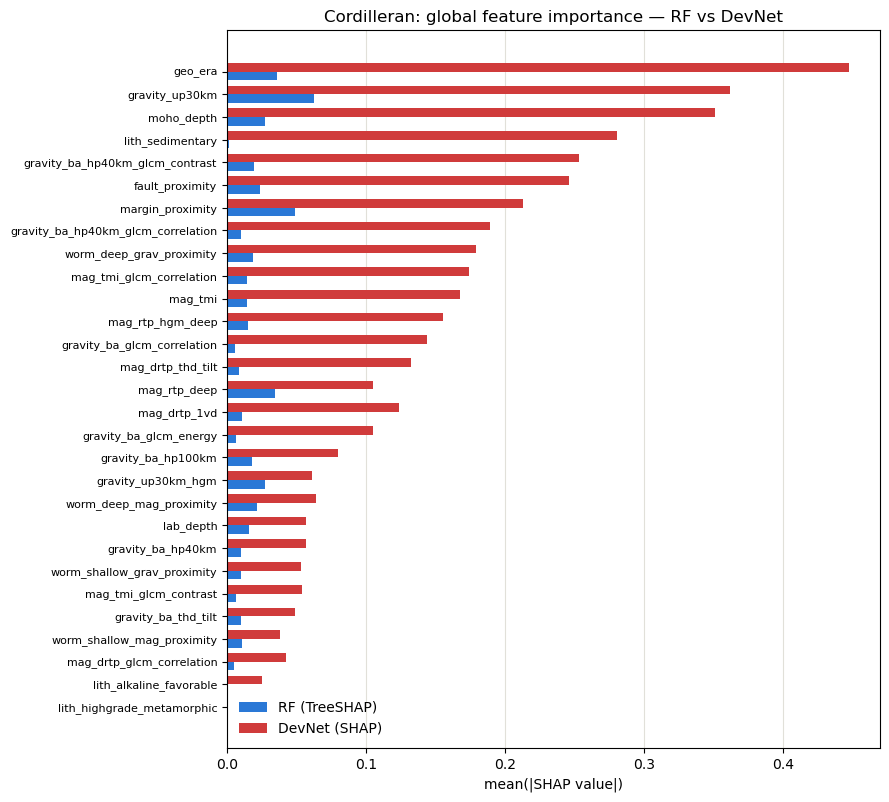

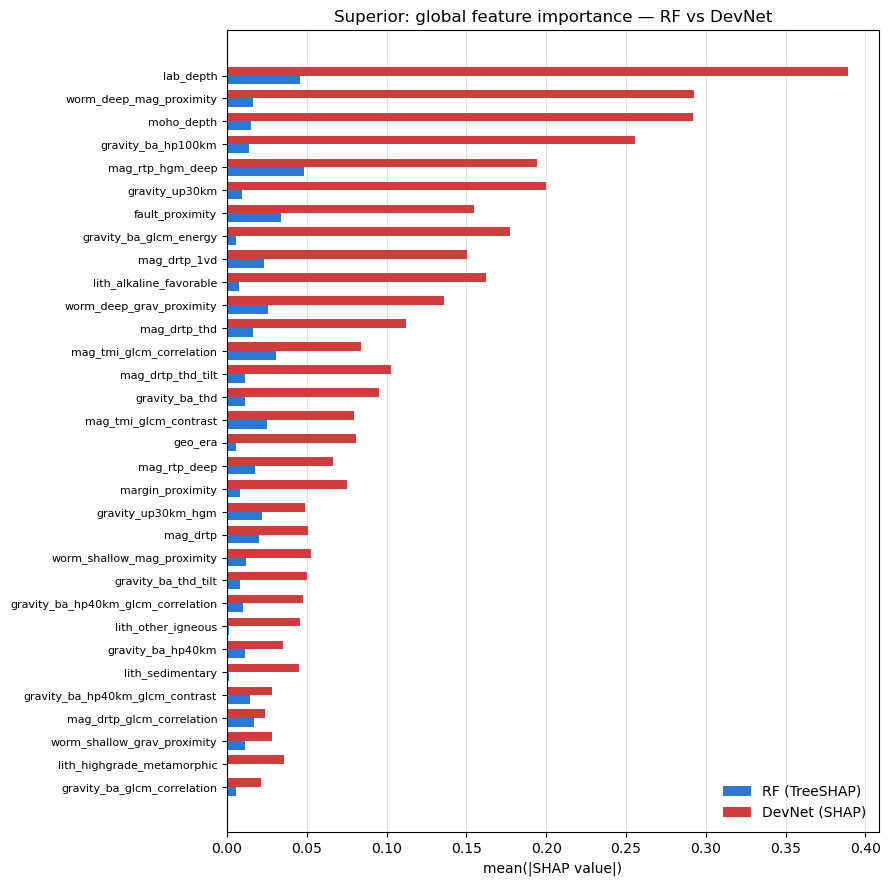

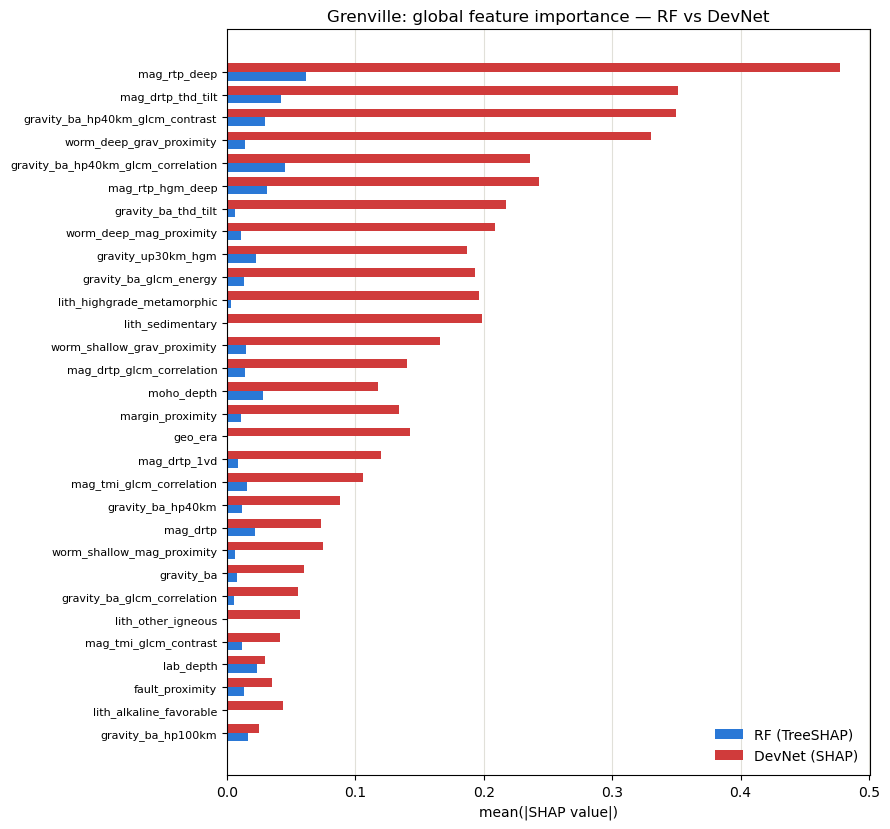

In [21]:
def plot_global_importance_comparison(shap_rf, shap_dn, feat_cols, name):
    imp_rf = np.abs(shap_rf).mean(axis=0)
    imp_dn = np.abs(shap_dn).mean(axis=0)
    order = np.argsort(-(imp_rf + imp_dn))
    feats_sorted = [feat_cols[i] for i in order]

    y = np.arange(len(feats_sorted))
    h = 0.38
    fig, ax = plt.subplots(figsize=(9, max(4, len(feats_sorted) * 0.28)))
    ax.barh(y + h / 2, imp_rf[order], height=h, color='#2a78d6', label='RF (TreeSHAP)')
    ax.barh(y - h / 2, imp_dn[order], height=h, color='#d03b3b', label='DevNet (SHAP)')
    ax.set_yticks(y); ax.set_yticklabels(feats_sorted, fontsize=8)
    ax.invert_yaxis()  # highest combined importance at top
    ax.set_xlabel('mean(|SHAP value|)')
    ax.set_title(f'{name}: global feature importance — RF vs DevNet')
    ax.legend(frameon=False)
    ax.grid(axis='x', color='#e1e0d9', lw=0.8, zorder=0)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.show()


for name in SHAP_REGIONS:
    r = SHAP_RESULTS[name]
    plot_global_importance_comparison(r['shap_rf'], r['shap_dn'], r['feat_cols'], name)


### 13d. SHAP Summary (Beeswarm) Plots

One beeswarm per model per region: each dot is one explained point, its
x-position is that point's SHAP value for the feature (row), and color is
the (scaled) feature value -- so besides magnitude, these show *direction*
per point (e.g. "high gravity anomaly pushes the prediction up, consistently,
across most points" vs. "sign flips depending on some other factor").


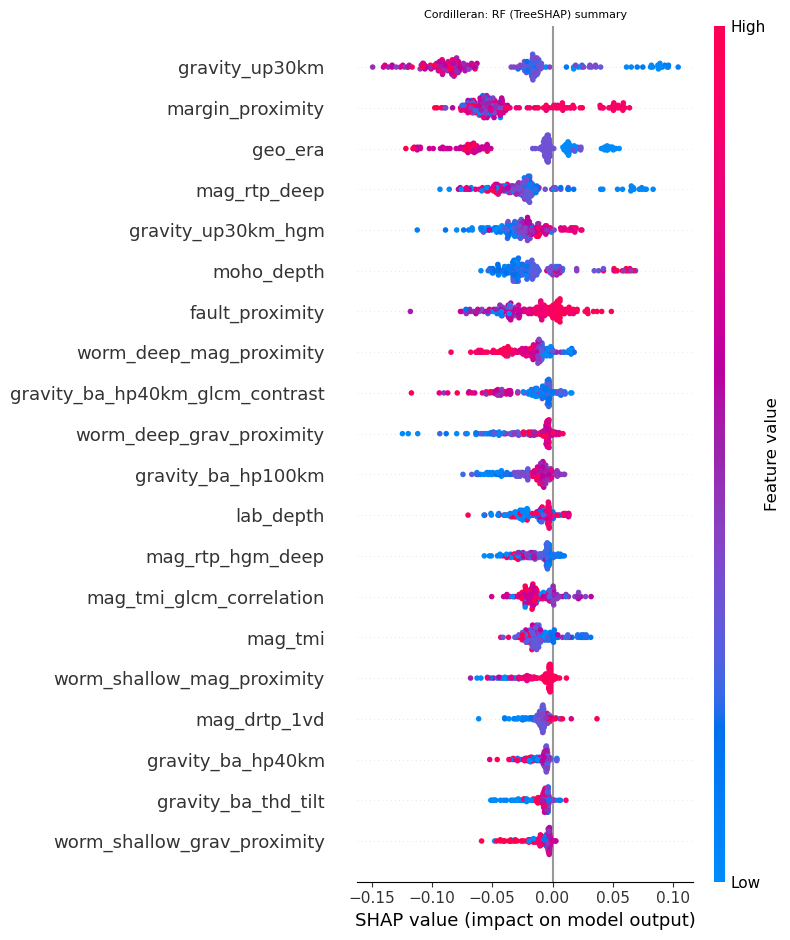

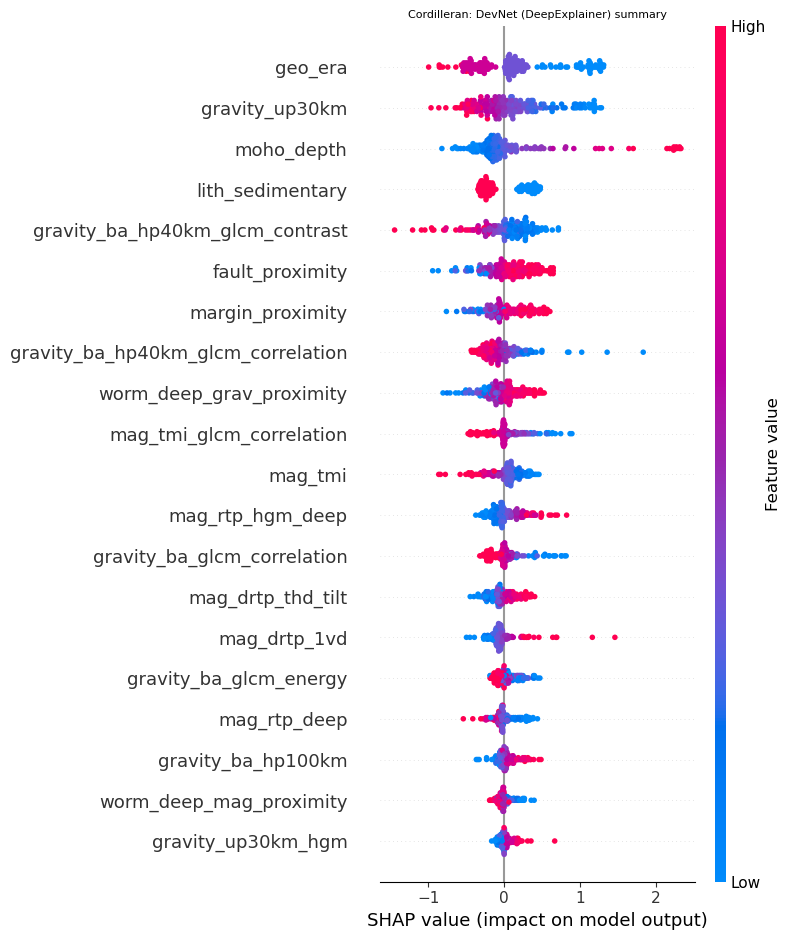

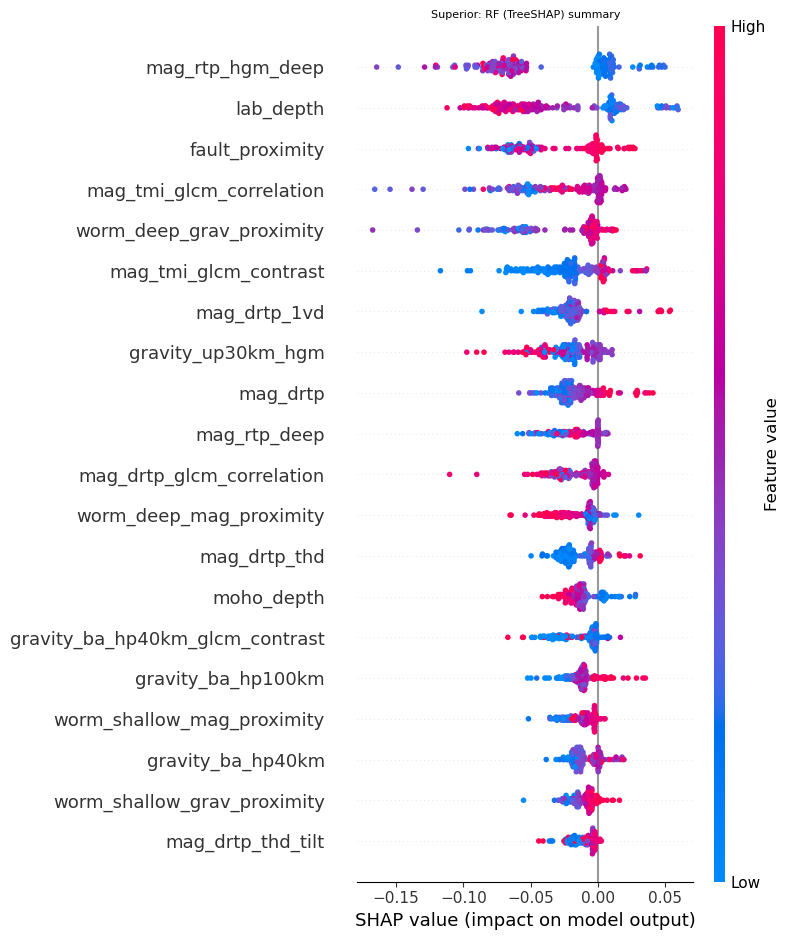

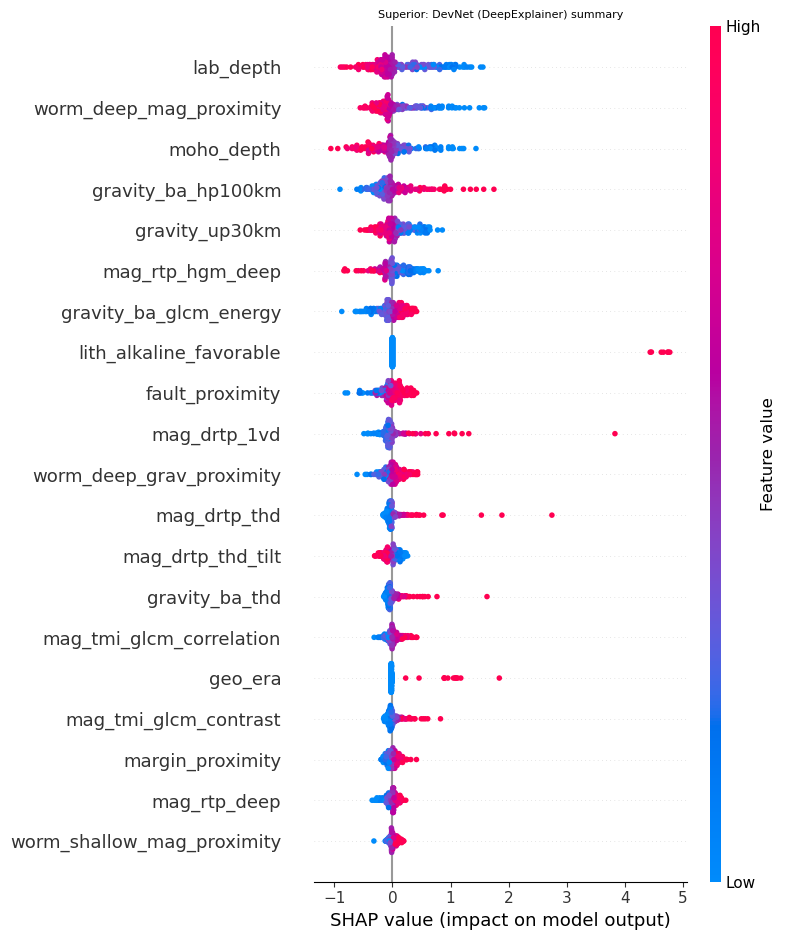

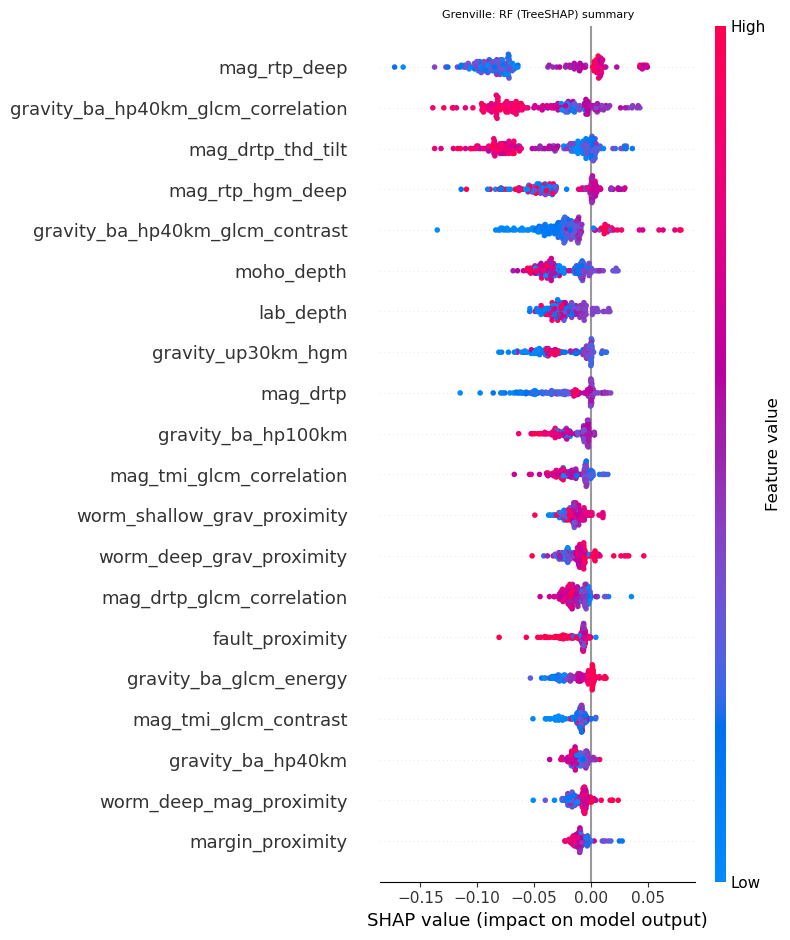

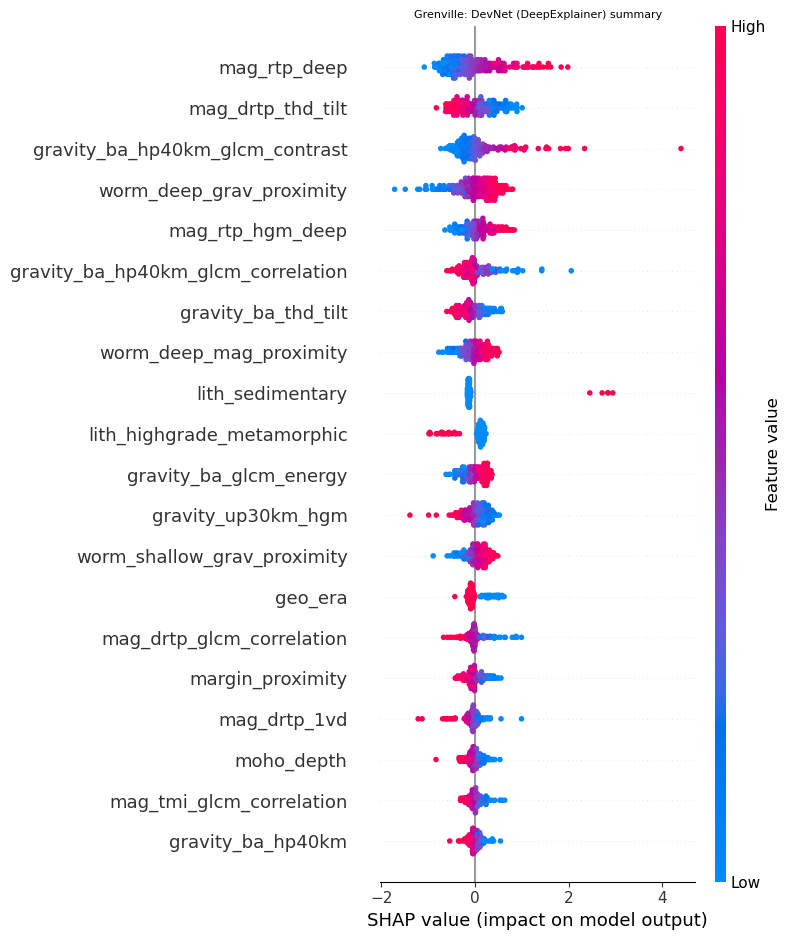

In [22]:
for name in SHAP_REGIONS:
    r = SHAP_RESULTS[name]

    plt.figure()
    shap.summary_plot(r['shap_rf'], r['X_explain_rf'], feature_names=r['feat_cols'], show=False)
    plt.title(f'{name}: RF (TreeSHAP) summary', fontsize=8)
    plt.tight_layout(); plt.show()

    plt.figure()
    shap.summary_plot(r['shap_dn'], r['X_explain_dn'], feature_names=r['feat_cols'], show=False)
    plt.title(f'{name}: DevNet ({r["devnet_method"]}) summary', fontsize=8)
    plt.tight_layout(); plt.show()


### 13e. Direction-Consistency Check

For the features that matter most to *either* model (ranked by combined
importance), this table reports each model's **average SHAP sign** --
whether a higher value of that feature pushes the prediction toward "more
prospective" or "less prospective" on average -- and flags whether the two
models agree. This is the table to check against geological intuition (e.g.
"higher gravity/magnetic anomaly should push toward more prospective" for a
carbonatite-hosted REE system) -- `direction_agree=False` rows are the
interesting ones, either a modeling artifact or a genuine RF/DevNet
disagreement worth digging into.

Caveat: "average sign" is a simplification -- a feature's effect need not be
monotonic for every point. Treat this as a summary, not a proof of
monotonic behavior.


In [23]:
def direction_consistency_table(shap_rf, shap_dn, feat_cols, top_k=10):
    imp_rf = np.abs(shap_rf).mean(axis=0)
    imp_dn = np.abs(shap_dn).mean(axis=0)
    norm_rf = imp_rf / imp_rf.max() if imp_rf.max() > 0 else imp_rf
    norm_dn = imp_dn / imp_dn.max() if imp_dn.max() > 0 else imp_dn
    top_idx = np.argsort(-(norm_rf + norm_dn))[:top_k]

    mean_rf = shap_rf.mean(axis=0)
    mean_dn = shap_dn.mean(axis=0)

    rows = []
    for i in top_idx:
        dir_rf = 'higher -> more prospective' if mean_rf[i] > 0 else 'higher -> less prospective'
        dir_dn = 'higher -> more prospective' if mean_dn[i] > 0 else 'higher -> less prospective'
        rows.append({
            'feature': feat_cols[i],
            'RF_importance': round(imp_rf[i], 4), 'RF_direction': dir_rf,
            'DevNet_importance': round(imp_dn[i], 4), 'DevNet_direction': dir_dn,
            'direction_agree': (mean_rf[i] > 0) == (mean_dn[i] > 0),
        })
    return pd.DataFrame(rows)


pd.set_option('display.width', 160)
for name in SHAP_REGIONS:
    r = SHAP_RESULTS[name]
    table = direction_consistency_table(r['shap_rf'], r['shap_dn'], r['feat_cols'])
    n_agree = int(table['direction_agree'].sum())
    print(f'\n[{name}] top {len(table)} jointly-important features -- '
          f'{n_agree}/{len(table)} agree on direction:')
    print(table.to_string(index=False))



[Cordilleran] top 10 jointly-important features -- 2/10 agree on direction:
                        feature  RF_importance               RF_direction  DevNet_importance           DevNet_direction  direction_agree
                 gravity_up30km         0.0627 higher -> less prospective             0.3622 higher -> more prospective            False
                        geo_era         0.0359 higher -> less prospective             0.4475 higher -> more prospective            False
               margin_proximity         0.0489 higher -> less prospective             0.2131 higher -> more prospective            False
                     moho_depth         0.0272 higher -> less prospective             0.3512 higher -> more prospective            False
                fault_proximity         0.0238 higher -> less prospective             0.2459 higher -> more prospective            False
gravity_ba_hp40km_glcm_contrast         0.0192 higher -> less prospective             0.2532 higher -

### 13f. Local Explanation — Top Candidate Targets

Waterfall plots for DevNet's top-scoring unlabeled points
(`TRAINED[name]['top_targets']`, capped at 5 here regardless of `TOP_N_TARGETS`)
-- which features pushed each specific candidate target above the
background baseline. This is the evidence for "these targets are
geologically plausible, not noise": if the features driving a high score are
the same ones the global analysis above says matter (and in the expected
direction), that's a much stronger argument than the score alone.


[Cordilleran] local explanation for top 5 candidate targets (DeepExplainer):


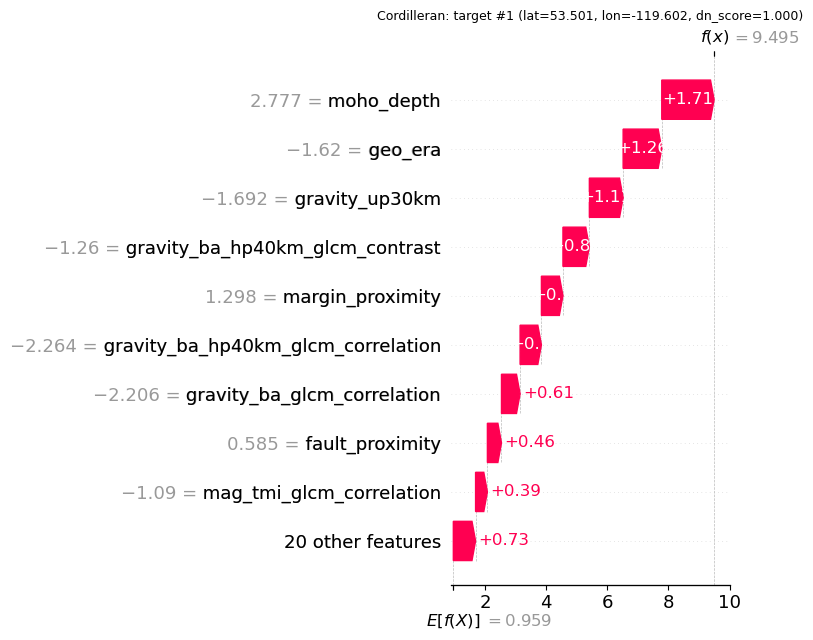

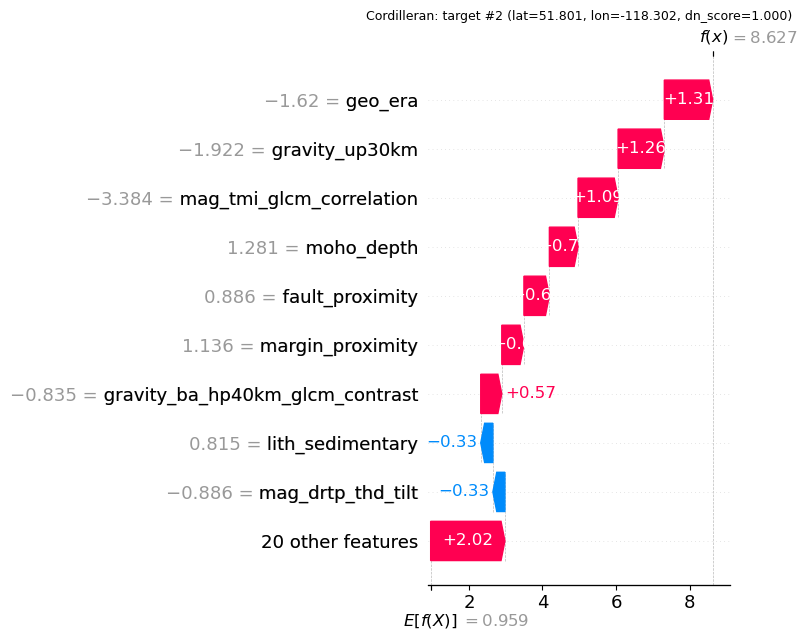

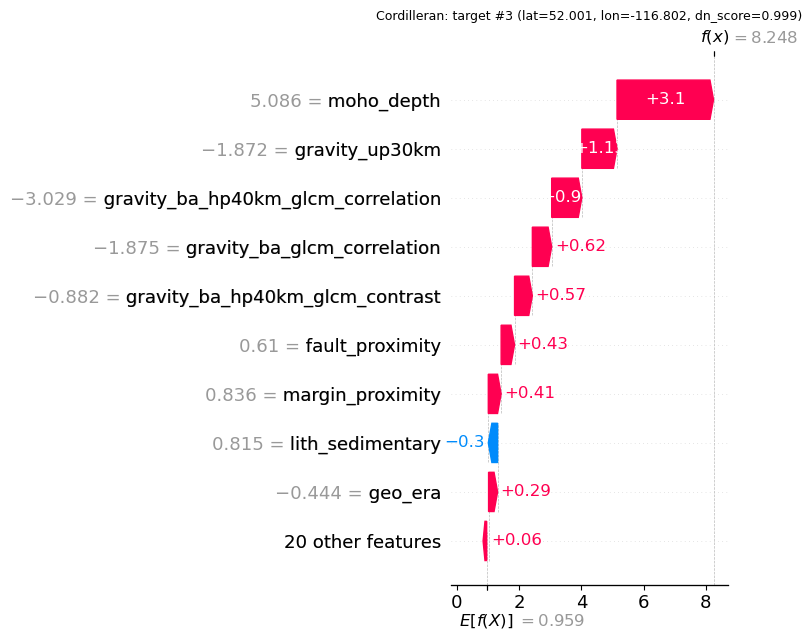

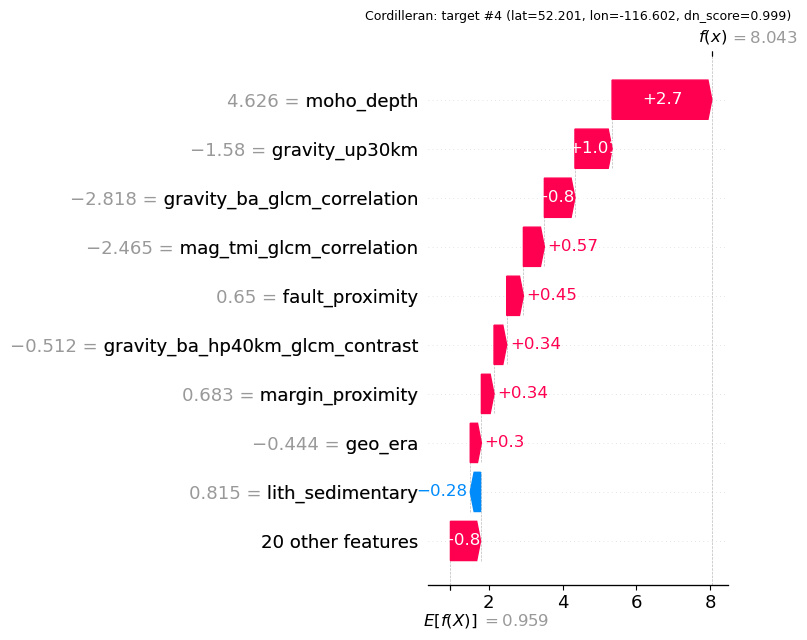

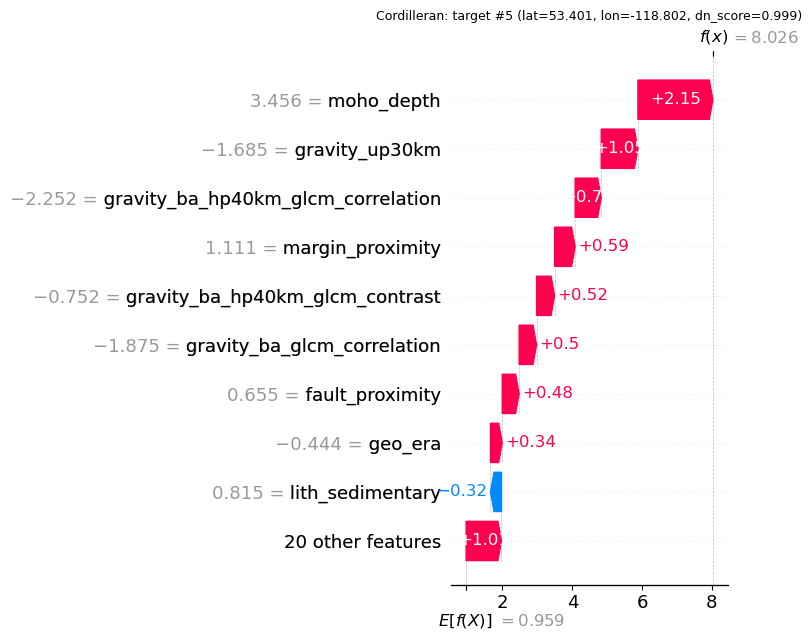

[Superior] local explanation for top 5 candidate targets (DeepExplainer):


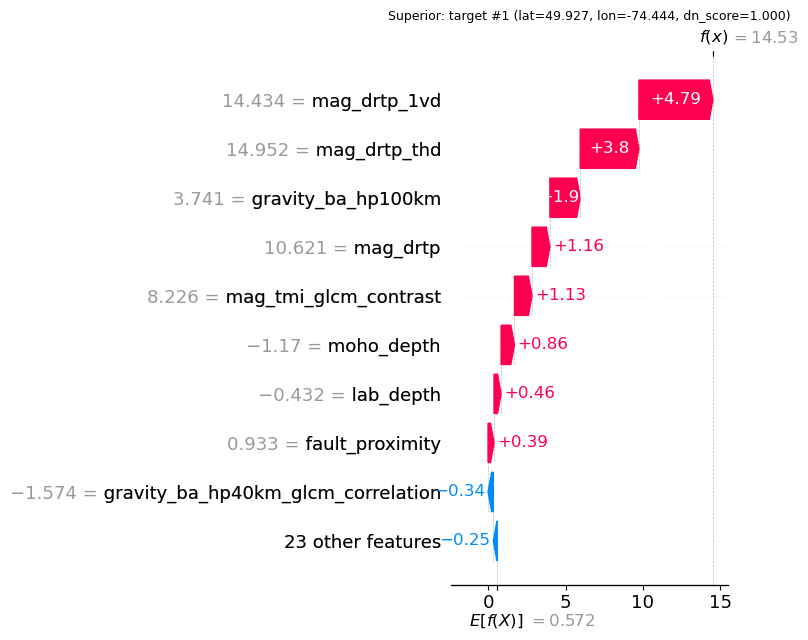

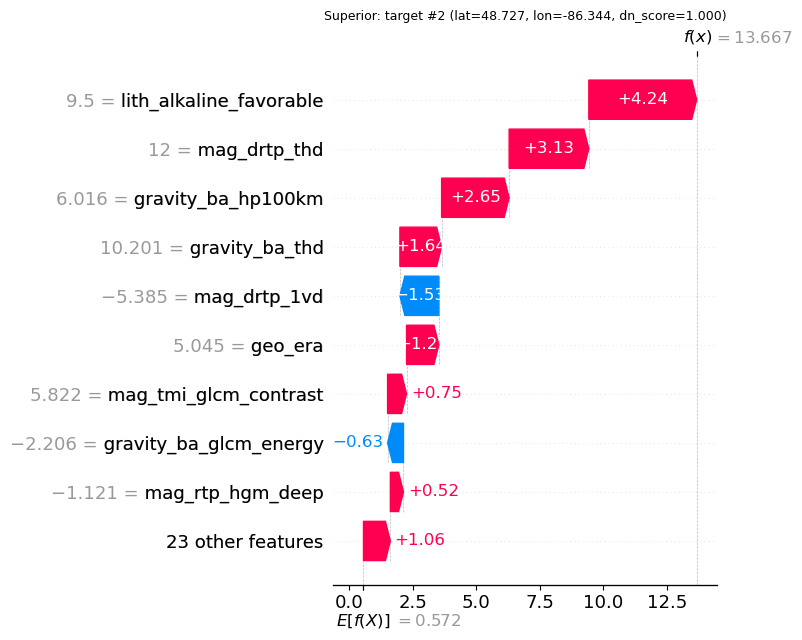

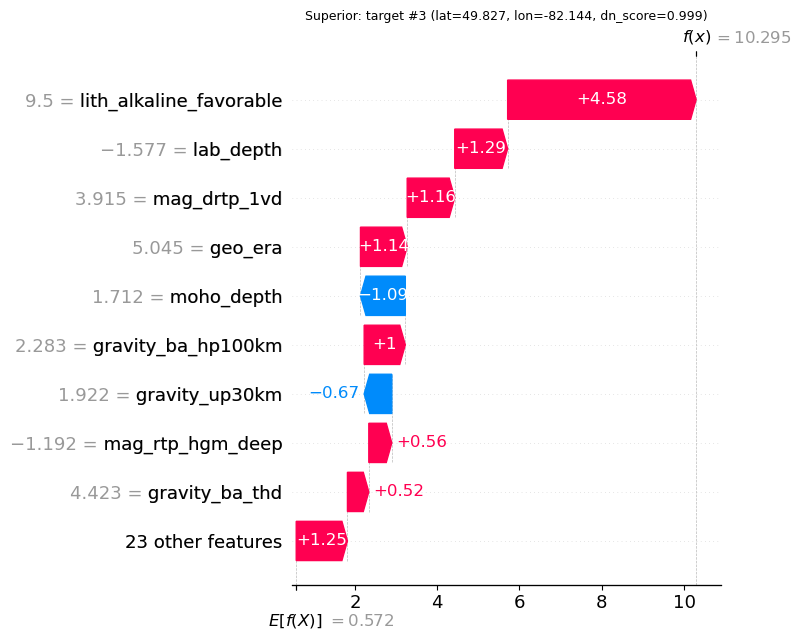

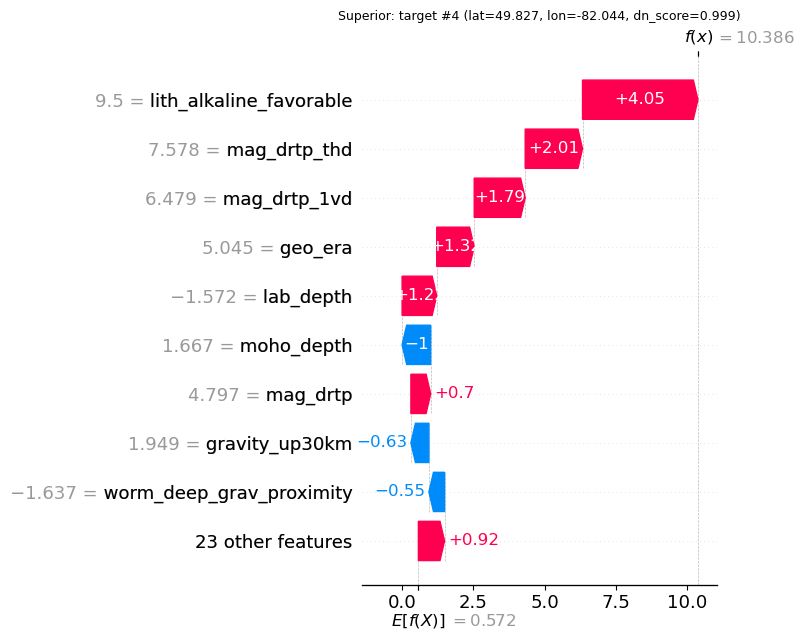

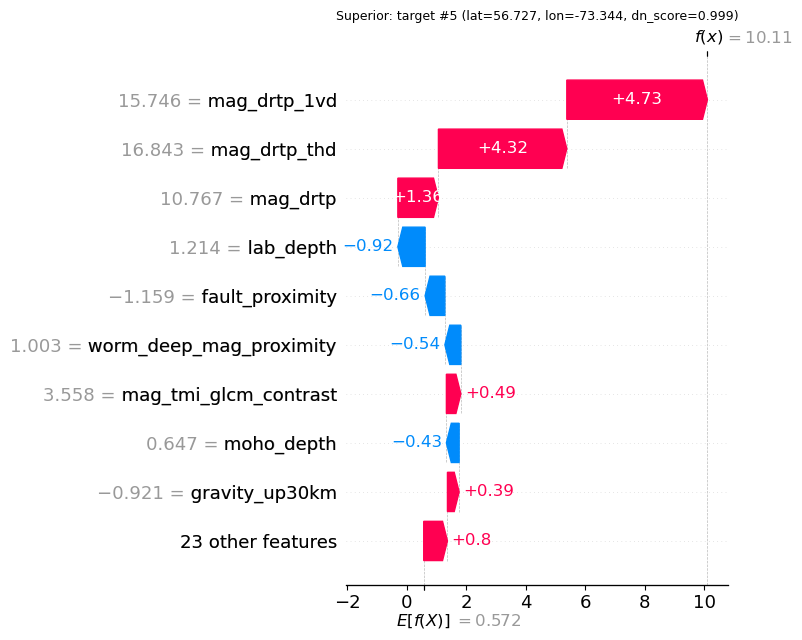

[Grenville] local explanation for top 5 candidate targets (DeepExplainer):


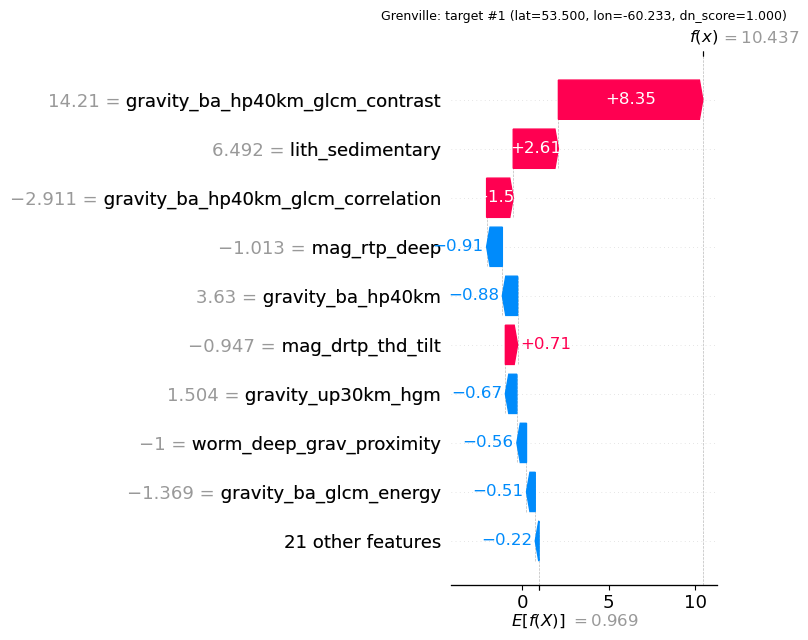

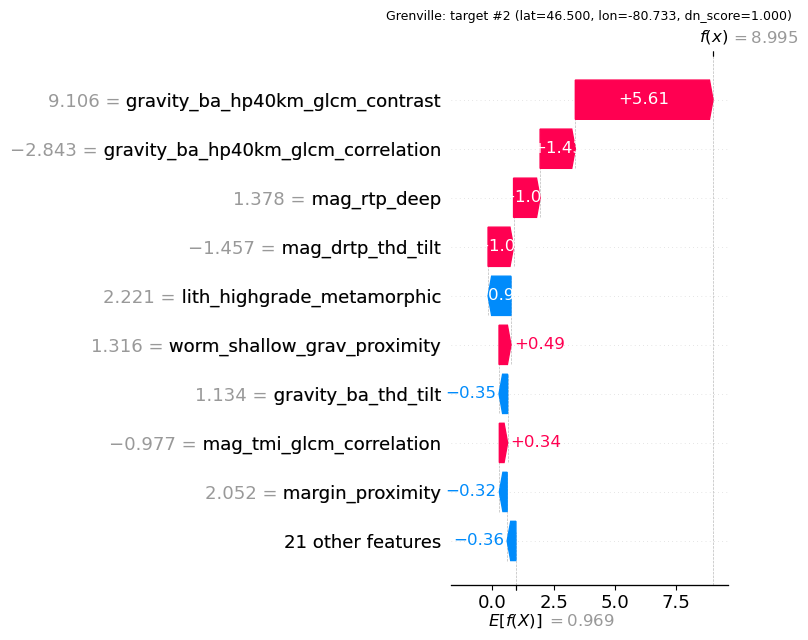

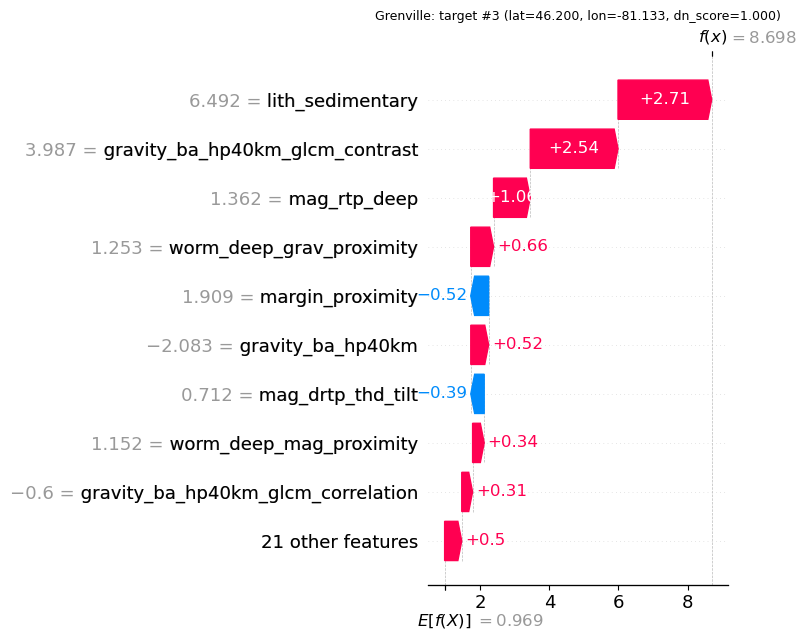

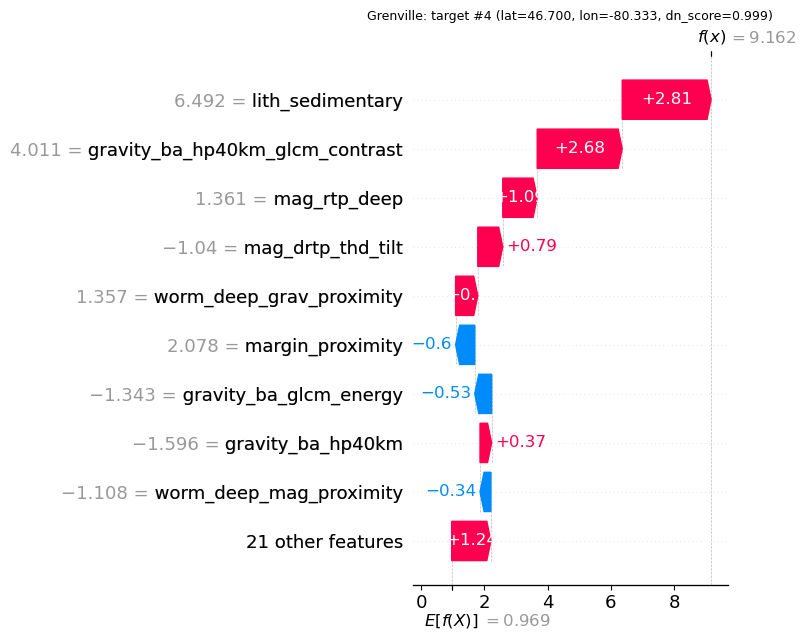

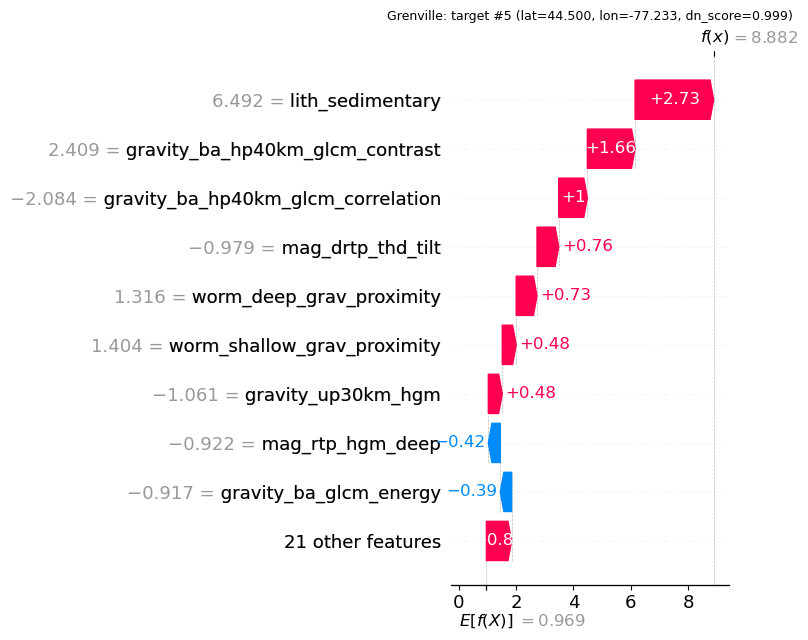

In [24]:
for name in SHAP_REGIONS:
    t = TRAINED[name]
    r = SHAP_RESULTS[name]
    top_targets = t.get('top_targets')
    if top_targets is None or len(top_targets) == 0:
        print(f'[{name}] no top_targets to explain -- skipping.')
        continue

    top_local = top_targets.sort_values('dn_score', ascending=False).head(5).reset_index(drop=True)
    pts_all = t['pts']
    top_rows = pts_all.merge(top_local[['lat', 'lon', 'dn_score']], on=['lat', 'lon'], how='inner')
    top_rows = top_rows.sort_values('dn_score', ascending=False).reset_index(drop=True)
    if len(top_rows) == 0:
        print(f'[{name}] could not match top_targets back to feature rows -- skipping.')
        continue

    X_top_raw, _, _ = get_raw_features(top_rows, t['raster_cols'], feat_subset=r['feat_cols'])
    X_top_dn = t['dn_scaler'].transform(t['dn_imp'].transform(X_top_raw))

    shap_top, ev_top, method_top = explain_devnet(t['dn_ensemble'][0], r['X_bg_dn'], X_top_dn)
    print(f'[{name}] local explanation for top {len(top_rows)} candidate targets ({method_top}):')

    for i in range(len(top_rows)):
        exp = shap.Explanation(
            values=shap_top[i], base_values=ev_top,
            data=X_top_dn[i], feature_names=r['feat_cols'],
        )
        plt.figure()  # shap.plots.waterfall draws on the current axes rather
                       # than creating its own figure -- without this, it
                       # lands on top of whatever plot preceded it.
        shap.plots.waterfall(exp, show=False)
        plt.title(f"{name}: target #{i+1} (lat={top_rows.loc[i,'lat']:.3f}, "
                  f"lon={top_rows.loc[i,'lon']:.3f}, dn_score={top_rows.loc[i,'dn_score']:.3f})",
                  fontsize=9)
        plt.tight_layout()
        plt.show()


## 14. Label-Confidence Stratification — Does RF Memorize Low-Confidence Positives?

**Question:** RF and DevNet(deviation) often *look* very different in how
confidently they score a positive — RF tends to score essentially every known
positive high, including the lowest-confidence `Occurrence` records, while
DevNet visibly deprioritizes some of them. Is that a real, measurable
pattern, or just an impression from staring at the prediction maps?

**Hypothesis:** RF discriminatively fits `positive` vs. `eval_neg` and can
simply memorize every training positive regardless of how weak its
underlying evidence is (`Occurrence` is, by the Hofstra et al. (2021)
definition this notebook's positive tables already use, the *lowest*-confidence
of the three classes — `Deposit/Prospect` > `Showing` > `Occurrence`, see
`DEP_TYPE_ORDER` / `COLOR_DEP_TYPE` in Section 12). DevNet never gets a
curated negative class to discriminate against; it only learns what the
unlabeled background typically looks like and scores deviation from it, so a
weak/ambiguous `Occurrence` point that doesn't stand out geophysically has no
mechanism forcing it to score high. If that's right, RF should score all
three occurrence-type groups about equally high, while DevNet's scores should
fall off from `Deposit/Prospect` to `Showing` to `Occurrence`.

**This section only reads already-produced artifacts** (`TRAINED`, `REGIONS`,
the fold-scorer functions from Sections 7-9, and `SHAP_RESULTS` from Section
13 if it was run) and adds analysis on top of them — it does not change
`make_points`, `build_region`, `pooled_oof_eval`, `repeated_pooled_auc`,
`rf_fold_scorer`, `devnet_semisup_fold_scorer_factory`, or any training
hyperparameter.

**Why this must use out-of-fold (OOF) scores, never the production models'
scores:** `TRAINED[name]['rf_model']` and `TRAINED[name]['dn_ensemble']` were
both *fit on every positive*, `Occurrence` included. Scoring positives with
those production models would just show RF "confidently" recognizing every
point it was trained on — that's training-set recall, not evidence about
memorization vs. generalization, and it would erase exactly the effect this
section is trying to measure. The question is "when a positive is held out
and the model has never seen it, does its confidence tier still predict how
it's scored?" — which is what OOF scoring answers and production-model
scoring cannot. Do not substitute production/training scores here.

### 14a. Occurrence-Type Labels + Repeated-CV OOF Scores (identical folds for RF and DevNet)

`get_positive_occurrence_types` re-reads each region's raw positive CSV
(`REGIONS[name]['dep']`, the same file `predict_grid`/`_prosp_panel` already
read in Section 12 to color the known-deposit star markers) and
auto-detects the occurrence-type column (`dep_type` in this dataset; also
tries `occurrence_type` / `OccurrenceType` / `type` / any column containing
"type" as a fallback, so this keeps working if the source CSV's column name
ever changes). Matching to a positive's `lat`/`lon` is by exact coordinate
(rounded to 1e-6 degrees for float safety) — those coordinates came from
this same CSV via `make_points`, unmodified, so the match is exact and any
miss is printed as a warning rather than silently dropped.

`repeated_pooled_oof_scores` is a thin variant of the existing
`repeated_pooled_auc` (Section 6): identical `RepeatedStratifiedKFold`
splitting, identical per-fold `rankdata(va_scores) / len(va_scores)`
within-fold percentile scoring — the only difference is it returns each
point's **out-of-fold score averaged across the `CV_N_REPEATS` repeats**
instead of collapsing straight to a pooled AUC. Calling it once with
`rf_fold_scorer` and once with `devnet_semisup_fold_scorer_factory` on the
exact same `(X, y, seed=RANDOM_SEED)` produces scores from **identical CV
folds** for both models — the split sequence depends only on `y` and the
seed, never on the scorer — which is what makes the RF-vs-DevNet comparison
below valid. Both use the region's **pruned** feature set, the same one the
production models and Section 9's headline numbers use.

`top_decile_flags` marks the top 10% of scores within whatever array it's
given — used below against each region's whole labeled pool
(`positive + eval_neg`) to define "hit rate".

Runs over `RUN_REGIONS`, so `FAST_MODE` controls how many regions this costs
compute on, exactly as it does in Sections 9 and 13. No new randomness is
introduced — everything reuses `CV_N_SPLITS` / `CV_N_REPEATS` / `RANDOM_SEED`.

In [25]:
_OCC_TYPE_COL_CANDIDATES = ['dep_type', 'occurrence_type', 'OccurrenceType', 'type', 'Type', 'DepType']

def _find_occurrence_type_col(df):
    """Auto-detect the occurrence-type column in a positive-sample CSV."""
    lower_map = {c.lower(): c for c in df.columns}
    for cand in _OCC_TYPE_COL_CANDIDATES:
        if cand.lower() in lower_map:
            return lower_map[cand.lower()]
    type_cols = [c for c in df.columns if 'type' in c.lower()]
    if len(type_cols) == 1:
        return type_cols[0]
    raise ValueError(f'Could not auto-detect an occurrence-type column among {list(df.columns)}')


def get_positive_occurrence_types(cfg, pos_tbl):
    """Attach each row of pos_tbl (lat/lon) its occurrence-type label
    (deposit/showing/occurrence confidence tier) by exact-coordinate match
    against the region's raw positive CSV (cfg['dep'])."""
    dep = pd.read_csv(cfg['dep']).dropna(subset=['Latitude', 'Longitude'])
    type_col = _find_occurrence_type_col(dep)
    dep_key = list(zip(np.round(dep['Latitude'].values, 6), np.round(dep['Longitude'].values, 6)))
    dep_lookup = dict(zip(dep_key, dep[type_col].values))

    pos_key = list(zip(np.round(pos_tbl['lat'].values, 6), np.round(pos_tbl['lon'].values, 6)))
    occ_type = np.array([dep_lookup.get(k, 'Unknown') for k in pos_key], dtype=object)
    n_unmatched = int((occ_type == 'Unknown').sum())
    if n_unmatched:
        print(f"    WARNING: {n_unmatched}/{len(pos_tbl)} positives could not be matched to an "
              f"occurrence-type label by lat/lon -- check {cfg['dep']!r} for coordinate drift.")
    return occ_type, type_col


def repeated_pooled_oof_scores(X_raw, y, fold_scorer, n_splits=CV_N_SPLITS,
                               n_repeats=CV_N_REPEATS, seed=RANDOM_SEED):
    """Same RepeatedStratifiedKFold(seed=seed) split sequence as
    repeated_pooled_auc, but returns each point's out-of-fold score averaged
    over all n_repeats repeats (instead of collapsing to a pooled AUC).
    Calling this with the same (X_raw, y, seed) for two different
    fold_scorers guarantees both see identical folds -- required for the
    RF-vs-DevNet comparison below to be apples-to-apples. NEVER substitute a
    production/training score here -- see the Section 14 intro."""
    rskf = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=seed)
    n = len(y)
    score_sum = np.zeros(n)
    score_cnt = np.zeros(n)
    for k, (tr_idx, va_idx) in enumerate(rskf.split(X_raw, y)):
        va_scores = fold_scorer(X_raw[tr_idx], y[tr_idx], X_raw[va_idx], seed_counter=k)
        score_sum[va_idx] += rankdata(va_scores) / len(va_scores)
        score_cnt[va_idx] += 1
    return score_sum / score_cnt


def top_decile_flags(oof_scores):
    """True where oof_scores ranks in the top 10% of the WHOLE array passed
    in (i.e. relative to the region's full labeled pool, positives + eval_neg
    pooled together) -- this is what 'hit rate' means below."""
    pct = rankdata(oof_scores) / len(oof_scores)
    return pct >= 0.90

print('Section 14 helpers ready.')

Section 14 helpers ready.


Run the repeated-CV OOF scoring for every region in `RUN_REGIONS`, using each
region's pruned feature set and production `model_cfg` (`TRAINED[name]`),
then attach each positive's occurrence-type label.

In [26]:
STRAT_POINTS = {}   # region -> DataFrame of per-positive OOF scores + occurrence_type

for name in RUN_REGIONS:
    t   = TRAINED[name]
    cfg = REGIONS[name]
    pts_all     = t['pts']
    feat_cols   = t['feat_cols']            # region's pruned feature set (production model's own)
    raster_cols = t['raster_cols']
    model_cfg   = t['model_cfg']

    pts_labeled   = pts_all[pts_all['pool'].isin(['positive', 'eval_neg'])].reset_index(drop=True)
    pts_unlabeled = pts_all[pts_all['pool'] == 'train_unlabeled'].reset_index(drop=True)

    X_lab,   y_lab, _ = get_raw_features(pts_labeled,   raster_cols, feat_subset=feat_cols)
    X_unlab, _,     _ = get_raw_features(pts_unlabeled, raster_cols, feat_subset=feat_cols)

    print(f'[{name}] repeated-CV OOF scoring ({CV_N_SPLITS}-fold x {CV_N_REPEATS} repeats, '
          f'IDENTICAL folds for RF and DevNet) ...')
    oof_rf = repeated_pooled_oof_scores(X_lab, y_lab, rf_fold_scorer, seed=RANDOM_SEED)
    dn_scorer = devnet_semisup_fold_scorer_factory(X_unlab, model_cfg=model_cfg)
    oof_dn = repeated_pooled_oof_scores(X_lab, y_lab, dn_scorer, seed=RANDOM_SEED)

    top10_rf = top_decile_flags(oof_rf)
    top10_dn = top_decile_flags(oof_dn)

    pos_mask = (y_lab == 1)
    pos_tbl  = pts_labeled[pos_mask].reset_index(drop=True)
    occ_type, type_col_used = get_positive_occurrence_types(cfg, pos_tbl)

    STRAT_POINTS[name] = pd.DataFrame({
        'region':          name,
        'lat':             pos_tbl['lat'].values,
        'lon':             pos_tbl['lon'].values,
        'occurrence_type': occ_type,
        'rf_oof_score':    oof_rf[pos_mask],
        'rf_top10pct':     top10_rf[pos_mask],
        'dn_oof_score':    oof_dn[pos_mask],
        'dn_top10pct':     top10_dn[pos_mask],
    })
    print(f"  [{name}] occurrence-type column detected: {type_col_used!r}  "
          f"counts: {STRAT_POINTS[name]['occurrence_type'].value_counts().to_dict()}")

STRAT_POSITIVES = (pd.concat(STRAT_POINTS.values(), ignore_index=True)
                   if STRAT_POINTS else pd.DataFrame())
print(f'\nTotal positives with OOF scores across {len(STRAT_POINTS)} region(s): {len(STRAT_POSITIVES)}')

[Cordilleran] repeated-CV OOF scoring (5-fold x 6 repeats, IDENTICAL folds for RF and DevNet) ...
  [Cordilleran] occurrence-type column detected: 'dep_type'  counts: {'Showing': 19, 'Occurrence': 8, 'Deposit/Prospect': 2}
[Superior] repeated-CV OOF scoring (5-fold x 6 repeats, IDENTICAL folds for RF and DevNet) ...
  [Superior] occurrence-type column detected: 'dep_type'  counts: {'Occurrence': 8, 'Showing': 4, 'Deposit/Prospect': 3}
[Grenville] repeated-CV OOF scoring (5-fold x 6 repeats, IDENTICAL folds for RF and DevNet) ...
  [Grenville] occurrence-type column detected: 'dep_type'  counts: {'Occurrence': 5, 'Showing': 5, 'Deposit/Prospect': 2}

Total positives with OOF scores across 3 region(s): 56


### 14b. Stratified Hit-Rate Table

For each occurrence-type group (`Deposit/Prospect` / `Showing` /
`Occurrence`), reports `n`, each model's mean OOF score, and each model's
**hit rate** — the fraction of that group's positives whose OOF score lands
in the top 10% of the region's whole labeled pool (`top_decile_flags` above,
computed against `positive + eval_neg` pooled together, i.e. "would this
point have ranked among the top-decile prospectivity scores when it was held
out"). One table per region, plus one for all three regions' positives
pooled together.

Expected under the hypothesis: RF's hit rate is high and similar across all
three groups (it memorized them at training time regardless of confidence
tier); DevNet's hit rate decreases `Deposit/Prospect > Showing > Occurrence`.

In [27]:
def stratified_hitrate_table(df, order=DEP_TYPE_ORDER):
    rows = []
    for grp in order:
        sub = df[df['occurrence_type'] == grp]
        if len(sub) == 0:
            continue
        rows.append({
            'occurrence_type':         grp,
            'n':                       len(sub),
            'RF_oof_mean':             sub['rf_oof_score'].mean(),
            'RF_hitrate_top10pct':     sub['rf_top10pct'].mean(),
            'DevNet_oof_mean':         sub['dn_oof_score'].mean(),
            'DevNet_hitrate_top10pct': sub['dn_top10pct'].mean(),
        })
    return pd.DataFrame(rows)

pd.set_option('display.width', 160)
STRAT_TABLES = {}
for name in RUN_REGIONS:
    STRAT_TABLES[name] = stratified_hitrate_table(STRAT_POINTS[name])
    print(f'\n[{name}] stratified hit-rate table:')
    print(STRAT_TABLES[name].round(3).to_string(index=False))

STRAT_TABLE_COMBINED = stratified_hitrate_table(STRAT_POSITIVES)
print('\n[All regions combined] stratified hit-rate table:')
print(STRAT_TABLE_COMBINED.round(3).to_string(index=False))


[Cordilleran] stratified hit-rate table:
 occurrence_type  n  RF_oof_mean  RF_hitrate_top10pct  DevNet_oof_mean  DevNet_hitrate_top10pct
Deposit/Prospect  2        0.830                0.500            0.872                    0.500
         Showing 19        0.969                0.947            0.956                    0.895
      Occurrence  8        0.780                0.625            0.749                    0.500

[Superior] stratified hit-rate table:
 occurrence_type  n  RF_oof_mean  RF_hitrate_top10pct  DevNet_oof_mean  DevNet_hitrate_top10pct
Deposit/Prospect  3        0.987                  1.0            0.981                     1.00
         Showing  4        0.932                  1.0            0.979                     1.00
      Occurrence  8        0.940                  1.0            0.887                     0.75

[Grenville] stratified hit-rate table:
 occurrence_type  n  RF_oof_mean  RF_hitrate_top10pct  DevNet_oof_mean  DevNet_hitrate_top10pct
Deposit/Prospec

### 14c. Stratified Boxplots (paper figure)

RF (blue) vs. DevNet (red) OOF score by occurrence-type tier, one figure per
region and one for all three regions combined. Individual points are
jittered on top of each box since several groups have single-digit `n`
(especially `Deposit/Prospect` — see the counts printed above); with that
few points a boxplot alone can be misleading, so every underlying point stays
visible. The dashed line marks the top-10% threshold used for the hit-rate
table above. Colors match Section 13's RF-vs-DevNet SHAP comparison plots
(`#2a78d6` / `#d03b3b`) for visual consistency across the notebook's figures.

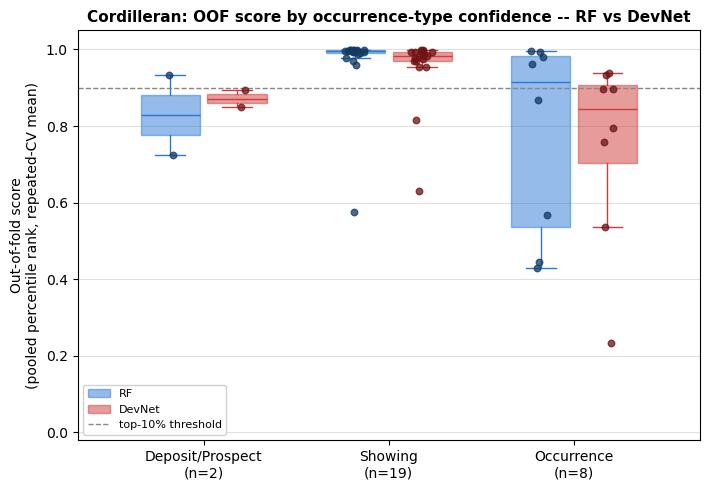

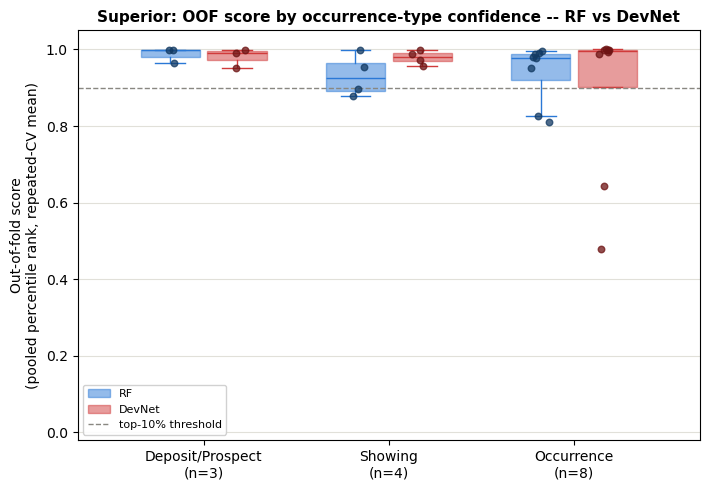

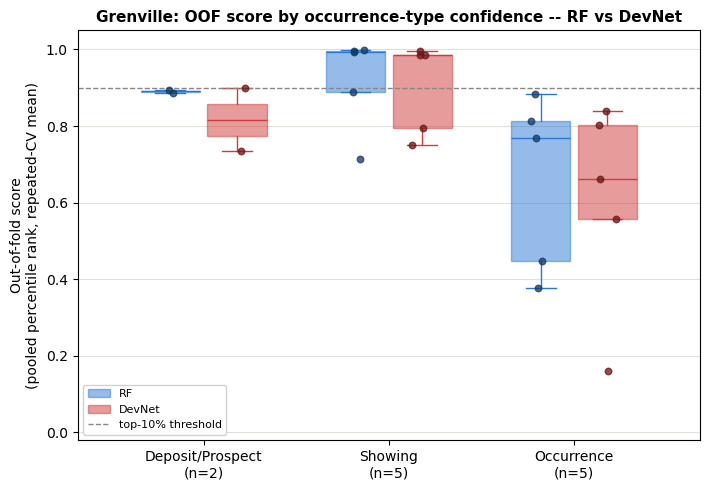

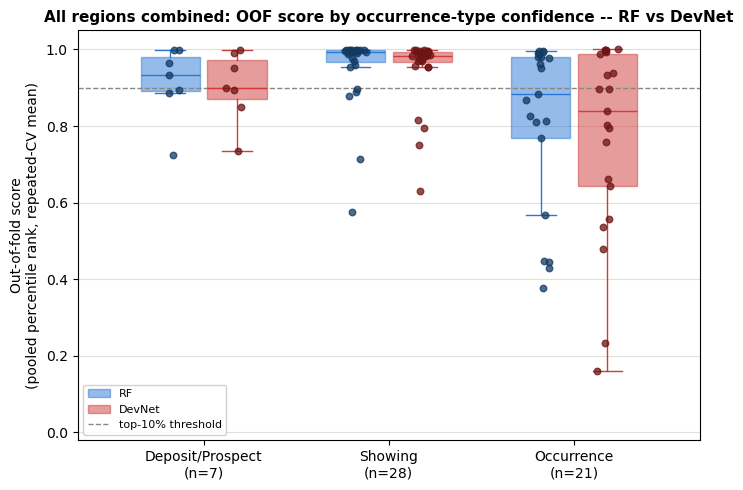

In [28]:
def plot_stratified_boxplot(df, title, order=DEP_TYPE_ORDER):
    order = [g for g in order if (df['occurrence_type'] == g).any()]
    if not order:
        print(f'  [{title}] no occurrence-type groups present -- skipping plot.')
        return

    pos_rf = np.arange(len(order)) - 0.18
    pos_dn = np.arange(len(order)) + 0.18
    rf_data = [df.loc[df['occurrence_type'] == g, 'rf_oof_score'].values for g in order]
    dn_data = [df.loc[df['occurrence_type'] == g, 'dn_oof_score'].values for g in order]

    fig, ax = plt.subplots(figsize=(max(6, len(order) * 2.4), 5))
    bp_rf = ax.boxplot(rf_data, positions=pos_rf, widths=0.32, patch_artist=True, showfliers=False)
    bp_dn = ax.boxplot(dn_data, positions=pos_dn, widths=0.32, patch_artist=True, showfliers=False)
    for box in bp_rf['boxes']:
        box.set(facecolor='#2a78d6', alpha=0.5, edgecolor='#2a78d6')
    for box in bp_dn['boxes']:
        box.set(facecolor='#d03b3b', alpha=0.5, edgecolor='#d03b3b')
    for element in ['whiskers', 'caps', 'medians']:
        for line in bp_rf[element]:
            line.set(color='#2a78d6')
        for line in bp_dn[element]:
            line.set(color='#d03b3b')

    jitter_rng = np.random.RandomState(RANDOM_SEED)
    for i, g in enumerate(order):
        yv_rf = df.loc[df['occurrence_type'] == g, 'rf_oof_score'].values
        ax.scatter(jitter_rng.normal(pos_rf[i], 0.03, size=len(yv_rf)), yv_rf,
                  color='#123a63', s=22, alpha=0.75, zorder=5)
        yv_dn = df.loc[df['occurrence_type'] == g, 'dn_oof_score'].values
        ax.scatter(jitter_rng.normal(pos_dn[i], 0.03, size=len(yv_dn)), yv_dn,
                  color='#6e1414', s=22, alpha=0.75, zorder=5)

    ax.axhline(0.90, color='#898781', ls='--', lw=1)
    ax.set_xticks(np.arange(len(order)))
    ax.set_xticklabels([f'{g}\n(n={int((df["occurrence_type"] == g).sum())})' for g in order])
    ax.set_ylabel('Out-of-fold score\n(pooled percentile rank, repeated-CV mean)')
    ax.set_ylim(-0.02, 1.05)
    ax.set_title(title, fontsize=11, fontweight='bold')
    legend_handles = [
        mpatches.Patch(facecolor='#2a78d6', alpha=0.5, edgecolor='#2a78d6', label='RF'),
        mpatches.Patch(facecolor='#d03b3b', alpha=0.5, edgecolor='#d03b3b', label='DevNet'),
        plt.Line2D([0], [0], color='#898781', ls='--', lw=1, label='top-10% threshold'),
    ]
    ax.legend(handles=legend_handles, loc='lower left', fontsize=8, framealpha=0.9)
    ax.grid(axis='y', color='#e1e0d9', lw=0.8, zorder=0)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.show()

for name in RUN_REGIONS:
    plot_stratified_boxplot(STRAT_POINTS[name],
                            f'{name}: OOF score by occurrence-type confidence -- RF vs DevNet')

if len(STRAT_POSITIVES) > 0:
    plot_stratified_boxplot(STRAT_POSITIVES,
                            'All regions combined: OOF score by occurrence-type confidence -- RF vs DevNet')

### 14d. Mann-Whitney U Test — Occurrence vs. Deposit/Prospect

Non-parametric (no normality assumption, appropriate for these small `n`)
one-sided test of `H1: Deposit/Prospect OOF scores > Occurrence OOF scores`,
run separately for RF and for DevNet, per region and for the three regions
combined. Reports `U` and `p`. If either group has fewer than 3 points the
test is skipped and flagged as not testable rather than reporting a
misleadingly precise p-value off 1-2 points.

In [29]:
from scipy.stats import mannwhitneyu

def mannwhitney_deposit_vs_occurrence(df, score_col, label):
    dep = df.loc[df['occurrence_type'] == 'Deposit/Prospect', score_col].values
    occ = df.loc[df['occurrence_type'] == 'Occurrence',       score_col].values
    if len(dep) < 3 or len(occ) < 3:
        print(f'    {label}: n_deposit={len(dep)}, n_occurrence={len(occ)} -- '
              f'fewer than 3 in one group, skipping Mann-Whitney U (not testable).')
        return None
    U, p = mannwhitneyu(dep, occ, alternative='greater')  # H1: deposit scores > occurrence scores
    flag = '[SIGNIFICANT p<0.05]' if p < 0.05 else '[not significant]'
    print(f'    {label}: deposit(n={len(dep)}) vs occurrence(n={len(occ)})  '
          f'U={U:.1f}  p={p:.4f}  {flag}')
    return {'U': float(U), 'p': float(p), 'n_deposit': len(dep), 'n_occurrence': len(occ)}

STRAT_TESTS = {}
print('Mann-Whitney U, H1 = Deposit/Prospect OOF score > Occurrence OOF score (one-sided):')
for name in RUN_REGIONS:
    print(f'\n[{name}]')
    STRAT_TESTS[name] = {
        'RF':     mannwhitney_deposit_vs_occurrence(STRAT_POINTS[name], 'rf_oof_score', 'RF'),
        'DevNet': mannwhitney_deposit_vs_occurrence(STRAT_POINTS[name], 'dn_oof_score', 'DevNet'),
    }

print('\n[All regions combined]')
STRAT_TESTS['combined'] = {
    'RF':     mannwhitney_deposit_vs_occurrence(STRAT_POSITIVES, 'rf_oof_score', 'RF'),
    'DevNet': mannwhitney_deposit_vs_occurrence(STRAT_POSITIVES, 'dn_oof_score', 'DevNet'),
}

Mann-Whitney U, H1 = Deposit/Prospect OOF score > Occurrence OOF score (one-sided):

[Cordilleran]
    RF: n_deposit=2, n_occurrence=8 -- fewer than 3 in one group, skipping Mann-Whitney U (not testable).
    DevNet: n_deposit=2, n_occurrence=8 -- fewer than 3 in one group, skipping Mann-Whitney U (not testable).

[Superior]
    RF: deposit(n=3) vs occurrence(n=8)  U=19.0  p=0.0970  [not significant]
    DevNet: deposit(n=3) vs occurrence(n=8)  U=11.0  p=0.6121  [not significant]

[Grenville]
    RF: n_deposit=2, n_occurrence=5 -- fewer than 3 in one group, skipping Mann-Whitney U (not testable).
    DevNet: n_deposit=2, n_occurrence=5 -- fewer than 3 in one group, skipping Mann-Whitney U (not testable).

[All regions combined]
    RF: deposit(n=7) vs occurrence(n=21)  U=93.0  p=0.1606  [not significant]
    DevNet: deposit(n=7) vs occurrence(n=21)  U=92.0  p=0.1739  [not significant]


### 14e. Auto-Generated One-Line Conclusion

Reads `STRAT_TESTS` above and prints, per region and for the combined pool,
one sentence stating whether the RF-memorizes / DevNet-is-robust hypothesis
is supported, contradicted, or untestable given the available `n` — the
sentence this section exists to produce for the write-up.

In [30]:
def _fmt_p(r):
    return f"p={r['p']:.4f}" if r is not None else 'not testable (n<3)'

print('=== Summary ===')
for name in list(RUN_REGIONS) + ['combined']:
    rf_r, dn_r = STRAT_TESTS[name]['RF'], STRAT_TESTS[name]['DevNet']
    rf_sig = (rf_r is not None) and (rf_r['p'] < 0.05)
    dn_sig = (dn_r is not None) and (dn_r['p'] < 0.05)

    if dn_sig and not rf_sig:
        verdict = (f'DevNet significantly down-weights low-confidence occurrence-type positives '
                  f'({_fmt_p(dn_r)}), while RF does not ({_fmt_p(rf_r)}), indicating RF memorizes '
                  f'low-quality labels whereas DevNet is robust to label noise.')
    elif dn_sig and rf_sig:
        verdict = (f'Both models significantly down-weight occurrence-type positives '
                  f'(RF {_fmt_p(rf_r)}, DevNet {_fmt_p(dn_r)}) -- the hypothesized RF/DevNet '
                  f'asymmetry is not supported here.')
    elif not dn_sig and not rf_sig:
        verdict = (f'Neither model shows a significant deposit-vs-occurrence gap '
                  f'(RF {_fmt_p(rf_r)}, DevNet {_fmt_p(dn_r)}) -- likely underpowered (small n) '
                  f'rather than evidence against the hypothesis.')
    else:
        verdict = (f'RF shows a significant gap ({_fmt_p(rf_r)}) but DevNet does not '
                  f'({_fmt_p(dn_r)}) -- the opposite of the hypothesized direction.')
    print(f'[{name}] {verdict}')

=== Summary ===
[Cordilleran] Neither model shows a significant deposit-vs-occurrence gap (RF not testable (n<3), DevNet not testable (n<3)) -- likely underpowered (small n) rather than evidence against the hypothesis.
[Superior] Neither model shows a significant deposit-vs-occurrence gap (RF p=0.0970, DevNet p=0.6121) -- likely underpowered (small n) rather than evidence against the hypothesis.
[Grenville] Neither model shows a significant deposit-vs-occurrence gap (RF not testable (n<3), DevNet not testable (n<3)) -- likely underpowered (small n) rather than evidence against the hypothesis.
[combined] Neither model shows a significant deposit-vs-occurrence gap (RF p=0.1606, DevNet p=0.1739) -- likely underpowered (small n) rather than evidence against the hypothesis.


### 14f. Why Does DevNet Down-Weight Some Occurrence Points? (SHAP, reusing Section 13)

For every `Occurrence`-tier positive whose DevNet OOF score falls below its
region's DevNet median (i.e. the bottom half — a point DevNet is
deprioritizing relative to the other positives), look up its **already
computed** SHAP values from `SHAP_RESULTS[name]['shap_dn']` (Section 13b —
this does **not** re-run `explain_devnet`, it reuses the production DevNet's
per-point attributions computed there) and compare that point's mean
`|SHAP|` over geophysical/structural features (gravity, magnetic,
worm-proximity, fault/margin-proximity, GLCM texture) against the region-wide
median of that same quantity across every explained point. If the point
falls below the region's median, the geophysical/structural case for that
point is itself weak relative to typical points — evidence that DevNet is
down-weighting it because there's little geophysical signal to respond to,
not arbitrarily.

Only runs for regions present in `SHAP_RESULTS` (i.e. `SHAP_REGIONS` from
Section 13, itself `FAST_MODE`-gated) — prints a skip message for any region
where Section 13 wasn't run, or where a given point isn't in that region's
SHAP explain set.

In [31]:
_GEOPHYS_KEYWORDS = ['gravity', 'mag_', 'worm', 'fault', 'margin', 'glcm']
LOW_SCORE_OCC_SHAP = {}

if 'SHAP_RESULTS' not in globals():
    print('SHAP_RESULTS not found -- run Section 13 (SHAP Feature-Attribution Analysis) first '
          'to get local explanations for DevNet-deprioritized occurrence points. Skipping.')
else:
    for name in RUN_REGIONS:
        if name not in SHAP_RESULTS:
            print(f'[{name}] not in SHAP_REGIONS under the current FAST_MODE -- skipping.')
            continue

        df = STRAT_POINTS[name]
        dn_median = df['dn_oof_score'].median()
        low_occ = df[(df['occurrence_type'] == 'Occurrence') & (df['dn_oof_score'] < dn_median)]
        if len(low_occ) == 0:
            print(f'[{name}] no occurrence-type positives fall below the DevNet OOF median -- skipping.')
            continue

        r = SHAP_RESULTS[name]
        explain_pts = r['explain_pts'].reset_index(drop=True)
        key_to_row = {
            (round(la, 6), round(lo, 6)): i
            for i, (la, lo) in enumerate(zip(explain_pts['lat'], explain_pts['lon']))
        }

        geophys_idx = [j for j, f in enumerate(r['feat_cols'])
                       if any(kw in f.lower() for kw in _GEOPHYS_KEYWORDS)]
        if not geophys_idx:
            print(f'[{name}] no geophysical/structural features survived collinearity pruning '
                  f'-- cannot assess geophysical-evidence strength, skipping.')
            continue
        region_geophys_abs = np.abs(r['shap_dn'][:, geophys_idx]).mean(axis=1)
        region_geophys_median = float(np.median(region_geophys_abs))

        rows_out = []
        for _, prow in low_occ.iterrows():
            idx = key_to_row.get((round(prow['lat'], 6), round(prow['lon'], 6)))
            if idx is None:
                print(f"    lat={prow['lat']:.3f}, lon={prow['lon']:.3f}: not in this region's SHAP "
                      f"explain set (SHAP_EXPLAIN_N may have excluded it) -- skipping.")
                continue
            sv = r['shap_dn'][idx]
            top_idx = np.argsort(-np.abs(sv))[:5]
            top_feats = '; '.join(f'{r["feat_cols"][j]} ({sv[j]:+.3f})' for j in top_idx)
            this_geophys_abs = float(np.abs(sv[geophys_idx]).mean())
            rows_out.append({
                'lat': prow['lat'], 'lon': prow['lon'],
                'dn_oof_score': prow['dn_oof_score'],
                'top5_shap_features': top_feats,
                'mean_abs_shap_geophys': this_geophys_abs,
                'region_median_abs_shap_geophys': region_geophys_median,
                'weak_geophysical_evidence': this_geophys_abs < region_geophys_median,
            })
        if not rows_out:
            continue

        out_df = pd.DataFrame(rows_out).sort_values('dn_oof_score').reset_index(drop=True)
        LOW_SCORE_OCC_SHAP[name] = out_df
        n_weak = int(out_df['weak_geophysical_evidence'].sum())
        print(f'\n[{name}] {len(out_df)} DevNet-deprioritized Occurrence points explained:')
        print(out_df.to_string(index=False))
        print(f'    -> {n_weak}/{len(out_df)} have below-region-median geophysical/structural SHAP '
              f'contribution, consistent with DevNet down-weighting them because the geophysical '
              f'case at that point is itself weak, not arbitrarily.')

print('\nSHAP local explanations available for:', list(LOW_SCORE_OCC_SHAP.keys()))


[Cordilleran] 8 DevNet-deprioritized Occurrence points explained:
    lat       lon  dn_oof_score                                                                                                                                              top5_shap_features  mean_abs_shap_geophys  region_median_abs_shap_geophys  weak_geophysical_evidence
61.4892 -132.1833      0.234698                     lith_sedimentary (+0.387); gravity_ba_glcm_energy (+0.230); mag_tmi_glcm_correlation (-0.228); mag_tmi (+0.198); gravity_ba_hp40km (+0.194)               0.103266                        0.118107                       True
61.4911 -132.4156      0.535567                              mag_drtp_1vd (+1.462); gravity_ba_glcm_correlation (+0.678); lith_sedimentary (+0.448); fault_proximity (+0.398); mag_tmi (-0.272)               0.167532                        0.118107                      False
55.6800 -124.3836      0.758382                              geo_era (+1.018); fault_proximity (+0.450); worm_d